In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
import os

os.listdir('/content/drive/MyDrive')

['Colab Notebooks', 'MELANOMA']

In [ ]:
project_path = '/content/drive/MyDrive/MELANOMA'


In [ ]:
import os

project_path = '/content/drive/MyDrive/MELANOMA'

print("Project path:", project_path)
print("Contents:")
print(os.listdir(project_path))

Project path: /content/drive/MyDrive/MELANOMA
Contents:
['PREDICTIVE PROJECT', 'implement']


In [ ]:
import os

print("MELANOMA:")
print(os.listdir("/content/drive/MyDrive/MELANOMA"))

print("\nPREDICTIVE PROJECT:")
if os.path.exists("/content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT"):
    print(os.listdir("/content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT"))

print("\nSearching for train_images.csv...")

for root, dirs, files in os.walk("/content/drive/MyDrive/MELANOMA"):
    if "train_images.csv" in files:
        print("\nFOUND:")
        print(os.path.join(root, "train_images.csv"))

MELANOMA:
['PREDICTIVE PROJECT', 'implement']

PREDICTIVE PROJECT:
['HAM10000_images_part_1.zip', 'Predictive Project (1).docx', 'Predictive Project.docx', '~$edictive Project (1).docx', '~$edictive Project.docx', 'Introduction (1).md', 'Introduction.md', 'papers', 'implement', 'data']

Searching for train_images.csv...


In [ ]:
import os

BASE_PATH = "/content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT"

print("DATA FOLDER:")
data_path = os.path.join(BASE_PATH, "data")

for root, dirs, files in os.walk(data_path):
    level = root.replace(data_path, "").count(os.sep)
    indent = "  " * level
    print(f"{indent}{os.path.basename(root)}/")

    for file in files[:10]:
        print(f"{indent}  {file}")

print("\nIMPLEMENT FOLDER:")
implement_path = os.path.join(BASE_PATH, "implement")

for root, dirs, files in os.walk(implement_path):
    level = root.replace(implement_path, "").count(os.sep)
    indent = "  " * level
    print(f"{indent}{os.path.basename(root)}/")

    for file in files[:10]:
        print(f"{indent}  {file}")

DATA FOLDER:

IMPLEMENT FOLDER:


In [ ]:
# ============================================================
# MILK10k DATA PREPARATION
# SKIN DISEASE / MELANOMA CLASSIFICATION
#
# PROJECT PATH:
# /content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT
#
# DATASET:
#   1000 lesions
#   400 Melanoma
#   600 Non-Melanoma
#
# EACH LESION:
#   1 Clinical image
#   1 Dermoscopic image
#
# TOTAL:
#   1000 lesions
#   2000 images
#
# SPLIT:
#   700 lesions -> 1400 images -> Training
#   150 lesions ->  300 images -> Validation
#   150 lesions ->  300 images -> Testing
#
# ViT:
#   224 x 224 RGB
#   TRAINED FROM SCRATCH
#   NO PRETRAINED WEIGHTS
# ============================================================


# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import os
import random
import warnings

import numpy as np
import pandas as pd

from PIL import Image

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

warnings.filterwarnings("ignore")


# ============================================================
# 2. MOUNT GOOGLE DRIVE
# ============================================================

from google.colab import drive

drive.mount("/content/drive")


# ============================================================
# 3. PROJECT PATHS
# ============================================================

BASE_PATH = "/content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT"

DATA_PATH = os.path.join(
    BASE_PATH,
    "data"
)

IMPLEMENT_PATH = os.path.join(
    BASE_PATH,
    "implement"
)

PREPARED_PATH = os.path.join(
    IMPLEMENT_PATH,
    "prepared_data"
)

os.makedirs(
    PREPARED_PATH,
    exist_ok=True
)


print("=" * 70)
print("PROJECT PATH CHECK")
print("=" * 70)

print("BASE PATH:")
print(BASE_PATH)

print("\nDATA PATH:")
print(DATA_PATH)

print("\nIMPLEMENT PATH:")
print(IMPLEMENT_PATH)

print("\nPREPARED DATA PATH:")
print(PREPARED_PATH)


if not os.path.exists(BASE_PATH):
    raise FileNotFoundError(
        f"\nProject path not found:\n{BASE_PATH}"
    )

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f"\nData folder not found:\n{DATA_PATH}"
    )

if not os.path.exists(IMPLEMENT_PATH):
    raise FileNotFoundError(
        f"\nImplement folder not found:\n{IMPLEMENT_PATH}"
    )


print("\nPASS: Project paths exist.")


# ============================================================
# 4. SET RANDOM SEED
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("\nRandom seed:", SEED)


# ============================================================
# 5. SHOW DATA FOLDER STRUCTURE
# ============================================================

print("\n" + "=" * 70)
print("DATA FOLDER STRUCTURE")
print("=" * 70)

for root, dirs, files in os.walk(DATA_PATH):

    level = root.replace(
        DATA_PATH,
        ""
    ).count(os.sep)

    indent = "  " * level

    print(
        indent +
        os.path.basename(root) +
        "/"
    )

    for file in files[:10]:

        print(
            indent +
            "  " +
            file
        )


# ============================================================
# 6. FIND MILK10k IMAGE ROOT AUTOMATICALLY
# ============================================================

print("\n" + "=" * 70)
print("SEARCHING FOR MILK10k IMAGE FOLDER")
print("=" * 70)


possible_milk_roots = []


for root, dirs, files in os.walk(DATA_PATH):

    # Look for folders containing IL_ lesion folders
    il_folders = [
        d for d in dirs
        if d.startswith("IL_")
    ]

    if len(il_folders) > 0:

        possible_milk_roots.append(
            root
        )


if len(possible_milk_roots) == 0:

    raise FileNotFoundError(
        "\nCould not find any folder containing "
        "MILK10k IL_ lesion folders.\n\n"
        "Check the DATA folder structure printed above."
    )


print("Possible MILK10k image roots:")

for path in possible_milk_roots:

    print(
        " ",
        path
    )


# Use the first detected root
MILK_ROOT = possible_milk_roots[0]


print("\nUsing MILK10k image root:")
print(MILK_ROOT)


# ============================================================
# 7. FIND GROUND-TRUTH CSV
# ============================================================

print("\n" + "=" * 70)
print("SEARCHING FOR GROUND-TRUTH CSV")
print("=" * 70)


csv_files = []


for root, dirs, files in os.walk(DATA_PATH):

    for file in files:

        if file.lower().endswith(".csv"):

            full_path = os.path.join(
                root,
                file
            )

            try:

                temp_df = pd.read_csv(
                    full_path,
                    nrows=5
                )

                columns_lower = [
                    str(c).strip().lower()
                    for c in temp_df.columns
                ]


                if (
                    "lesion_id" in columns_lower
                    and
                    "mel" in columns_lower
                ):

                    csv_files.append(
                        full_path
                    )

            except Exception:
                pass


if len(csv_files) == 0:

    raise FileNotFoundError(
        "\nCould not find ground-truth CSV "
        "containing 'lesion_id' and 'MEL'."
    )


print("Ground-truth CSV files found:")

for path in csv_files:

    print(
        " ",
        path
    )


GROUND_TRUTH_PATH = csv_files[0]


print("\nUsing ground truth:")
print(GROUND_TRUTH_PATH)


# ============================================================
# 8. READ GROUND TRUTH
# ============================================================

ground_truth = pd.read_csv(
    GROUND_TRUTH_PATH
)


print("\n" + "=" * 70)
print("GROUND TRUTH INFORMATION")
print("=" * 70)

print(
    "Shape:",
    ground_truth.shape
)

print(
    "\nColumns:"
)

print(
    list(ground_truth.columns)
)


# ============================================================
# 9. CLEAN COLUMN NAMES
# ============================================================

ground_truth.columns = [
    str(c).strip()
    for c in ground_truth.columns
]


lesion_col = None
mel_col = None


for c in ground_truth.columns:

    if str(c).strip().lower() == "lesion_id":

        lesion_col = c


    if str(c).strip().lower() == "mel":

        mel_col = c


if lesion_col is None:

    raise ValueError(
        "lesion_id column not found."
    )


if mel_col is None:

    raise ValueError(
        "MEL column not found."
    )


print(
    "\nLesion ID column:",
    lesion_col
)

print(
    "MEL column:",
    mel_col
)


# ============================================================
# 10. CREATE CLEAN LESION TABLE
# ============================================================

lesion_gt = ground_truth[
    [
        lesion_col,
        mel_col
    ]
].copy()


lesion_gt.columns = [
    "lesion_id",
    "MEL"
]


# Clean lesion IDs
lesion_gt["lesion_id"] = (
    lesion_gt["lesion_id"]
    .astype(str)
    .str.strip()
    .str.replace(
        " ",
        "",
        regex=False
    )
)


# Convert MEL
lesion_gt["MEL"] = pd.to_numeric(
    lesion_gt["MEL"],
    errors="coerce"
)


# Remove missing
lesion_gt = lesion_gt.dropna(
    subset=[
        "lesion_id",
        "MEL"
    ]
).copy()


# Convert to integer
lesion_gt["MEL"] = (
    lesion_gt["MEL"]
    .astype(int)
)


# Remove duplicate lesion IDs
lesion_gt = (
    lesion_gt
    .drop_duplicates(
        subset=["lesion_id"]
    )
    .reset_index(drop=True)
)


# ============================================================
# 11. MEL LABEL DISTRIBUTION
# ============================================================

print("\n" + "=" * 70)
print("MEL LABEL DISTRIBUTION")
print("=" * 70)


print(
    lesion_gt["MEL"]
    .value_counts()
    .sort_index()
)


print(
    "\nUnique MEL values:"
)

print(
    sorted(
        lesion_gt["MEL"].unique()
    )
)


# ============================================================
# 12. CREATE BINARY LABEL
#
# 0 = Non-Melanoma
# 1 = Melanoma
# ============================================================

lesion_gt["binary_label"] = (
    lesion_gt["MEL"] > 0
).astype(int)


lesion_gt["class_name"] = (
    lesion_gt["binary_label"]
    .map({
        0: "Non-Melanoma",
        1: "Melanoma"
    })
)


print("\nBinary class distribution:")

print(
    lesion_gt["class_name"]
    .value_counts()
)


# ============================================================
# 13. FIND LESION FOLDERS
# ============================================================

print("\n" + "=" * 70)
print("SCANNING LESION FOLDERS")
print("=" * 70)


lesion_folders = []


for item in os.listdir(MILK_ROOT):

    full_path = os.path.join(
        MILK_ROOT,
        item
    )

    if (
        os.path.isdir(full_path)
        and
        item.startswith("IL_")
    ):

        lesion_folders.append(
            item
        )


lesion_folders = sorted(
    lesion_folders
)


print(
    "Lesion folders found:",
    len(lesion_folders)
)


if len(lesion_folders) == 0:

    raise RuntimeError(
        "No IL_ lesion folders found."
    )


print(
    "\nFirst 10 lesion folders:"
)

for lesion_id in lesion_folders[:10]:

    print(
        " ",
        lesion_id
    )


# ============================================================
# 14. CHECK IMAGE FILES
# ============================================================

VALID_EXTENSIONS = (
    ".jpg",
    ".jpeg",
    ".png",
    ".JPG",
    ".JPEG",
    ".PNG"
)


print("\n" + "=" * 70)
print("CHECKING IMAGES PER LESION")
print("=" * 70)


valid_folder_records = []

invalid_folders = []


for lesion_id in lesion_folders:

    lesion_path = os.path.join(
        MILK_ROOT,
        lesion_id
    )


    images = []


    for file in os.listdir(
        lesion_path
    ):

        full_file = os.path.join(
            lesion_path,
            file
        )


        if (
            os.path.isfile(full_file)
            and
            file.endswith(
                VALID_EXTENSIONS
            )
        ):

            images.append(
                full_file
            )


    # Deterministic ordering
    images = sorted(
        images
    )


    if len(images) == 2:

        valid_folder_records.append({

            "lesion_id":
                lesion_id,

            "image_1":
                images[0],

            "image_2":
                images[1]
        })


    else:

        invalid_folders.append({

            "lesion_id":
                lesion_id,

            "number_of_images":
                len(images)
        })


print(
    "Folders with exactly 2 images:",
    len(valid_folder_records)
)


print(
    "Folders with != 2 images:",
    len(invalid_folders)
)


if len(invalid_folders) > 0:

    print(
        "\nFirst invalid folders:"
    )

    print(
        pd.DataFrame(
            invalid_folders
        ).head(10)
    )


# ============================================================
# 15. CREATE IMAGE INFORMATION TABLE
#
# image_1 = Clinical
# image_2 = Dermoscopic
#
# Based on your original dataset structure.
# ============================================================

image_records = []


for record in valid_folder_records:

    lesion_id = record[
        "lesion_id"
    ]


    image_records.append({

        "lesion_id":
            lesion_id,

        "clinical_image":
            record["image_1"],

        "dermoscopic_image":
            record["image_2"]
    })


image_table = pd.DataFrame(
    image_records
)


print("\nImage table shape:")
print(
    image_table.shape
)


print(
    "\nImage table sample:"
)

print(
    image_table.head()
)


# ============================================================
# 16. MERGE IMAGE INFORMATION WITH GROUND TRUTH
# ============================================================

lesion_data = pd.merge(

    image_table,

    lesion_gt,

    on="lesion_id",

    how="inner"
)


print("\n" + "=" * 70)
print("MERGED DATA")
print("=" * 70)


print(
    "Lesions with both images and ground truth:",
    len(lesion_data)
)


print(
    "\nClass distribution:"
)


print(
    lesion_data[
        "class_name"
    ].value_counts()
)


# ============================================================
# 17. CHECK AVAILABLE CLASSES
# ============================================================

melanoma_available = len(
    lesion_data[
        lesion_data["binary_label"] == 1
    ]
)


non_melanoma_available = len(
    lesion_data[
        lesion_data["binary_label"] == 0
    ]
)


print(
    "\nMelanoma available:",
    melanoma_available
)


print(
    "Non-Melanoma available:",
    non_melanoma_available
)


if melanoma_available < 400:

    raise ValueError(

        f"Only {melanoma_available} "
        "melanoma lesions available. "
        "Need at least 400."
    )


if non_melanoma_available < 600:

    raise ValueError(

        f"Only {non_melanoma_available} "
        "non-melanoma lesions available. "
        "Need at least 600."
    )


# ============================================================
# 18. SELECT EXACTLY 1000 LESIONS
#
# 400 Melanoma
# 600 Non-Melanoma
# ============================================================

print("\n" + "=" * 70)
print("SELECTING EXACTLY 1000 LESIONS")
print("=" * 70)


melanoma_data = (
    lesion_data[
        lesion_data["binary_label"] == 1
    ]
    .sample(
        n=400,
        random_state=SEED
    )
)


non_melanoma_data = (
    lesion_data[
        lesion_data["binary_label"] == 0
    ]
    .sample(
        n=600,
        random_state=SEED
    )
)


selected_1000 = pd.concat(

    [
        melanoma_data,
        non_melanoma_data
    ],

    axis=0
)


selected_1000 = (
    selected_1000
    .sample(
        frac=1,
        random_state=SEED
    )
    .reset_index(drop=True)
)


selected_1000.insert(
    0,
    "sample_id",
    range(
        1,
        len(selected_1000) + 1
    )
)


print(
    "Total selected lesions:",
    len(selected_1000)
)


print(
    "\nSelected class distribution:"
)


print(
    selected_1000[
        "class_name"
    ].value_counts()
)


# ============================================================
# 19. SAVE SELECTED 1000 LESIONS
# ============================================================

SELECTED_1000_CSV = os.path.join(

    PREPARED_PATH,

    "selected_1000_lesions.csv"
)


selected_1000.to_csv(

    SELECTED_1000_CSV,

    index=False
)


print(
    "\nSaved:"
)

print(
    SELECTED_1000_CSV
)


# ============================================================
# 20. LESION-LEVEL TRAIN / VALIDATION / TEST SPLIT
#
# 700 TRAIN
# 150 VALIDATION
# 150 TEST
# ============================================================

print("\n" + "=" * 70)
print("LESION-LEVEL SPLITTING")
print("=" * 70)


train_lesions, temp_lesions = train_test_split(

    selected_1000,

    test_size=0.30,

    stratify=selected_1000[
        "binary_label"
    ],

    random_state=SEED
)


validation_lesions, test_lesions = train_test_split(

    temp_lesions,

    test_size=0.50,

    stratify=temp_lesions[
        "binary_label"
    ],

    random_state=SEED
)


train_lesions = (
    train_lesions
    .reset_index(drop=True)
)


validation_lesions = (
    validation_lesions
    .reset_index(drop=True)
)


test_lesions = (
    test_lesions
    .reset_index(drop=True)
)


print(
    "Training lesions:",
    len(train_lesions)
)


print(
    "Validation lesions:",
    len(validation_lesions)
)


print(
    "Testing lesions:",
    len(test_lesions)
)


# ============================================================
# 21. DISPLAY SPLIT DISTRIBUTION
# ============================================================

def show_distribution(
    name,
    dataframe
):

    print(
        "\n" +
        name
    )

    print(
        dataframe[
            "class_name"
        ].value_counts()
    )

    print(
        "\nBinary labels:"
    )

    print(
        dataframe[
            "binary_label"
        ].value_counts()
        .sort_index()
    )


show_distribution(
    "TRAINING",
    train_lesions
)


show_distribution(
    "VALIDATION",
    validation_lesions
)


show_distribution(
    "TESTING",
    test_lesions
)


# ============================================================
# 22. VERIFY NO LESION OVERLAP
# ============================================================

train_ids = set(
    train_lesions[
        "lesion_id"
    ]
)


val_ids = set(
    validation_lesions[
        "lesion_id"
    ]
)


test_ids = set(
    test_lesions[
        "lesion_id"
    ]
)


print("\n" + "=" * 70)
print("LESION OVERLAP CHECK")
print("=" * 70)


print(
    "Train ∩ Validation:",
    len(
        train_ids & val_ids
    )
)


print(
    "Train ∩ Test:",
    len(
        train_ids & test_ids
    )
)


print(
    "Validation ∩ Test:",
    len(
        val_ids & test_ids
    )
)


if (
    len(train_ids & val_ids) == 0
    and
    len(train_ids & test_ids) == 0
    and
    len(val_ids & test_ids) == 0
):

    print(
        "\nPASS: No lesion appears in more than one split."
    )

else:

    raise RuntimeError(
        "DATA LEAKAGE DETECTED!"
    )


# ============================================================
# 23. CREATE IMAGE-LEVEL DATAFRAME
# ============================================================

def create_image_dataframe(
    lesion_dataframe,
    split_name
):

    records = []


    for _, row in lesion_dataframe.iterrows():

        # ----------------------------------------------------
        # Clinical image
        # ----------------------------------------------------

        records.append({

            "lesion_id":
                row["lesion_id"],

            "image_path":
                row["clinical_image"],

            "image_type":
                "Clinical",

            "binary_label":
                row["binary_label"],

            "class_name":
                row["class_name"],

            "split":
                split_name
        })


        # ----------------------------------------------------
        # Dermoscopic image
        # ----------------------------------------------------

        records.append({

            "lesion_id":
                row["lesion_id"],

            "image_path":
                row["dermoscopic_image"],

            "image_type":
                "Dermoscopic",

            "binary_label":
                row["binary_label"],

            "class_name":
                row["class_name"],

            "split":
                split_name
        })


    return pd.DataFrame(
        records
    )


train_images = create_image_dataframe(
    train_lesions,
    "train"
)


validation_images = create_image_dataframe(
    validation_lesions,
    "validation"
)


test_images = create_image_dataframe(
    test_lesions,
    "test"
)


all_images = pd.concat(

    [
        train_images,
        validation_images,
        test_images
    ],

    ignore_index=True
)


# ============================================================
# 24. CHECK IMAGE COUNTS
# ============================================================

print("\n" + "=" * 70)
print("IMAGE COUNTS")
print("=" * 70)


print(
    "Training images:",
    len(train_images)
)


print(
    "Validation images:",
    len(validation_images)
)


print(
    "Testing images:",
    len(test_images)
)


print(
    "Total images:",
    len(all_images)
)


# Expected:
# Training    = 1400
# Validation  = 300
# Testing     = 300
# Total       = 2000


if len(train_images) != 1400:

    raise RuntimeError(
        f"Training images = {len(train_images)}, "
        "expected 1400."
    )


if len(validation_images) != 300:

    raise RuntimeError(
        f"Validation images = {len(validation_images)}, "
        "expected 300."
    )


if len(test_images) != 300:

    raise RuntimeError(
        f"Test images = {len(test_images)}, "
        "expected 300."
    )


if len(all_images) != 2000:

    raise RuntimeError(
        f"Total images = {len(all_images)}, "
        "expected 2000."
    )


print(
    "\nPASS: Image counts are exactly correct."
)


# ============================================================
# 25. VERIFY TWO IMAGES PER LESION
# ============================================================

image_counts = (
    all_images
    .groupby("lesion_id")
    .size()
)


print("\n" + "=" * 70)
print("IMAGES PER LESION")
print("=" * 70)


print(
    image_counts.value_counts()
)


if not all(
    image_counts == 2
):

    raise RuntimeError(
        "Some lesions do not have exactly 2 images."
    )


print(
    "\nPASS: Every lesion has exactly 2 images."
)


# ============================================================
# 26. VERIFY IMAGE TYPES
# ============================================================

print("\n" + "=" * 70)
print("IMAGE TYPE DISTRIBUTION")
print("=" * 70)


print(
    all_images[
        "image_type"
    ].value_counts()
)


# ============================================================
# 27. CHECK IMAGE FILES EXIST
# ============================================================

print("\n" + "=" * 70)
print("CHECKING IMAGE FILES")
print("=" * 70)


missing_images = []


for path in all_images[
    "image_path"
]:

    if not os.path.exists(path):

        missing_images.append(
            path
        )


print(
    "Total image paths:",
    len(all_images)
)


print(
    "Missing images:",
    len(missing_images)
)


if len(missing_images) > 0:

    print(
        "\nFirst missing files:"
    )

    for path in missing_images[:10]:

        print(path)


    raise FileNotFoundError(
        "Some image files are missing."
    )


else:

    print(
        "PASS: All 2000 image files exist."
    )


# ============================================================
# 28. VERIFY IMAGE READABILITY
# ============================================================

print("\n" + "=" * 70)
print("VERIFYING IMAGE READABILITY")
print("=" * 70)


bad_images = []


for path in all_images[
    "image_path"
]:

    try:

        with Image.open(
            path
        ) as img:

            img.verify()


    except Exception as e:

        bad_images.append(
            (
                path,
                str(e)
            )
        )


print(
    "Unreadable images:",
    len(bad_images)
)


if len(bad_images) > 0:

    print(
        "\nFirst bad images:"
    )

    for path, error in bad_images[:10]:

        print(path)
        print(error)


    raise RuntimeError(
        "Some images are unreadable."
    )


else:

    print(
        "PASS: All images are readable."
    )


# ============================================================
# 29. SAVE LESION-LEVEL CSV FILES
# ============================================================

TRAIN_LESIONS_CSV = os.path.join(
    PREPARED_PATH,
    "train_lesions.csv"
)


VALIDATION_LESIONS_CSV = os.path.join(
    PREPARED_PATH,
    "validation_lesions.csv"
)


TEST_LESIONS_CSV = os.path.join(
    PREPARED_PATH,
    "test_lesions.csv"
)


train_lesions.to_csv(
    TRAIN_LESIONS_CSV,
    index=False
)


validation_lesions.to_csv(
    VALIDATION_LESIONS_CSV,
    index=False
)


test_lesions.to_csv(
    TEST_LESIONS_CSV,
    index=False
)


# ============================================================
# 30. SAVE IMAGE-LEVEL CSV FILES
# ============================================================

TRAIN_IMAGES_CSV = os.path.join(
    PREPARED_PATH,
    "train_images.csv"
)


VALIDATION_IMAGES_CSV = os.path.join(
    PREPARED_PATH,
    "validation_images.csv"
)


TEST_IMAGES_CSV = os.path.join(
    PREPARED_PATH,
    "test_images.csv"
)


ALL_IMAGES_CSV = os.path.join(
    PREPARED_PATH,
    "all_images.csv"
)


train_images.to_csv(
    TRAIN_IMAGES_CSV,
    index=False
)


validation_images.to_csv(
    VALIDATION_IMAGES_CSV,
    index=False
)


test_images.to_csv(
    TEST_IMAGES_CSV,
    index=False
)


all_images.to_csv(
    ALL_IMAGES_CSV,
    index=False
)


# ============================================================
# 31. VERIFY CSV FILES WERE CREATED
# ============================================================

print("\n" + "=" * 70)
print("CSV FILES SAVED")
print("=" * 70)


saved_files = [

    SELECTED_1000_CSV,

    TRAIN_LESIONS_CSV,

    VALIDATION_LESIONS_CSV,

    TEST_LESIONS_CSV,

    TRAIN_IMAGES_CSV,

    VALIDATION_IMAGES_CSV,

    TEST_IMAGES_CSV,

    ALL_IMAGES_CSV
]


for file in saved_files:

    if os.path.exists(file):

        print(
            "✓",
            file
        )

    else:

        raise FileNotFoundError(
            f"CSV was not created:\n{file}"
        )


# ============================================================
# 32. SHOW FINAL DATA
# ============================================================

print("\n" + "=" * 70)
print("SAMPLE FINAL IMAGE DATA")
print("=" * 70)


print(
    all_images.head(10).to_string(
        index=False
    )
)


# ============================================================
# 33. PYTORCH DATASET
# ============================================================

class MILK10kDataset(Dataset):

    def __init__(
        self,
        dataframe,
        transform=None
    ):

        self.dataframe = (
            dataframe
            .reset_index(drop=True)
        )

        self.transform = transform


    def __len__(self):

        return len(
            self.dataframe
        )


    def __getitem__(
        self,
        index
    ):

        row = self.dataframe.iloc[
            index
        ]


        image_path = row[
            "image_path"
        ]


        label = int(
            row[
                "binary_label"
            ]
        )


        image = Image.open(
            image_path
        ).convert(
            "RGB"
        )


        if self.transform is not None:

            image = self.transform(
                image
            )


        return image, label


# ============================================================
# 34. CALCULATE TRAINING MEAN / STD
# ============================================================

print("\n" + "=" * 70)
print("CALCULATING TRAINING MEAN / STD")
print("=" * 70)


basic_transform = transforms.Compose([

    transforms.Resize(
        (224, 224)
    ),

    transforms.ToTensor()
])


mean_sum = torch.zeros(3)

std_sum = torch.zeros(3)

image_count = 0


for path in train_images[
    "image_path"
]:

    image = Image.open(
        path
    ).convert(
        "RGB"
    )


    image = basic_transform(
        image
    )


    mean = image.mean(
        dim=(1, 2)
    )


    std = image.std(
        dim=(1, 2)
    )


    mean_sum += mean

    std_sum += std

    image_count += 1


train_mean = (
    mean_sum /
    image_count
)


train_std = (
    std_sum /
    image_count
)


# Avoid zero std
train_std = torch.clamp(
    train_std,
    min=1e-6
)


print(
    "Training mean:",
    train_mean.tolist()
)


print(
    "Training std:",
    train_std.tolist()
)


# ============================================================
# 35. DATA AUGMENTATION
# ============================================================

train_transform = transforms.Compose([

    transforms.Resize(
        (224, 224)
    ),

    transforms.RandomHorizontalFlip(
        p=0.5
    ),

    transforms.RandomVerticalFlip(
        p=0.2
    ),

    transforms.RandomRotation(
        degrees=15
    ),

    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.10,
        hue=0.02
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=train_mean.tolist(),
        std=train_std.tolist()
    )
])


validation_transform = transforms.Compose([

    transforms.Resize(
        (224, 224)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=train_mean.tolist(),
        std=train_std.tolist()
    )
])


test_transform = transforms.Compose([

    transforms.Resize(
        (224, 224)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=train_mean.tolist(),
        std=train_std.tolist()
    )
])


# ============================================================
# 36. CREATE PYTORCH DATASETS
# ============================================================

train_dataset = MILK10kDataset(
    train_images,
    transform=train_transform
)


validation_dataset = MILK10kDataset(
    validation_images,
    transform=validation_transform
)


test_dataset = MILK10kDataset(
    test_images,
    transform=test_transform
)


print("\n" + "=" * 70)
print("PYTORCH DATASETS")
print("=" * 70)


print(
    "Training dataset:",
    len(train_dataset)
)


print(
    "Validation dataset:",
    len(validation_dataset)
)


print(
    "Testing dataset:",
    len(test_dataset)
)


# ============================================================
# 37. CALCULATE CLASS WEIGHTS
# ============================================================

train_labels = (
    train_images[
        "binary_label"
    ].values
)


classes = np.array(
    [0, 1]
)


class_weights = compute_class_weight(

    class_weight="balanced",

    classes=classes,

    y=train_labels
)


class_weights = torch.tensor(

    class_weights,

    dtype=torch.float32
)


print("\n" + "=" * 70)
print("CLASS WEIGHTS")
print("=" * 70)


print(
    "Class 0 - Non-Melanoma:",
    class_weights[0].item()
)


print(
    "Class 1 - Melanoma:",
    class_weights[1].item()
)


# ============================================================
# 38. CREATE DATALOADERS
# ============================================================

BATCH_SIZE = 16

NUM_WORKERS = 2


train_loader = DataLoader(

    train_dataset,

    batch_size=BATCH_SIZE,

    shuffle=True,

    num_workers=NUM_WORKERS,

    pin_memory=torch.cuda.is_available()
)


validation_loader = DataLoader(

    validation_dataset,

    batch_size=BATCH_SIZE,

    shuffle=False,

    num_workers=NUM_WORKERS,

    pin_memory=torch.cuda.is_available()
)


test_loader = DataLoader(

    test_dataset,

    batch_size=BATCH_SIZE,

    shuffle=False,

    num_workers=NUM_WORKERS,

    pin_memory=torch.cuda.is_available()
)


# ============================================================
# 39. TEST DATALOADER
# ============================================================

print("\n" + "=" * 70)
print("DATALOADER TEST")
print("=" * 70)


images_batch, labels_batch = next(
    iter(train_loader)
)


print(
    "Image batch shape:",
    images_batch.shape
)


print(
    "Label batch shape:",
    labels_batch.shape
)


print(
    "Labels in batch:",
    labels_batch.tolist()
)


# Expected:
# Image batch shape = [16, 3, 224, 224]


# ============================================================
# 40. DEVICE CHECK
# ============================================================

print("\n" + "=" * 70)
print("DEVICE CHECK")
print("=" * 70)


if torch.cuda.is_available():

    device = torch.device(
        "cuda"
    )


    print(
        "GPU available:"
    )


    print(
        torch.cuda.get_device_name(0)
    )


else:

    device = torch.device(
        "cpu"
    )


    print(
        "GPU not available."
    )


    print(
        "Using CPU."
    )


# ============================================================
# 41. VISION TRANSFORMER SETTINGS
# ============================================================

print("\n" + "=" * 70)
print("VISION TRANSFORMER SETTINGS")
print("=" * 70)


print(
    "Model: Custom Vision Transformer"
)


print(
    "Image size: 224 x 224"
)


print(
    "Patch size: 16 x 16"
)


print(
    "Number of patches: 196"
)


print(
    "Embedding dimension: 384"
)


print(
    "Transformer depth: 6"
)


print(
    "Attention heads: 6"
)


print(
    "MLP dimension: 1536"
)


print(
    "Dropout: 0.1"
)


print(
    "Classes: 2"
)


print(
    "Pretrained weights: NONE"
)


print(
    "Transfer learning: NO"
)


print(
    "Training: FROM SCRATCH"
)


# ============================================================
# 42. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("FINAL DATA PREPARATION SUMMARY")
print("=" * 70)


print(
    "Project path          :",
    BASE_PATH
)


print(
    "MILK10k image path    :",
    MILK_ROOT
)


print(
    "Ground truth CSV      :",
    GROUND_TRUTH_PATH
)


print(
    "Prepared CSV folder   :",
    PREPARED_PATH
)


print(
    "\nTotal selected lesions:",
    len(selected_1000)
)


print(
    "Melanoma lesions      :",
    len(
        selected_1000[
            selected_1000[
                "binary_label"
            ] == 1
        ]
    )
)


print(
    "Non-Melanoma lesions  :",
    len(
        selected_1000[
            selected_1000[
                "binary_label"
            ] == 0
        ]
    )
)


print(
    "Training lesions      :",
    len(train_lesions)
)


print(
    "Validation lesions    :",
    len(validation_lesions)
)


print(
    "Testing lesions       :",
    len(test_lesions)
)


print(
    "Training images       :",
    len(train_images)
)


print(
    "Validation images     :",
    len(validation_images)
)


print(
    "Testing images        :",
    len(test_images)
)


print(
    "Total images          :",
    len(all_images)
)


print("\n" + "=" * 70)
print("PREPROCESSING COMPLETED SUCCESSFULLY")
print("=" * 70)


print(
    "\nPrepared data location:"
)


print(
    PREPARED_PATH
)


print(
    "\nGenerated files:"
)


for file in sorted(
    os.listdir(
        PREPARED_PATH
    )
):

    print(
        "  ✓",
        file
    )


print("\nReady for Custom ViT training from scratch.")

Streaming output truncated to the last 5000 lines.
      IL_0210528/
        IL_0210528_ISIC_0936650.jpg
        IL_0210528_ISIC_5562336.jpg
      IL_0218965/
        IL_0218965_ISIC_9183794.jpg
        IL_0218965_ISIC_5149059.jpg
      IL_0233778/
        IL_0233778_ISIC_1151008.jpg
        IL_0233778_ISIC_1828288.jpg
      IL_0261809/
        IL_0261809_ISIC_9677476.jpg
        IL_0261809_ISIC_8351733.jpg
      IL_0262742/
        IL_0262742_ISIC_7474570.jpg
        IL_0262742_ISIC_1130153.jpg
      IL_0266076/
        IL_0266076_ISIC_4138482.jpg
        IL_0266076_ISIC_0181316.jpg
      IL_0266844/
        IL_0266844_ISIC_6315101.jpg
        IL_0266844_ISIC_6342177.jpg
      IL_0271647/
        IL_0271647_ISIC_4225100.jpg
        IL_0271647_ISIC_9250721.jpg
      IL_0285359/
        IL_0285359_ISIC_3199091.jpg
        IL_0285359_ISIC_1175016.jpg
      IL_0286652/
        IL_0286652_ISIC_5761944.jpg
        IL_0286652_ISIC_5845284.jpg
      IL_0304897/
        IL_0304897_ISIC_1412567

In [ ]:
# ============================================================
# MILK10k DATA PREPARATION
# SKIN DISEASE / MELANOMA CLASSIFICATION
#
# Dataset:
#   1000 lesions
#   400 Melanoma
#   600 Non-Melanoma
#
# Each lesion:
#   1 Clinical image
#   1 Dermoscopic image
#
# Total:
#   1000 lesions
#   2000 images
#
# Split:
#   700 lesions -> 1400 images -> Training
#   150 lesions ->  300 images -> Validation
#   150 lesions ->  300 images -> Testing
#
# ViT:
#   224 x 224 RGB
#   TRAINED FROM SCRATCH
#   NO PRETRAINED WEIGHTS
# ============================================================


# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import os
import random
import shutil
import warnings

import numpy as np
import pandas as pd

from PIL import Image

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

warnings.filterwarnings("ignore")


# ============================================================
# 2. MOUNT GOOGLE DRIVE
# ============================================================

from google.colab import drive

drive.mount("/content/drive")


# ============================================================
# 3. PATHS
# ============================================================

BASE_PATH = "/content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT"

# Exact MILK10k image folder from your screenshot
MILK_ROOT = os.path.join(
    BASE_PATH,
    "data",
    "MILK10k",
    "MILK10k_Training_Input",
    "MILK10k_Training_Input"
)

IMPLEMENT_PATH = os.path.join(
    BASE_PATH,
    "implement"
)

PREPARED_PATH = os.path.join(
    IMPLEMENT_PATH,
    "prepared_data"
)

os.makedirs(PREPARED_PATH, exist_ok=True)


print("=" * 70)
print("PATH CHECK")
print("=" * 70)

print("Base path:")
print(BASE_PATH)

print("\nMILK10k image path:")
print(MILK_ROOT)

print("\nPrepared data path:")
print(PREPARED_PATH)


if not os.path.exists(BASE_PATH):
    raise FileNotFoundError(
        f"Base project folder not found:\n{BASE_PATH}"
    )

if not os.path.exists(MILK_ROOT):
    raise FileNotFoundError(
        f"MILK10k image folder not found:\n{MILK_ROOT}"
    )

print("\nAll required paths exist.")


# ============================================================
# 4. SET RANDOM SEED
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("\nRandom seed:", SEED)


# ============================================================
# 5. FIND GROUND-TRUTH CSV
# ============================================================

print("\n" + "=" * 70)
print("SEARCHING FOR GROUND-TRUTH CSV")
print("=" * 70)

csv_files = []

for root, dirs, files in os.walk(
    os.path.join(BASE_PATH, "data")
):
    for file in files:

        if file.lower().endswith(".csv"):

            full_path = os.path.join(root, file)

            try:
                temp_df = pd.read_csv(
                    full_path,
                    nrows=5
                )

                columns_lower = [
                    str(c).strip().lower()
                    for c in temp_df.columns
                ]

                # Ground truth should contain lesion_id and MEL
                if (
                    "lesion_id" in columns_lower
                    and "mel" in columns_lower
                ):
                    csv_files.append(full_path)

            except Exception:
                pass


if len(csv_files) == 0:

    raise FileNotFoundError(
        "Could not find ground-truth CSV containing "
        "'lesion_id' and 'MEL'."
    )


print("Ground-truth CSV found:")

for path in csv_files:
    print(" ", path)


GROUND_TRUTH_PATH = csv_files[0]

print("\nUsing:")
print(GROUND_TRUTH_PATH)


# ============================================================
# 6. READ GROUND TRUTH
# ============================================================

ground_truth = pd.read_csv(
    GROUND_TRUTH_PATH
)

print("\n" + "=" * 70)
print("GROUND TRUTH INFORMATION")
print("=" * 70)

print("Shape:", ground_truth.shape)

print("\nColumns:")
print(list(ground_truth.columns))


# ============================================================
# 7. CLEAN COLUMN NAMES
# ============================================================

ground_truth.columns = [
    str(c).strip()
    for c in ground_truth.columns
]

# Find exact columns ignoring case
lesion_col = None
mel_col = None

for c in ground_truth.columns:

    if str(c).strip().lower() == "lesion_id":
        lesion_col = c

    if str(c).strip().lower() == "mel":
        mel_col = c


if lesion_col is None:
    raise ValueError("lesion_id column not found.")

if mel_col is None:
    raise ValueError("MEL column not found.")


print("\nLesion ID column:", lesion_col)
print("Melanoma column:", mel_col)


# ============================================================
# 8. CREATE CLEAN LESION TABLE
# ============================================================

lesion_gt = ground_truth[
    [lesion_col, mel_col]
].copy()

lesion_gt.columns = [
    "lesion_id",
    "MEL"
]


# Clean lesion IDs
lesion_gt["lesion_id"] = (
    lesion_gt["lesion_id"]
    .astype(str)
    .str.strip()
)

# Remove unwanted spaces
lesion_gt["lesion_id"] = (
    lesion_gt["lesion_id"]
    .str.replace(" ", "", regex=False)
)

# Convert MEL to numeric
lesion_gt["MEL"] = pd.to_numeric(
    lesion_gt["MEL"],
    errors="coerce"
)

# Remove missing values
lesion_gt = lesion_gt.dropna(
    subset=["lesion_id", "MEL"]
)

# Convert MEL to integer
lesion_gt["MEL"] = (
    lesion_gt["MEL"]
    .astype(int)
)


# ============================================================
# 9. CHECK MEL LABELS
# ============================================================

print("\n" + "=" * 70)
print("MEL LABEL DISTRIBUTION")
print("=" * 70)

print(
    lesion_gt["MEL"].value_counts().sort_index()
)

print(
    "\nUnique MEL values:",
    sorted(lesion_gt["MEL"].unique())
)


# ============================================================
# 10. CREATE BINARY LABEL
#
# 0 = Non-Melanoma
# 1 = Melanoma
# ============================================================

lesion_gt["binary_label"] = (
    lesion_gt["MEL"] > 0
).astype(int)


lesion_gt["class_name"] = (
    lesion_gt["binary_label"]
    .map({
        0: "Non-Melanoma",
        1: "Melanoma"
    })
)


print("\nBinary class distribution:")

print(
    lesion_gt["class_name"]
    .value_counts()
)


# ============================================================
# 11. FIND LESION FOLDERS
# ============================================================

print("\n" + "=" * 70)
print("SCANNING LESION FOLDERS")
print("=" * 70)

lesion_folders = []

for item in os.listdir(MILK_ROOT):

    full_path = os.path.join(
        MILK_ROOT,
        item
    )

    if os.path.isdir(full_path):

        # MILK10k lesion folders start with IL_
        if item.startswith("IL_"):

            lesion_folders.append(
                item
            )


lesion_folders = sorted(
    lesion_folders
)


print(
    "Lesion folders found:",
    len(lesion_folders)
)

if len(lesion_folders) == 0:

    raise RuntimeError(
        "No IL_ lesion folders found."
    )


# ============================================================
# 12. CHECK IMAGE FILES
# ============================================================

VALID_EXTENSIONS = (
    ".jpg",
    ".jpeg",
    ".png",
    ".JPG",
    ".JPEG",
    ".PNG"
)


print("\nChecking number of images per lesion...")

valid_folder_records = []
invalid_folders = []

for lesion_id in lesion_folders:

    lesion_path = os.path.join(
        MILK_ROOT,
        lesion_id
    )

    images = []

    for file in os.listdir(lesion_path):

        full_file = os.path.join(
            lesion_path,
            file
        )

        if (
            os.path.isfile(full_file)
            and file.endswith(VALID_EXTENSIONS)
        ):
            images.append(full_file)

    # Deterministic ordering
    images = sorted(images)

    if len(images) == 2:

        valid_folder_records.append({
            "lesion_id": lesion_id,
            "image_1": images[0],
            "image_2": images[1]
        })

    else:

        invalid_folders.append({
            "lesion_id": lesion_id,
            "number_of_images": len(images)
        })


print(
    "Folders with exactly 2 images:",
    len(valid_folder_records)
)

print(
    "Folders with != 2 images:",
    len(invalid_folders)
)


if len(invalid_folders) > 0:

    print("\nFirst few invalid folders:")

    print(
        pd.DataFrame(
            invalid_folders
        ).head(10)
    )


# ============================================================
# 13. CREATE IMAGE INFORMATION TABLE
#
# IMPORTANT:
# According to your dataset structure:
#
# image_1 = Clinical
# image_2 = Dermoscopic
#
# The sorted ordering is used consistently.
# ============================================================

image_records = []

for record in valid_folder_records:

    lesion_id = record["lesion_id"]

    image_records.append({

        "lesion_id": lesion_id,

        "clinical_image":
            record["image_1"],

        "dermoscopic_image":
            record["image_2"]
    })


image_table = pd.DataFrame(
    image_records
)


print("\nImage table:")
print(image_table.head())


# ============================================================
# 14. MERGE IMAGE INFORMATION WITH GROUND TRUTH
# ============================================================

lesion_data = pd.merge(
    image_table,
    lesion_gt,
    on="lesion_id",
    how="inner"
)


print("\n" + "=" * 70)
print("MERGED DATA")
print("=" * 70)

print(
    "Lesions having both images and ground truth:",
    len(lesion_data)
)


print("\nClass distribution:")

print(
    lesion_data["class_name"]
    .value_counts()
)


# ============================================================
# 15. CHECK AVAILABLE MELANOMA / NON-MELANOMA
# ============================================================

melanoma_available = len(
    lesion_data[
        lesion_data["binary_label"] == 1
    ]
)

non_melanoma_available = len(
    lesion_data[
        lesion_data["binary_label"] == 0
    ]
)


print("\nMelanoma available:",
      melanoma_available)

print("Non-Melanoma available:",
      non_melanoma_available)


if melanoma_available < 400:

    raise ValueError(
        f"Only {melanoma_available} melanoma lesions available. "
        "Need at least 400."
    )


if non_melanoma_available < 600:

    raise ValueError(
        f"Only {non_melanoma_available} non-melanoma lesions available. "
        "Need at least 600."
    )


# ============================================================
# 16. EXTRACT EXACTLY 1000 LESIONS
#
# 400 Melanoma
# 600 Non-Melanoma
# ============================================================

print("\n" + "=" * 70)
print("EXTRACTING 1000 LESIONS")
print("=" * 70)

melanoma_data = lesion_data[
    lesion_data["binary_label"] == 1
].sample(
    n=400,
    random_state=SEED
)

non_melanoma_data = lesion_data[
    lesion_data["binary_label"] == 0
].sample(
    n=600,
    random_state=SEED
)


selected_1000 = pd.concat(
    [
        melanoma_data,
        non_melanoma_data
    ],
    axis=0
)


# Shuffle selected lesions
selected_1000 = selected_1000.sample(
    frac=1,
    random_state=SEED
).reset_index(drop=True)


# Add selection number
selected_1000.insert(
    0,
    "sample_id",
    range(
        1,
        len(selected_1000) + 1
    )
)


print(
    "Total selected lesions:",
    len(selected_1000)
)

print("\nSelected class distribution:")

print(
    selected_1000[
        "class_name"
    ].value_counts()
)


# ============================================================
# 17. SAVE 1000 LESION CSV
# ============================================================

SELECTED_1000_CSV = os.path.join(
    PREPARED_PATH,
    "selected_1000_lesions.csv"
)


selected_1000.to_csv(
    SELECTED_1000_CSV,
    index=False
)


print("\n1000 lesion CSV saved:")
print(SELECTED_1000_CSV)


# ============================================================
# 18. CREATE LESION-LEVEL TRAIN / VALIDATION / TEST SPLIT
#
# 70% TRAIN
# 15% VALIDATION
# 15% TEST
#
# IMPORTANT:
# SPLIT IS DONE USING LESION IDs.
# ============================================================

print("\n" + "=" * 70)
print("LESION-LEVEL SPLITTING")
print("=" * 70)


train_lesions, temp_lesions = train_test_split(
    selected_1000,
    test_size=0.30,
    stratify=selected_1000["binary_label"],
    random_state=SEED
)


validation_lesions, test_lesions = train_test_split(
    temp_lesions,
    test_size=0.50,
    stratify=temp_lesions["binary_label"],
    random_state=SEED
)


# Reset indexes
train_lesions = train_lesions.reset_index(drop=True)
validation_lesions = validation_lesions.reset_index(drop=True)
test_lesions = test_lesions.reset_index(drop=True)


print("Training lesions:",
      len(train_lesions))

print("Validation lesions:",
      len(validation_lesions))

print("Testing lesions:",
      len(test_lesions))


# ============================================================
# 19. DISPLAY SPLIT CLASS DISTRIBUTION
# ============================================================

def show_distribution(
    name,
    dataframe
):

    print("\n" + name)

    print(
        dataframe[
            "class_name"
        ].value_counts()
    )

    print(
        "\nBinary labels:"
    )

    print(
        dataframe[
            "binary_label"
        ].value_counts()
        .sort_index()
    )


show_distribution(
    "TRAINING",
    train_lesions
)

show_distribution(
    "VALIDATION",
    validation_lesions
)

show_distribution(
    "TESTING",
    test_lesions
)


# ============================================================
# 20. VERIFY NO LESION OVERLAP
# ============================================================

train_ids = set(
    train_lesions["lesion_id"]
)

val_ids = set(
    validation_lesions["lesion_id"]
)

test_ids = set(
    test_lesions["lesion_id"]
)


print("\n" + "=" * 70)
print("LESION OVERLAP CHECK")
print("=" * 70)

print(
    "Train ∩ Validation:",
    len(train_ids & val_ids)
)

print(
    "Train ∩ Test:",
    len(train_ids & test_ids)
)

print(
    "Validation ∩ Test:",
    len(val_ids & test_ids)
)


if (
    len(train_ids & val_ids) == 0
    and
    len(train_ids & test_ids) == 0
    and
    len(val_ids & test_ids) == 0
):

    print(
        "\nPASS: No lesion appears in more than one split."
    )

else:

    raise RuntimeError(
        "DATA LEAKAGE DETECTED!"
    )


# ============================================================
# 21. CREATE IMAGE-LEVEL DATAFRAME
#
# Each lesion produces:
#   1 Clinical image
#   1 Dermoscopic image
#
# Therefore:
#   700 lesions -> 1400 images
#   150 lesions ->  300 images
#   150 lesions ->  300 images
# ============================================================

def create_image_dataframe(
    lesion_dataframe,
    split_name
):

    records = []

    for _, row in lesion_dataframe.iterrows():

        # Clinical
        records.append({

            "lesion_id":
                row["lesion_id"],

            "image_path":
                row["clinical_image"],

            "image_type":
                "Clinical",

            "binary_label":
                row["binary_label"],

            "class_name":
                row["class_name"],

            "split":
                split_name
        })


        # Dermoscopic
        records.append({

            "lesion_id":
                row["lesion_id"],

            "image_path":
                row["dermoscopic_image"],

            "image_type":
                "Dermoscopic",

            "binary_label":
                row["binary_label"],

            "class_name":
                row["class_name"],

            "split":
                split_name
        })


    return pd.DataFrame(records)


train_images = create_image_dataframe(
    train_lesions,
    "train"
)

validation_images = create_image_dataframe(
    validation_lesions,
    "validation"
)

test_images = create_image_dataframe(
    test_lesions,
    "test"
)


all_images = pd.concat(
    [
        train_images,
        validation_images,
        test_images
    ],
    ignore_index=True
)


# ============================================================
# 22. CHECK IMAGE COUNTS
# ============================================================

print("\n" + "=" * 70)
print("IMAGE COUNTS")
print("=" * 70)

print(
    "Training images:",
    len(train_images)
)

print(
    "Validation images:",
    len(validation_images)
)

print(
    "Testing images:",
    len(test_images)
)

print(
    "Total images:",
    len(all_images)
)


# Expected:
#
# Training    = 1400
# Validation  = 300
# Testing     = 300
# Total       = 2000


if len(train_images) != 1400:
    print(
        "\nWARNING: Training image count is not 1400."
    )

if len(validation_images) != 300:
    print(
        "WARNING: Validation image count is not 300."
    )

if len(test_images) != 300:
    print(
        "WARNING: Test image count is not 300."
    )


# ============================================================
# 23. VERIFY TWO IMAGES PER LESION
# ============================================================

image_counts = (
    all_images
    .groupby("lesion_id")
    .size()
)


print("\n" + "=" * 70)
print("IMAGES PER LESION CHECK")
print("=" * 70)

print(
    image_counts.value_counts()
)


if not all(image_counts == 2):

    raise RuntimeError(
        "Some lesions do not have exactly 2 images."
    )

print(
    "PASS: Every selected lesion has exactly 2 images."
)


# ============================================================
# 24. VERIFY IMAGE TYPES
# ============================================================

print("\nImage type distribution:")

print(
    all_images[
        "image_type"
    ].value_counts()
)


# ============================================================
# 25. CHECK IMAGE FILES EXIST
# ============================================================

print("\n" + "=" * 70)
print("CHECKING IMAGE FILES")
print("=" * 70)

missing_images = []

for path in all_images[
    "image_path"
]:

    if not os.path.exists(path):

        missing_images.append(path)


print(
    "Total image paths:",
    len(all_images)
)

print(
    "Missing images:",
    len(missing_images)
)


if len(missing_images) > 0:

    print(
        "\nFirst missing files:"
    )

    for path in missing_images[:10]:

        print(path)

    raise FileNotFoundError(
        "Some image files are missing."
    )

else:

    print(
        "PASS: All 2000 image files exist."
    )


# ============================================================
# 26. VERIFY IMAGES CAN BE OPENED
# ============================================================

print("\n" + "=" * 70)
print("VERIFYING IMAGE READABILITY")
print("=" * 70)

bad_images = []

for path in all_images[
    "image_path"
]:

    try:

        with Image.open(path) as img:

            img.verify()

    except Exception:

        bad_images.append(path)


print(
    "Unreadable images:",
    len(bad_images)
)


if len(bad_images) > 0:

    print(
        "\nFirst bad images:"
    )

    for path in bad_images[:10]:

        print(path)

    raise RuntimeError(
        "Some images are unreadable."
    )

else:

    print(
        "PASS: All images are readable."
    )


# ============================================================
# 27. SAVE LESION-LEVEL CSV FILES
# ============================================================

TRAIN_LESIONS_CSV = os.path.join(
    PREPARED_PATH,
    "train_lesions.csv"
)

VALIDATION_LESIONS_CSV = os.path.join(
    PREPARED_PATH,
    "validation_lesions.csv"
)

TEST_LESIONS_CSV = os.path.join(
    PREPARED_PATH,
    "test_lesions.csv"
)


train_lesions.to_csv(
    TRAIN_LESIONS_CSV,
    index=False
)

validation_lesions.to_csv(
    VALIDATION_LESIONS_CSV,
    index=False
)

test_lesions.to_csv(
    TEST_LESIONS_CSV,
    index=False
)


# ============================================================
# 28. SAVE IMAGE-LEVEL CSV FILES
# ============================================================

TRAIN_IMAGES_CSV = os.path.join(
    PREPARED_PATH,
    "train_images.csv"
)

VALIDATION_IMAGES_CSV = os.path.join(
    PREPARED_PATH,
    "validation_images.csv"
)

TEST_IMAGES_CSV = os.path.join(
    PREPARED_PATH,
    "test_images.csv"
)

ALL_IMAGES_CSV = os.path.join(
    PREPARED_PATH,
    "all_images.csv"
)


train_images.to_csv(
    TRAIN_IMAGES_CSV,
    index=False
)

validation_images.to_csv(
    VALIDATION_IMAGES_CSV,
    index=False
)

test_images.to_csv(
    TEST_IMAGES_CSV,
    index=False
)

all_images.to_csv(
    ALL_IMAGES_CSV,
    index=False
)


# ============================================================
# 29. PRINT SAVED FILES
# ============================================================

print("\n" + "=" * 70)
print("CSV FILES SAVED")
print("=" * 70)

saved_files = [

    SELECTED_1000_CSV,

    TRAIN_LESIONS_CSV,
    VALIDATION_LESIONS_CSV,
    TEST_LESIONS_CSV,

    TRAIN_IMAGES_CSV,
    VALIDATION_IMAGES_CSV,
    TEST_IMAGES_CSV,

    ALL_IMAGES_CSV
]


for file in saved_files:

    print(
        "✓",
        os.path.basename(file)
    )


# ============================================================
# 30. SHOW SAMPLE OF FINAL DATA
# ============================================================

print("\n" + "=" * 70)
print("SAMPLE FINAL DATA")
print("=" * 70)

print(
    all_images.head(10).to_string(
        index=False
    )
)


# ============================================================
# 31. CREATE PYTORCH DATASET
# ============================================================

class MILK10kDataset(Dataset):

    def __init__(
        self,
        dataframe,
        transform=None
    ):

        self.dataframe = (
            dataframe
            .reset_index(drop=True)
        )

        self.transform = transform


    def __len__(self):

        return len(
            self.dataframe
        )


    def __getitem__(
        self,
        index
    ):

        row = self.dataframe.iloc[
            index
        ]

        image_path = row[
            "image_path"
        ]

        label = int(
            row["binary_label"]
        )

        image = Image.open(
            image_path
        ).convert("RGB")


        if self.transform is not None:

            image = self.transform(
                image
            )


        return image, label


# ============================================================
# 32. CALCULATE TRAINING DATA MEAN AND STD
#
# We calculate this ONLY from training images.
# Validation and test images are NOT used.
# ============================================================

print("\n" + "=" * 70)
print("CALCULATING TRAINING IMAGE MEAN / STD")
print("=" * 70)


basic_transform = transforms.Compose([
    transforms.Resize(
        (224, 224)
    ),
    transforms.ToTensor()
])


mean_sum = torch.zeros(3)
std_sum = torch.zeros(3)

pixel_count = 0


for i, path in enumerate(
    train_images["image_path"]
):

    image = Image.open(
        path
    ).convert("RGB")

    image = basic_transform(
        image
    )

    # Mean/std per image
    mean = image.mean(
        dim=(1, 2)
    )

    std = image.std(
        dim=(1, 2)
    )

    mean_sum += mean
    std_sum += std

    pixel_count += 1


train_mean = (
    mean_sum /
    pixel_count
)

train_std = (
    std_sum /
    pixel_count
)


print(
    "Training mean:",
    train_mean.tolist()
)

print(
    "Training std:",
    train_std.tolist()
)


# ============================================================
# 33. DATA AUGMENTATION
#
# Training:
#   Mild augmentation
#
# Validation/Test:
#   No augmentation
# ============================================================

train_transform = transforms.Compose([

    transforms.Resize(
        (224, 224)
    ),

    transforms.RandomHorizontalFlip(
        p=0.5
    ),

    transforms.RandomVerticalFlip(
        p=0.2
    ),

    transforms.RandomRotation(
        degrees=15
    ),

    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.10,
        hue=0.02
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=train_mean.tolist(),
        std=train_std.tolist()
    )
])


validation_transform = transforms.Compose([

    transforms.Resize(
        (224, 224)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=train_mean.tolist(),
        std=train_std.tolist()
    )
])


test_transform = transforms.Compose([

    transforms.Resize(
        (224, 224)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=train_mean.tolist(),
        std=train_std.tolist()
    )
])


# ============================================================
# 34. CREATE DATASETS
# ============================================================

train_dataset = MILK10kDataset(
    train_images,
    transform=train_transform
)

validation_dataset = MILK10kDataset(
    validation_images,
    transform=validation_transform
)

test_dataset = MILK10kDataset(
    test_images,
    transform=test_transform
)


print("\n" + "=" * 70)
print("PYTORCH DATASETS")
print("=" * 70)

print(
    "Training dataset:",
    len(train_dataset)
)

print(
    "Validation dataset:",
    len(validation_dataset)
)

print(
    "Testing dataset:",
    len(test_dataset)
)


# ============================================================
# 35. CALCULATE CLASS WEIGHTS
#
# Calculate ONLY from training data.
# ============================================================

train_labels = (
    train_images[
        "binary_label"
    ].values
)


classes = np.array(
    [0, 1]
)


class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_labels
)


class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
)


print("\n" + "=" * 70)
print("CLASS WEIGHTS")
print("=" * 70)

print(
    "Class 0 - Non-Melanoma:",
    class_weights[0].item()
)

print(
    "Class 1 - Melanoma:",
    class_weights[1].item()
)


# ============================================================
# 36. CREATE DATALOADERS
# ============================================================

BATCH_SIZE = 16

NUM_WORKERS = 2


train_loader = DataLoader(

    train_dataset,

    batch_size=BATCH_SIZE,

    shuffle=True,

    num_workers=NUM_WORKERS,

    pin_memory=torch.cuda.is_available()
)


validation_loader = DataLoader(

    validation_dataset,

    batch_size=BATCH_SIZE,

    shuffle=False,

    num_workers=NUM_WORKERS,

    pin_memory=torch.cuda.is_available()
)


test_loader = DataLoader(

    test_dataset,

    batch_size=BATCH_SIZE,

    shuffle=False,

    num_workers=NUM_WORKERS,

    pin_memory=torch.cuda.is_available()
)


# ============================================================
# 37. CHECK ONE BATCH
# ============================================================

print("\n" + "=" * 70)
print("DATALOADER TEST")
print("=" * 70)


images_batch, labels_batch = next(
    iter(train_loader)
)


print(
    "Image batch shape:",
    images_batch.shape
)

print(
    "Label batch shape:",
    labels_batch.shape
)

print(
    "Labels in batch:",
    labels_batch.tolist()
)


# Expected image shape:
# [16, 3, 224, 224]


# ============================================================
# 38. DEVICE CHECK
# ============================================================

print("\n" + "=" * 70)
print("DEVICE")
print("=" * 70)

if torch.cuda.is_available():

    device = torch.device(
        "cuda"
    )

    print(
        "GPU available:",
        torch.cuda.get_device_name(0)
    )

else:

    device = torch.device(
        "cpu"
    )

    print(
        "GPU not available."
    )

    print(
        "Using CPU."
    )


# ============================================================
# 39. VIΤ SETTINGS
# ============================================================

print("\n" + "=" * 70)
print("VISION TRANSFORMER SETTINGS")
print("=" * 70)

print(
    "Model: ViT-B/16"
)

print(
    "Image size: 224 x 224"
)

print(
    "Classes: 2"
)

print(
    "Pretrained weights: NONE"
)

print(
    "Transfer learning: NO"
)

print(
    "Training: FROM SCRATCH"
)


# ============================================================
# 40. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("FINAL DATA PREPARATION SUMMARY")
print("=" * 70)

print(
    "Total selected lesions :",
    len(selected_1000)
)

print(
    "Melanoma lesions       :",
    len(
        selected_1000[
            selected_1000["binary_label"] == 1
        ]
    )
)

print(
    "Non-Melanoma lesions   :",
    len(
        selected_1000[
            selected_1000["binary_label"] == 0
        ]
    )
)

print(
    "Total images            :",
    len(all_images)
)

print(
    "Training lesions        :",
    len(train_lesions)
)

print(
    "Validation lesions      :",
    len(validation_lesions)
)

print(
    "Testing lesions         :",
    len(test_lesions)
)

print(
    "Training images         :",
    len(train_images)
)

print(
    "Validation images       :",
    len(validation_images)
)

print(
    "Testing images          :",
    len(test_images)
)

print("\n" + "=" * 70)
print("DATA PREPARATION COMPLETED")
print("=" * 70)

print(
    "\nPrepared CSV folder:"
)

print(
    PREPARED_PATH
)

print("\nFiles:")

for file in sorted(
    os.listdir(PREPARED_PATH)
):

    print(
        "  ✓",
        file
    )

print("\nReady for ResNet-50 training from scratch.")

# ============================================================
# RESNET-50 MELANOMA CLASSIFICATION
# MILK10k DATASET
# ============================================================
# Uses the same prepared dataset and data pipeline as the
# supplied MILK10k preparation code.
#
# Model:
#   ResNet-50
#   224 x 224 RGB
#   TRAINED FROM SCRATCH
#   NO PRETRAINED WEIGHTS
#   NO TRANSFER LEARNING
#
# Training:
#   30 epochs
#   Weighted Focal Loss
#   AdamW
#   ReduceLROnPlateau based on validation F1
#
# Evaluation:
#   Image-level metrics
#   Lesion-level metrics
#   Confusion matrix
#   ROC curve
#   Training curves
#   Predictions/history saved to Drive
# ============================================================

# ============================================================
# 41. RESNET-50 SETTINGS
# ============================================================

import torch.nn as nn
import torch.optim as optim
from torchvision import models
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)
import matplotlib.pyplot as plt
import json
from datetime import datetime

print("\n" + "=" * 70)
print("RESNET-50 SETTINGS")
print("=" * 70)

IMAGE_SIZE = 224
NUM_CLASSES = 2
EPOCHS = 30
BATCH_SIZE = 16

print("Model: ResNet-50")
print("Image size: 224 x 224")
print("Classes:", NUM_CLASSES)
print("Pretrained weights: NONE")
print("Transfer learning: NO")
print("Training: FROM SCRATCH")
print("Epochs:", EPOCHS)

# ============================================================
# 42. CREATE RESNET-50
# ============================================================

print("\n" + "=" * 70)
print("CREATING RESNET-50")
print("=" * 70)

# IMPORTANT:
# weights=None means no ImageNet pretrained weights are used.
model = models.resnet50(weights=None)

# Replace the final classification layer for 2 classes.
num_features = model.fc.in_features

model.fc = nn.Linear(
    num_features,
    NUM_CLASSES
)

model = model.to(device)

print(model)
print("\nResNet-50 created successfully.")

# ============================================================
# 43. COUNT PARAMETERS
# ============================================================

total_parameters = sum(
    p.numel() for p in model.parameters()
)

trainable_parameters = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("\n" + "=" * 70)
print("MODEL PARAMETERS")
print("=" * 70)

print("Total parameters:", f"{total_parameters:,}")
print("Trainable parameters:", f"{trainable_parameters:,}")

# ============================================================
# 44. WEIGHTED FOCAL LOSS
# ============================================================

class WeightedFocalLoss(nn.Module):

    def __init__(
        self,
        class_weights=None,
        gamma=2.0
    ):
        super().__init__()

        self.gamma = gamma
        self.class_weights = class_weights

    def forward(
        self,
        logits,
        targets
    ):

        ce_loss = nn.functional.cross_entropy(
            logits,
            targets,
            weight=self.class_weights,
            reduction="none"
        )

        pt = torch.exp(-ce_loss)

        focal_loss = (
            (1 - pt) ** self.gamma
        ) * ce_loss

        return focal_loss.mean()


criterion = WeightedFocalLoss(
    class_weights=class_weights.to(device),
    gamma=2.0
)

print("\nWeighted Focal Loss created.")
print("Gamma:", 2.0)

# ============================================================
# 45. OPTIMIZER
# ============================================================

LEARNING_RATE = 0.0001
WEIGHT_DECAY = 0.0001

optimizer = optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

print("\n" + "=" * 70)
print("OPTIMIZER")
print("=" * 70)

print("Optimizer: AdamW")
print("Learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)

# ============================================================
# 46. LEARNING RATE SCHEDULER
# ============================================================

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=3
)

print("\nScheduler: ReduceLROnPlateau")
print("Monitoring: Validation F1")
print("Factor: 0.5")
print("Patience: 3")

# ============================================================
# 47. TRAINING / VALIDATION FUNCTIONS
# ============================================================

def train_one_epoch(
    model,
    loader,
    criterion,
    optimizer,
    device
):

    model.train()

    running_loss = 0.0

    all_labels = []
    all_predictions = []

    for images, labels in loader:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(
            outputs,
            labels
        )

        loss.backward()

        optimizer.step()

        running_loss += (
            loss.item() * images.size(0)
        )

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        all_labels.extend(
            labels.detach().cpu().numpy()
        )

        all_predictions.extend(
            predictions.detach().cpu().numpy()
        )

    epoch_loss = (
        running_loss /
        len(loader.dataset)
    )

    epoch_accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    epoch_precision = precision_score(
        all_labels,
        all_predictions,
        zero_division=0
    )

    epoch_recall = recall_score(
        all_labels,
        all_predictions,
        zero_division=0
    )

    epoch_f1 = f1_score(
        all_labels,
        all_predictions,
        zero_division=0
    )

    return (
        epoch_loss,
        epoch_accuracy,
        epoch_precision,
        epoch_recall,
        epoch_f1
    )


def validate_one_epoch(
    model,
    loader,
    criterion,
    device
):

    model.eval()

    running_loss = 0.0

    all_labels = []
    all_predictions = []
    all_probabilities = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

            running_loss += (
                loss.item() * images.size(0)
            )

            probabilities = torch.softmax(
                outputs,
                dim=1
            )

            predictions = torch.argmax(
                outputs,
                dim=1
            )

            all_labels.extend(
                labels.detach().cpu().numpy()
            )

            all_predictions.extend(
                predictions.detach().cpu().numpy()
            )

            all_probabilities.extend(
                probabilities[:, 1]
                .detach()
                .cpu()
                .numpy()
            )

    epoch_loss = (
        running_loss /
        len(loader.dataset)
    )

    epoch_accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    epoch_precision = precision_score(
        all_labels,
        all_predictions,
        zero_division=0
    )

    epoch_recall = recall_score(
        all_labels,
        all_predictions,
        zero_division=0
    )

    epoch_f1 = f1_score(
        all_labels,
        all_predictions,
        zero_division=0
    )

    try:
        epoch_auc = roc_auc_score(
            all_labels,
            all_probabilities
        )
    except Exception:
        epoch_auc = float("nan")

    return (
        epoch_loss,
        epoch_accuracy,
        epoch_precision,
        epoch_recall,
        epoch_f1,
        epoch_auc
    )

# ============================================================
# 48. OUTPUT DIRECTORY
# ============================================================

RESULTS_PATH = os.path.join(
    IMPLEMENT_PATH,
    "results",
    "resnet50"
)

os.makedirs(
    RESULTS_PATH,
    exist_ok=True
)

print("\nResults will be saved to:")
print(RESULTS_PATH)

# ============================================================
# 49. TRAIN RESNET-50
# ============================================================

print("\n" + "=" * 70)
print("STARTING RESNET-50 TRAINING")
print("=" * 70)

history = {
    "train_loss": [],
    "train_accuracy": [],
    "train_precision": [],
    "train_recall": [],
    "train_f1": [],
    "validation_loss": [],
    "validation_accuracy": [],
    "validation_precision": [],
    "validation_recall": [],
    "validation_f1": [],
    "validation_auc": [],
    "learning_rate": []
}

best_val_f1 = -float("inf")
best_epoch = 0

best_model_path = os.path.join(
    RESULTS_PATH,
    "resnet50_best_model.pth"
)

for epoch in range(
    1,
    EPOCHS + 1
):

    start_time = datetime.now()

    (
        train_loss,
        train_accuracy,
        train_precision,
        train_recall,
        train_f1
    ) = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    (
        validation_loss,
        validation_accuracy,
        validation_precision,
        validation_recall,
        validation_f1,
        validation_auc
    ) = validate_one_epoch(
        model,
        validation_loader,
        criterion,
        device
    )

    scheduler.step(
        validation_f1
    )

    current_lr = optimizer.param_groups[0]["lr"]

    history["train_loss"].append(
        train_loss
    )
    history["train_accuracy"].append(
        train_accuracy
    )
    history["train_precision"].append(
        train_precision
    )
    history["train_recall"].append(
        train_recall
    )
    history["train_f1"].append(
        train_f1
    )

    history["validation_loss"].append(
        validation_loss
    )
    history["validation_accuracy"].append(
        validation_accuracy
    )
    history["validation_precision"].append(
        validation_precision
    )
    history["validation_recall"].append(
        validation_recall
    )
    history["validation_f1"].append(
        validation_f1
    )
    history["validation_auc"].append(
        validation_auc
    )
    history["learning_rate"].append(
        current_lr
    )

    elapsed = (
        datetime.now() - start_time
    ).total_seconds()

    print(
        f"\nEpoch [{epoch}/{EPOCHS}]"
    )

    print(
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Train F1: {train_f1:.4f}"
    )

    print(
        f"Val Loss: {validation_loss:.4f} | "
        f"Val Acc: {validation_accuracy:.4f} | "
        f"Val F1: {validation_f1:.4f} | "
        f"Val AUC: {validation_auc:.4f}"
    )

    print(
        f"Learning Rate: {current_lr:.7f}"
    )

    print(
        f"Epoch time: {elapsed:.1f} seconds"
    )

    if validation_f1 > best_val_f1:

        best_val_f1 = validation_f1
        best_epoch = epoch

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "validation_f1": validation_f1,
                "validation_auc": validation_auc
            },
            best_model_path
        )

        print(
            "✓ Best model saved."
        )

print("\n" + "=" * 70)
print("TRAINING COMPLETED")
print("=" * 70)

print("Best epoch:", best_epoch)
print("Best validation F1:", f"{best_val_f1:.4f}")

# ============================================================
# 50. SAVE TRAINING HISTORY
# ============================================================

history_path = os.path.join(
    RESULTS_PATH,
    "resnet50_training_history.json"
)

with open(
    history_path,
    "w"
) as f:

    json.dump(
        history,
        f,
        indent=4
    )

print("\nTraining history saved:")
print(history_path)

# ============================================================
# 51. LOAD BEST MODEL
# ============================================================

checkpoint = torch.load(
    best_model_path,
    map_location=device
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()

print("\nBest ResNet-50 model loaded.")
print("Best validation F1:", checkpoint["validation_f1"])

# ============================================================
# 52. TEST EVALUATION
# ============================================================

def evaluate_test_set(
    model,
    loader,
    device
):

    model.eval()

    all_labels = []
    all_predictions = []
    all_probabilities = []
    all_lesion_ids = []
    all_image_types = []
    all_image_paths = []

    with torch.no_grad():

        for batch_indices, (images, labels) in enumerate(loader):

            images = images.to(
                device,
                non_blocking=True
            )

            outputs = model(images)

            probabilities = torch.softmax(
                outputs,
                dim=1
            )

            predictions = torch.argmax(
                outputs,
                dim=1
            )

            start_idx = (
                batch_indices *
                loader.batch_size
            )

            end_idx = min(
                start_idx +
                images.size(0),
                len(loader.dataset)
            )

            batch_rows = loader.dataset.dataframe.iloc[
                start_idx:end_idx
            ]

            all_labels.extend(
                labels.numpy()
            )

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_probabilities.extend(
                probabilities[:, 1]
                .cpu()
                .numpy()
            )

            all_lesion_ids.extend(
                batch_rows["lesion_id"].tolist()
            )

            all_image_types.extend(
                batch_rows["image_type"].tolist()
            )

            all_image_paths.extend(
                batch_rows["image_path"].tolist()
            )

    return {
        "labels": np.array(all_labels),
        "predictions": np.array(all_predictions),
        "probabilities": np.array(all_probabilities),
        "lesion_ids": np.array(all_lesion_ids),
        "image_types": np.array(all_image_types),
        "image_paths": np.array(all_image_paths)
    }


test_results = evaluate_test_set(
    model,
    test_loader,
    device
)

y_true = test_results["labels"]
y_pred = test_results["predictions"]
y_prob = test_results["probabilities"]

# ============================================================
# 53. IMAGE-LEVEL METRICS
# ============================================================

test_accuracy = accuracy_score(
    y_true,
    y_pred
)

test_precision = precision_score(
    y_true,
    y_pred,
    zero_division=0
)

test_recall = recall_score(
    y_true,
    y_pred,
    zero_division=0
)

test_f1 = f1_score(
    y_true,
    y_pred,
    zero_division=0
)

test_auc = roc_auc_score(
    y_true,
    y_prob
)

print("\n" + "=" * 70)
print("IMAGE-LEVEL TEST RESULTS")
print("=" * 70)

print("Accuracy :", f"{test_accuracy:.4f}")
print("Precision:", f"{test_precision:.4f}")
print("Recall   :", f"{test_recall:.4f}")
print("F1 Score :", f"{test_f1:.4f}")
print("ROC-AUC  :", f"{test_auc:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=[
            "Non-Melanoma",
            "Melanoma"
        ],
        zero_division=0
    )
)

# ============================================================
# 54. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_true,
    y_pred
)

print("\nConfusion Matrix:")
print(cm)

plt.figure(
    figsize=(6, 5)
)

plt.imshow(
    cm
)

plt.title(
    "ResNet-50 Confusion Matrix"
)

plt.xlabel(
    "Predicted Label"
)

plt.ylabel(
    "True Label"
)

plt.xticks(
    [0, 1],
    ["Non-Melanoma", "Melanoma"]
)

plt.yticks(
    [0, 1],
    ["Non-Melanoma", "Melanoma"]
)

for i in range(2):

    for j in range(2):

        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.tight_layout()

cm_path = os.path.join(
    RESULTS_PATH,
    "resnet50_confusion_matrix.png"
)

plt.savefig(
    cm_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 55. ROC CURVE
# ============================================================

fpr, tpr, thresholds = roc_curve(
    y_true,
    y_prob
)

plt.figure(
    figsize=(7, 6)
)

plt.plot(
    fpr,
    tpr,
    label=f"ResNet-50 AUC = {test_auc:.4f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.title(
    "ResNet-50 ROC Curve"
)

plt.legend(
    loc="lower right"
)

plt.tight_layout()

roc_path = os.path.join(
    RESULTS_PATH,
    "resnet50_roc_curve.png"
)

plt.savefig(
    roc_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 56. TRAINING LOSS CURVE
# ============================================================

epochs_range = range(
    1,
    EPOCHS + 1
)

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    epochs_range,
    history["train_loss"],
    label="Training Loss"
)

plt.plot(
    epochs_range,
    history["validation_loss"],
    label="Validation Loss"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Loss"
)

plt.title(
    "ResNet-50 Training and Validation Loss"
)

plt.legend()

plt.tight_layout()

loss_path = os.path.join(
    RESULTS_PATH,
    "resnet50_loss_curve.png"
)

plt.savefig(
    loss_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 57. ACCURACY CURVE
# ============================================================

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    epochs_range,
    history["train_accuracy"],
    label="Training Accuracy"
)

plt.plot(
    epochs_range,
    history["validation_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Accuracy"
)

plt.title(
    "ResNet-50 Training and Validation Accuracy"
)

plt.legend()

plt.tight_layout()

accuracy_path = os.path.join(
    RESULTS_PATH,
    "resnet50_accuracy_curve.png"
)

plt.savefig(
    accuracy_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 58. F1 CURVE
# ============================================================

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    epochs_range,
    history["train_f1"],
    label="Training F1"
)

plt.plot(
    epochs_range,
    history["validation_f1"],
    label="Validation F1"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "F1 Score"
)

plt.title(
    "ResNet-50 Training and Validation F1"
)

plt.legend()

plt.tight_layout()

f1_path = os.path.join(
    RESULTS_PATH,
    "resnet50_f1_curve.png"
)

plt.savefig(
    f1_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 59. LESION-LEVEL EVALUATION
# ============================================================
# Each lesion has:
#   1 Clinical image
#   1 Dermoscopic image
#
# We average the melanoma probabilities of both images
# belonging to the same lesion.

test_prediction_df = pd.DataFrame({
    "lesion_id": test_results["lesion_ids"],
    "image_type": test_results["image_types"],
    "image_path": test_results["image_paths"],
    "true_label": y_true,
    "predicted_label": y_pred,
    "melanoma_probability": y_prob
})

lesion_predictions = (
    test_prediction_df
    .groupby("lesion_id")
    .agg(
        true_label=("true_label", "first"),
        melanoma_probability=(
            "melanoma_probability",
            "mean"
        )
    )
    .reset_index()
)

lesion_predictions["predicted_label"] = (
    lesion_predictions[
        "melanoma_probability"
    ] >= 0.5
).astype(int)

lesion_true = lesion_predictions[
    "true_label"
].values

lesion_pred = lesion_predictions[
    "predicted_label"
].values

lesion_prob = lesion_predictions[
    "melanoma_probability"
].values

lesion_accuracy = accuracy_score(
    lesion_true,
    lesion_pred
)

lesion_precision = precision_score(
    lesion_true,
    lesion_pred,
    zero_division=0
)

lesion_recall = recall_score(
    lesion_true,
    lesion_pred,
    zero_division=0
)

lesion_f1 = f1_score(
    lesion_true,
    lesion_pred,
    zero_division=0
)

lesion_auc = roc_auc_score(
    lesion_true,
    lesion_prob
)

print("\n" + "=" * 70)
print("LESION-LEVEL TEST RESULTS")
print("=" * 70)

print("Number of lesions:", len(lesion_predictions))
print("Accuracy :", f"{lesion_accuracy:.4f}")
print("Precision:", f"{lesion_precision:.4f}")
print("Recall   :", f"{lesion_recall:.4f}")
print("F1 Score :", f"{lesion_f1:.4f}")
print("ROC-AUC  :", f"{lesion_auc:.4f}")

print("\nLesion-Level Classification Report:")

print(
    classification_report(
        lesion_true,
        lesion_pred,
        target_names=[
            "Non-Melanoma",
            "Melanoma"
        ],
        zero_division=0
    )
)

# ============================================================
# 60. SAVE IMAGE-LEVEL PREDICTIONS
# ============================================================

image_predictions_path = os.path.join(
    RESULTS_PATH,
    "resnet50_image_level_predictions.csv"
)

test_prediction_df.to_csv(
    image_predictions_path,
    index=False
)

# ============================================================
# 61. SAVE LESION-LEVEL PREDICTIONS
# ============================================================

lesion_predictions_path = os.path.join(
    RESULTS_PATH,
    "resnet50_lesion_level_predictions.csv"
)

lesion_predictions.to_csv(
    lesion_predictions_path,
    index=False
)

# ============================================================
# 62. SAVE FINAL METRICS
# ============================================================

final_metrics = {
    "model": "ResNet-50",
    "pretrained_weights": False,
    "transfer_learning": False,
    "training_from_scratch": True,
    "epochs": EPOCHS,
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "best_epoch": best_epoch,
    "best_validation_f1": float(best_val_f1),

    "image_level": {
        "accuracy": float(test_accuracy),
        "precision": float(test_precision),
        "recall": float(test_recall),
        "f1": float(test_f1),
        "roc_auc": float(test_auc)
    },

    "lesion_level": {
        "accuracy": float(lesion_accuracy),
        "precision": float(lesion_precision),
        "recall": float(lesion_recall),
        "f1": float(lesion_f1),
        "roc_auc": float(lesion_auc)
    }
}

metrics_path = os.path.join(
    RESULTS_PATH,
    "resnet50_final_metrics.json"
)

with open(
    metrics_path,
    "w"
) as f:

    json.dump(
        final_metrics,
        f,
        indent=4
    )

# ============================================================
# 63. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("RESNET-50 FINAL SUMMARY")
print("=" * 70)

print("Model                 : ResNet-50")
print("Training              : From Scratch")
print("Pretrained weights    : None")
print("Transfer learning     : No")
print("Epochs                :", EPOCHS)
print("Input size            :", f"{IMAGE_SIZE} x {IMAGE_SIZE}")

print("\nBest Validation F1    :", f"{best_val_f1:.4f}")

print("\nIMAGE-LEVEL TEST")
print("Accuracy              :", f"{test_accuracy:.4f}")
print("Precision             :", f"{test_precision:.4f}")
print("Recall                :", f"{test_recall:.4f}")
print("F1 Score              :", f"{test_f1:.4f}")
print("ROC-AUC               :", f"{test_auc:.4f}")

print("\nLESION-LEVEL TEST")
print("Accuracy              :", f"{lesion_accuracy:.4f}")
print("Precision             :", f"{lesion_precision:.4f}")
print("Recall                :", f"{lesion_recall:.4f}")
print("F1 Score              :", f"{lesion_f1:.4f}")
print("ROC-AUC               :", f"{lesion_auc:.4f}")

print("\n" + "=" * 70)
print("RESNET-50 TRAINING AND EVALUATION COMPLETED")
print("=" * 70)

print("\nResults folder:")
print(RESULTS_PATH)

print("\nSaved files:")

for file in sorted(
    os.listdir(RESULTS_PATH)
):

    print(
        "  ✓",
        file
    )


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
PATH CHECK
Base path:
/content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT

MILK10k image path:
/content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT/data/MILK10k/MILK10k_Training_Input/MILK10k_Training_Input

Prepared data path:
/content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT/implement/prepared_data

All required paths exist.

Random seed: 42

SEARCHING FOR GROUND-TRUTH CSV
Ground-truth CSV found:
  /content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT/data/MILK10k/MILK10k_Training_GroundTruth.csv

Using:
/content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT/data/MILK10k/MILK10k_Training_GroundTruth.csv

GROUND TRUTH INFORMATION
Shape: (5240, 12)

Columns:
['lesion_id', 'AKIEC', 'BCC', 'BEN_OTH', 'BKL', 'DF', 'INF', 'MAL_OTH', 'MEL', 'NV', 'SCCKA', 'VASC']

Lesion ID column: lesion_id
Melanoma column: MEL

MEL LABEL DISTRIBUTION
MEL
0    4790
1     450
Name: count, 

UnpicklingError: Weights only load failed. This file can still be loaded, to do so you have two options, [1mdo those steps only if you trust the source of the checkpoint[0m. 
	(1) In PyTorch 2.6, we changed the default value of the `weights_only` argument in `torch.load` from `False` to `True`. Re-running `torch.load` with `weights_only` set to `False` will likely succeed, but it can result in arbitrary code execution. Do it only if you got the file from a trusted source.
	(2) Alternatively, to load with `weights_only=True` please check the recommended steps in the following error message.
	WeightsUnpickler error: Unsupported global: GLOBAL numpy._core.multiarray.scalar was not an allowed global by default. Please use `torch.serialization.add_safe_globals([numpy._core.multiarray.scalar])` or the `torch.serialization.safe_globals([numpy._core.multiarray.scalar])` context manager to allowlist this global if you trust this class/function.

Check the documentation of torch.load to learn 

In [ ]:
# ============================================================
# MILK10k DATA PREPARATION
# SKIN DISEASE / MELANOMA CLASSIFICATION
#
# Dataset:
#   1000 lesions
#   400 Melanoma
#   600 Non-Melanoma
#
# Each lesion:
#   1 Clinical image
#   1 Dermoscopic image
#
# Total:
#   1000 lesions
#   2000 images
#
# Split:
#   700 lesions -> 1400 images -> Training
#   150 lesions ->  300 images -> Validation
#   150 lesions ->  300 images -> Testing
#
# ViT:
#   224 x 224 RGB
#   TRAINED FROM SCRATCH
#   NO PRETRAINED WEIGHTS
# ============================================================


# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import os
import random
import shutil
import warnings

import numpy as np
import pandas as pd

from PIL import Image

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

warnings.filterwarnings("ignore")


# ============================================================
# 2. MOUNT GOOGLE DRIVE
# ============================================================

from google.colab import drive

drive.mount("/content/drive")


# ============================================================
# 3. PATHS
# ============================================================

BASE_PATH = "/content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT"

# Exact MILK10k image folder from your screenshot
MILK_ROOT = os.path.join(
    BASE_PATH,
    "data",
    "MILK10k",
    "MILK10k_Training_Input",
    "MILK10k_Training_Input"
)

IMPLEMENT_PATH = os.path.join(
    BASE_PATH,
    "implement"
)

PREPARED_PATH = os.path.join(
    IMPLEMENT_PATH,
    "prepared_data"
)

os.makedirs(PREPARED_PATH, exist_ok=True)


print("=" * 70)
print("PATH CHECK")
print("=" * 70)

print("Base path:")
print(BASE_PATH)

print("\nMILK10k image path:")
print(MILK_ROOT)

print("\nPrepared data path:")
print(PREPARED_PATH)


if not os.path.exists(BASE_PATH):
    raise FileNotFoundError(
        f"Base project folder not found:\n{BASE_PATH}"
    )

if not os.path.exists(MILK_ROOT):
    raise FileNotFoundError(
        f"MILK10k image folder not found:\n{MILK_ROOT}"
    )

print("\nAll required paths exist.")


# ============================================================
# 4. SET RANDOM SEED
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("\nRandom seed:", SEED)


# ============================================================
# 5. FIND GROUND-TRUTH CSV
# ============================================================

print("\n" + "=" * 70)
print("SEARCHING FOR GROUND-TRUTH CSV")
print("=" * 70)

csv_files = []

for root, dirs, files in os.walk(
    os.path.join(BASE_PATH, "data")
):
    for file in files:

        if file.lower().endswith(".csv"):

            full_path = os.path.join(root, file)

            try:
                temp_df = pd.read_csv(
                    full_path,
                    nrows=5
                )

                columns_lower = [
                    str(c).strip().lower()
                    for c in temp_df.columns
                ]

                # Ground truth should contain lesion_id and MEL
                if (
                    "lesion_id" in columns_lower
                    and "mel" in columns_lower
                ):
                    csv_files.append(full_path)

            except Exception:
                pass


if len(csv_files) == 0:

    raise FileNotFoundError(
        "Could not find ground-truth CSV containing "
        "'lesion_id' and 'MEL'."
    )


print("Ground-truth CSV found:")

for path in csv_files:
    print(" ", path)


GROUND_TRUTH_PATH = csv_files[0]

print("\nUsing:")
print(GROUND_TRUTH_PATH)


# ============================================================
# 6. READ GROUND TRUTH
# ============================================================

ground_truth = pd.read_csv(
    GROUND_TRUTH_PATH
)

print("\n" + "=" * 70)
print("GROUND TRUTH INFORMATION")
print("=" * 70)

print("Shape:", ground_truth.shape)

print("\nColumns:")
print(list(ground_truth.columns))


# ============================================================
# 7. CLEAN COLUMN NAMES
# ============================================================

ground_truth.columns = [
    str(c).strip()
    for c in ground_truth.columns
]

# Find exact columns ignoring case
lesion_col = None
mel_col = None

for c in ground_truth.columns:

    if str(c).strip().lower() == "lesion_id":
        lesion_col = c

    if str(c).strip().lower() == "mel":
        mel_col = c


if lesion_col is None:
    raise ValueError("lesion_id column not found.")

if mel_col is None:
    raise ValueError("MEL column not found.")


print("\nLesion ID column:", lesion_col)
print("Melanoma column:", mel_col)


# ============================================================
# 8. CREATE CLEAN LESION TABLE
# ============================================================

lesion_gt = ground_truth[
    [lesion_col, mel_col]
].copy()

lesion_gt.columns = [
    "lesion_id",
    "MEL"
]


# Clean lesion IDs
lesion_gt["lesion_id"] = (
    lesion_gt["lesion_id"]
    .astype(str)
    .str.strip()
)

# Remove unwanted spaces
lesion_gt["lesion_id"] = (
    lesion_gt["lesion_id"]
    .str.replace(" ", "", regex=False)
)

# Convert MEL to numeric
lesion_gt["MEL"] = pd.to_numeric(
    lesion_gt["MEL"],
    errors="coerce"
)

# Remove missing values
lesion_gt = lesion_gt.dropna(
    subset=["lesion_id", "MEL"]
)

# Convert MEL to integer
lesion_gt["MEL"] = (
    lesion_gt["MEL"]
    .astype(int)
)


# ============================================================
# 9. CHECK MEL LABELS
# ============================================================

print("\n" + "=" * 70)
print("MEL LABEL DISTRIBUTION")
print("=" * 70)

print(
    lesion_gt["MEL"].value_counts().sort_index()
)

print(
    "\nUnique MEL values:",
    sorted(lesion_gt["MEL"].unique())
)


# ============================================================
# 10. CREATE BINARY LABEL
#
# 0 = Non-Melanoma
# 1 = Melanoma
# ============================================================

lesion_gt["binary_label"] = (
    lesion_gt["MEL"] > 0
).astype(int)


lesion_gt["class_name"] = (
    lesion_gt["binary_label"]
    .map({
        0: "Non-Melanoma",
        1: "Melanoma"
    })
)


print("\nBinary class distribution:")

print(
    lesion_gt["class_name"]
    .value_counts()
)


# ============================================================
# 11. FIND LESION FOLDERS
# ============================================================

print("\n" + "=" * 70)
print("SCANNING LESION FOLDERS")
print("=" * 70)

lesion_folders = []

for item in os.listdir(MILK_ROOT):

    full_path = os.path.join(
        MILK_ROOT,
        item
    )

    if os.path.isdir(full_path):

        # MILK10k lesion folders start with IL_
        if item.startswith("IL_"):

            lesion_folders.append(
                item
            )


lesion_folders = sorted(
    lesion_folders
)


print(
    "Lesion folders found:",
    len(lesion_folders)
)

if len(lesion_folders) == 0:

    raise RuntimeError(
        "No IL_ lesion folders found."
    )


# ============================================================
# 12. CHECK IMAGE FILES
# ============================================================

VALID_EXTENSIONS = (
    ".jpg",
    ".jpeg",
    ".png",
    ".JPG",
    ".JPEG",
    ".PNG"
)


print("\nChecking number of images per lesion...")

valid_folder_records = []
invalid_folders = []

for lesion_id in lesion_folders:

    lesion_path = os.path.join(
        MILK_ROOT,
        lesion_id
    )

    images = []

    for file in os.listdir(lesion_path):

        full_file = os.path.join(
            lesion_path,
            file
        )

        if (
            os.path.isfile(full_file)
            and file.endswith(VALID_EXTENSIONS)
        ):
            images.append(full_file)

    # Deterministic ordering
    images = sorted(images)

    if len(images) == 2:

        valid_folder_records.append({
            "lesion_id": lesion_id,
            "image_1": images[0],
            "image_2": images[1]
        })

    else:

        invalid_folders.append({
            "lesion_id": lesion_id,
            "number_of_images": len(images)
        })


print(
    "Folders with exactly 2 images:",
    len(valid_folder_records)
)

print(
    "Folders with != 2 images:",
    len(invalid_folders)
)


if len(invalid_folders) > 0:

    print("\nFirst few invalid folders:")

    print(
        pd.DataFrame(
            invalid_folders
        ).head(10)
    )


# ============================================================
# 13. CREATE IMAGE INFORMATION TABLE
#
# IMPORTANT:
# According to your dataset structure:
#
# image_1 = Clinical
# image_2 = Dermoscopic
#
# The sorted ordering is used consistently.
# ============================================================

image_records = []

for record in valid_folder_records:

    lesion_id = record["lesion_id"]

    image_records.append({

        "lesion_id": lesion_id,

        "clinical_image":
            record["image_1"],

        "dermoscopic_image":
            record["image_2"]
    })


image_table = pd.DataFrame(
    image_records
)


print("\nImage table:")
print(image_table.head())


# ============================================================
# 14. MERGE IMAGE INFORMATION WITH GROUND TRUTH
# ============================================================

lesion_data = pd.merge(
    image_table,
    lesion_gt,
    on="lesion_id",
    how="inner"
)


print("\n" + "=" * 70)
print("MERGED DATA")
print("=" * 70)

print(
    "Lesions having both images and ground truth:",
    len(lesion_data)
)


print("\nClass distribution:")

print(
    lesion_data["class_name"]
    .value_counts()
)


# ============================================================
# 15. CHECK AVAILABLE MELANOMA / NON-MELANOMA
# ============================================================

melanoma_available = len(
    lesion_data[
        lesion_data["binary_label"] == 1
    ]
)

non_melanoma_available = len(
    lesion_data[
        lesion_data["binary_label"] == 0
    ]
)


print("\nMelanoma available:",
      melanoma_available)

print("Non-Melanoma available:",
      non_melanoma_available)


if melanoma_available < 400:

    raise ValueError(
        f"Only {melanoma_available} melanoma lesions available. "
        "Need at least 400."
    )


if non_melanoma_available < 600:

    raise ValueError(
        f"Only {non_melanoma_available} non-melanoma lesions available. "
        "Need at least 600."
    )


# ============================================================
# 16. EXTRACT EXACTLY 1000 LESIONS
#
# 400 Melanoma
# 600 Non-Melanoma
# ============================================================

print("\n" + "=" * 70)
print("EXTRACTING 1000 LESIONS")
print("=" * 70)

melanoma_data = lesion_data[
    lesion_data["binary_label"] == 1
].sample(
    n=400,
    random_state=SEED
)

non_melanoma_data = lesion_data[
    lesion_data["binary_label"] == 0
].sample(
    n=600,
    random_state=SEED
)


selected_1000 = pd.concat(
    [
        melanoma_data,
        non_melanoma_data
    ],
    axis=0
)


# Shuffle selected lesions
selected_1000 = selected_1000.sample(
    frac=1,
    random_state=SEED
).reset_index(drop=True)


# Add selection number
selected_1000.insert(
    0,
    "sample_id",
    range(
        1,
        len(selected_1000) + 1
    )
)


print(
    "Total selected lesions:",
    len(selected_1000)
)

print("\nSelected class distribution:")

print(
    selected_1000[
        "class_name"
    ].value_counts()
)


# ============================================================
# 17. SAVE 1000 LESION CSV
# ============================================================

SELECTED_1000_CSV = os.path.join(
    PREPARED_PATH,
    "selected_1000_lesions.csv"
)


selected_1000.to_csv(
    SELECTED_1000_CSV,
    index=False
)


print("\n1000 lesion CSV saved:")
print(SELECTED_1000_CSV)


# ============================================================
# 18. CREATE LESION-LEVEL TRAIN / VALIDATION / TEST SPLIT
#
# 70% TRAIN
# 15% VALIDATION
# 15% TEST
#
# IMPORTANT:
# SPLIT IS DONE USING LESION IDs.
# ============================================================

print("\n" + "=" * 70)
print("LESION-LEVEL SPLITTING")
print("=" * 70)


train_lesions, temp_lesions = train_test_split(
    selected_1000,
    test_size=0.30,
    stratify=selected_1000["binary_label"],
    random_state=SEED
)


validation_lesions, test_lesions = train_test_split(
    temp_lesions,
    test_size=0.50,
    stratify=temp_lesions["binary_label"],
    random_state=SEED
)


# Reset indexes
train_lesions = train_lesions.reset_index(drop=True)
validation_lesions = validation_lesions.reset_index(drop=True)
test_lesions = test_lesions.reset_index(drop=True)


print("Training lesions:",
      len(train_lesions))

print("Validation lesions:",
      len(validation_lesions))

print("Testing lesions:",
      len(test_lesions))


# ============================================================
# 19. DISPLAY SPLIT CLASS DISTRIBUTION
# ============================================================

def show_distribution(
    name,
    dataframe
):

    print("\n" + name)

    print(
        dataframe[
            "class_name"
        ].value_counts()
    )

    print(
        "\nBinary labels:"
    )

    print(
        dataframe[
            "binary_label"
        ].value_counts()
        .sort_index()
    )


show_distribution(
    "TRAINING",
    train_lesions
)

show_distribution(
    "VALIDATION",
    validation_lesions
)

show_distribution(
    "TESTING",
    test_lesions
)


# ============================================================
# 20. VERIFY NO LESION OVERLAP
# ============================================================

train_ids = set(
    train_lesions["lesion_id"]
)

val_ids = set(
    validation_lesions["lesion_id"]
)

test_ids = set(
    test_lesions["lesion_id"]
)


print("\n" + "=" * 70)
print("LESION OVERLAP CHECK")
print("=" * 70)

print(
    "Train ∩ Validation:",
    len(train_ids & val_ids)
)

print(
    "Train ∩ Test:",
    len(train_ids & test_ids)
)

print(
    "Validation ∩ Test:",
    len(val_ids & test_ids)
)


if (
    len(train_ids & val_ids) == 0
    and
    len(train_ids & test_ids) == 0
    and
    len(val_ids & test_ids) == 0
):

    print(
        "\nPASS: No lesion appears in more than one split."
    )

else:

    raise RuntimeError(
        "DATA LEAKAGE DETECTED!"
    )


# ============================================================
# 21. CREATE IMAGE-LEVEL DATAFRAME
#
# Each lesion produces:
#   1 Clinical image
#   1 Dermoscopic image
#
# Therefore:
#   700 lesions -> 1400 images
#   150 lesions ->  300 images
#   150 lesions ->  300 images
# ============================================================

def create_image_dataframe(
    lesion_dataframe,
    split_name
):

    records = []

    for _, row in lesion_dataframe.iterrows():

        # Clinical
        records.append({

            "lesion_id":
                row["lesion_id"],

            "image_path":
                row["clinical_image"],

            "image_type":
                "Clinical",

            "binary_label":
                row["binary_label"],

            "class_name":
                row["class_name"],

            "split":
                split_name
        })


        # Dermoscopic
        records.append({

            "lesion_id":
                row["lesion_id"],

            "image_path":
                row["dermoscopic_image"],

            "image_type":
                "Dermoscopic",

            "binary_label":
                row["binary_label"],

            "class_name":
                row["class_name"],

            "split":
                split_name
        })


    return pd.DataFrame(records)


train_images = create_image_dataframe(
    train_lesions,
    "train"
)

validation_images = create_image_dataframe(
    validation_lesions,
    "validation"
)

test_images = create_image_dataframe(
    test_lesions,
    "test"
)


all_images = pd.concat(
    [
        train_images,
        validation_images,
        test_images
    ],
    ignore_index=True
)


# ============================================================
# 22. CHECK IMAGE COUNTS
# ============================================================

print("\n" + "=" * 70)
print("IMAGE COUNTS")
print("=" * 70)

print(
    "Training images:",
    len(train_images)
)

print(
    "Validation images:",
    len(validation_images)
)

print(
    "Testing images:",
    len(test_images)
)

print(
    "Total images:",
    len(all_images)
)


# Expected:
#
# Training    = 1400
# Validation  = 300
# Testing     = 300
# Total       = 2000


if len(train_images) != 1400:
    print(
        "\nWARNING: Training image count is not 1400."
    )

if len(validation_images) != 300:
    print(
        "WARNING: Validation image count is not 300."
    )

if len(test_images) != 300:
    print(
        "WARNING: Test image count is not 300."
    )


# ============================================================
# 23. VERIFY TWO IMAGES PER LESION
# ============================================================

image_counts = (
    all_images
    .groupby("lesion_id")
    .size()
)


print("\n" + "=" * 70)
print("IMAGES PER LESION CHECK")
print("=" * 70)

print(
    image_counts.value_counts()
)


if not all(image_counts == 2):

    raise RuntimeError(
        "Some lesions do not have exactly 2 images."
    )

print(
    "PASS: Every selected lesion has exactly 2 images."
)


# ============================================================
# 24. VERIFY IMAGE TYPES
# ============================================================

print("\nImage type distribution:")

print(
    all_images[
        "image_type"
    ].value_counts()
)


# ============================================================
# 25. CHECK IMAGE FILES EXIST
# ============================================================

print("\n" + "=" * 70)
print("CHECKING IMAGE FILES")
print("=" * 70)

missing_images = []

for path in all_images[
    "image_path"
]:

    if not os.path.exists(path):

        missing_images.append(path)


print(
    "Total image paths:",
    len(all_images)
)

print(
    "Missing images:",
    len(missing_images)
)


if len(missing_images) > 0:

    print(
        "\nFirst missing files:"
    )

    for path in missing_images[:10]:

        print(path)

    raise FileNotFoundError(
        "Some image files are missing."
    )

else:

    print(
        "PASS: All 2000 image files exist."
    )


# ============================================================
# 26. VERIFY IMAGES CAN BE OPENED
# ============================================================

print("\n" + "=" * 70)
print("VERIFYING IMAGE READABILITY")
print("=" * 70)

bad_images = []

for path in all_images[
    "image_path"
]:

    try:

        with Image.open(path) as img:

            img.verify()

    except Exception:

        bad_images.append(path)


print(
    "Unreadable images:",
    len(bad_images)
)


if len(bad_images) > 0:

    print(
        "\nFirst bad images:"
    )

    for path in bad_images[:10]:

        print(path)

    raise RuntimeError(
        "Some images are unreadable."
    )

else:

    print(
        "PASS: All images are readable."
    )


# ============================================================
# 27. SAVE LESION-LEVEL CSV FILES
# ============================================================

TRAIN_LESIONS_CSV = os.path.join(
    PREPARED_PATH,
    "train_lesions.csv"
)

VALIDATION_LESIONS_CSV = os.path.join(
    PREPARED_PATH,
    "validation_lesions.csv"
)

TEST_LESIONS_CSV = os.path.join(
    PREPARED_PATH,
    "test_lesions.csv"
)


train_lesions.to_csv(
    TRAIN_LESIONS_CSV,
    index=False
)

validation_lesions.to_csv(
    VALIDATION_LESIONS_CSV,
    index=False
)

test_lesions.to_csv(
    TEST_LESIONS_CSV,
    index=False
)


# ============================================================
# 28. SAVE IMAGE-LEVEL CSV FILES
# ============================================================

TRAIN_IMAGES_CSV = os.path.join(
    PREPARED_PATH,
    "train_images.csv"
)

VALIDATION_IMAGES_CSV = os.path.join(
    PREPARED_PATH,
    "validation_images.csv"
)

TEST_IMAGES_CSV = os.path.join(
    PREPARED_PATH,
    "test_images.csv"
)

ALL_IMAGES_CSV = os.path.join(
    PREPARED_PATH,
    "all_images.csv"
)


train_images.to_csv(
    TRAIN_IMAGES_CSV,
    index=False
)

validation_images.to_csv(
    VALIDATION_IMAGES_CSV,
    index=False
)

test_images.to_csv(
    TEST_IMAGES_CSV,
    index=False
)

all_images.to_csv(
    ALL_IMAGES_CSV,
    index=False
)


# ============================================================
# 29. PRINT SAVED FILES
# ============================================================

print("\n" + "=" * 70)
print("CSV FILES SAVED")
print("=" * 70)

saved_files = [

    SELECTED_1000_CSV,

    TRAIN_LESIONS_CSV,
    VALIDATION_LESIONS_CSV,
    TEST_LESIONS_CSV,

    TRAIN_IMAGES_CSV,
    VALIDATION_IMAGES_CSV,
    TEST_IMAGES_CSV,

    ALL_IMAGES_CSV
]


for file in saved_files:

    print(
        "✓",
        os.path.basename(file)
    )


# ============================================================
# 30. SHOW SAMPLE OF FINAL DATA
# ============================================================

print("\n" + "=" * 70)
print("SAMPLE FINAL DATA")
print("=" * 70)

print(
    all_images.head(10).to_string(
        index=False
    )
)


# ============================================================
# 31. CREATE PYTORCH DATASET
# ============================================================

class MILK10kDataset(Dataset):

    def __init__(
        self,
        dataframe,
        transform=None
    ):

        self.dataframe = (
            dataframe
            .reset_index(drop=True)
        )

        self.transform = transform


    def __len__(self):

        return len(
            self.dataframe
        )


    def __getitem__(
        self,
        index
    ):

        row = self.dataframe.iloc[
            index
        ]

        image_path = row[
            "image_path"
        ]

        label = int(
            row["binary_label"]
        )

        image = Image.open(
            image_path
        ).convert("RGB")


        if self.transform is not None:

            image = self.transform(
                image
            )


        return image, label


# ============================================================
# 32. CALCULATE TRAINING DATA MEAN AND STD
#
# We calculate this ONLY from training images.
# Validation and test images are NOT used.
# ============================================================

print("\n" + "=" * 70)
print("CALCULATING TRAINING IMAGE MEAN / STD")
print("=" * 70)


basic_transform = transforms.Compose([
    transforms.Resize(
        (224, 224)
    ),
    transforms.ToTensor()
])


mean_sum = torch.zeros(3)
std_sum = torch.zeros(3)

pixel_count = 0


for i, path in enumerate(
    train_images["image_path"]
):

    image = Image.open(
        path
    ).convert("RGB")

    image = basic_transform(
        image
    )

    # Mean/std per image
    mean = image.mean(
        dim=(1, 2)
    )

    std = image.std(
        dim=(1, 2)
    )

    mean_sum += mean
    std_sum += std

    pixel_count += 1


train_mean = (
    mean_sum /
    pixel_count
)

train_std = (
    std_sum /
    pixel_count
)


print(
    "Training mean:",
    train_mean.tolist()
)

print(
    "Training std:",
    train_std.tolist()
)


# ============================================================
# 33. DATA AUGMENTATION
#
# Training:
#   Mild augmentation
#
# Validation/Test:
#   No augmentation
# ============================================================

train_transform = transforms.Compose([

    transforms.Resize(
        (224, 224)
    ),

    transforms.RandomHorizontalFlip(
        p=0.5
    ),

    transforms.RandomVerticalFlip(
        p=0.2
    ),

    transforms.RandomRotation(
        degrees=15
    ),

    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.10,
        hue=0.02
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=train_mean.tolist(),
        std=train_std.tolist()
    )
])


validation_transform = transforms.Compose([

    transforms.Resize(
        (224, 224)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=train_mean.tolist(),
        std=train_std.tolist()
    )
])


test_transform = transforms.Compose([

    transforms.Resize(
        (224, 224)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=train_mean.tolist(),
        std=train_std.tolist()
    )
])


# ============================================================
# 34. CREATE DATASETS
# ============================================================

train_dataset = MILK10kDataset(
    train_images,
    transform=train_transform
)

validation_dataset = MILK10kDataset(
    validation_images,
    transform=validation_transform
)

test_dataset = MILK10kDataset(
    test_images,
    transform=test_transform
)


print("\n" + "=" * 70)
print("PYTORCH DATASETS")
print("=" * 70)

print(
    "Training dataset:",
    len(train_dataset)
)

print(
    "Validation dataset:",
    len(validation_dataset)
)

print(
    "Testing dataset:",
    len(test_dataset)
)


# ============================================================
# 35. CALCULATE CLASS WEIGHTS
#
# Calculate ONLY from training data.
# ============================================================

train_labels = (
    train_images[
        "binary_label"
    ].values
)


classes = np.array(
    [0, 1]
)


class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_labels
)


class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
)


print("\n" + "=" * 70)
print("CLASS WEIGHTS")
print("=" * 70)

print(
    "Class 0 - Non-Melanoma:",
    class_weights[0].item()
)

print(
    "Class 1 - Melanoma:",
    class_weights[1].item()
)


# ============================================================
# 36. CREATE DATALOADERS
# ============================================================

BATCH_SIZE = 16

NUM_WORKERS = 2


train_loader = DataLoader(

    train_dataset,

    batch_size=BATCH_SIZE,

    shuffle=True,

    num_workers=NUM_WORKERS,

    pin_memory=torch.cuda.is_available()
)


validation_loader = DataLoader(

    validation_dataset,

    batch_size=BATCH_SIZE,

    shuffle=False,

    num_workers=NUM_WORKERS,

    pin_memory=torch.cuda.is_available()
)


test_loader = DataLoader(

    test_dataset,

    batch_size=BATCH_SIZE,

    shuffle=False,

    num_workers=NUM_WORKERS,

    pin_memory=torch.cuda.is_available()
)


# ============================================================
# 37. CHECK ONE BATCH
# ============================================================

print("\n" + "=" * 70)
print("DATALOADER TEST")
print("=" * 70)


images_batch, labels_batch = next(
    iter(train_loader)
)


print(
    "Image batch shape:",
    images_batch.shape
)

print(
    "Label batch shape:",
    labels_batch.shape
)

print(
    "Labels in batch:",
    labels_batch.tolist()
)


# Expected image shape:
# [16, 3, 224, 224]


# ============================================================
# 38. DEVICE CHECK
# ============================================================

print("\n" + "=" * 70)
print("DEVICE")
print("=" * 70)

if torch.cuda.is_available():

    device = torch.device(
        "cuda"
    )

    print(
        "GPU available:",
        torch.cuda.get_device_name(0)
    )

else:

    device = torch.device(
        "cpu"
    )

    print(
        "GPU not available."
    )

    print(
        "Using CPU."
    )


# ============================================================
# 39. VIΤ SETTINGS
# ============================================================

print("\n" + "=" * 70)
print("VISION TRANSFORMER SETTINGS")
print("=" * 70)

print(
    "Model: ViT-B/16"
)

print(
    "Image size: 224 x 224"
)

print(
    "Classes: 2"
)

print(
    "Pretrained weights: NONE"
)

print(
    "Transfer learning: NO"
)

print(
    "Training: FROM SCRATCH"
)


# ============================================================
# 40. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("FINAL DATA PREPARATION SUMMARY")
print("=" * 70)

print(
    "Total selected lesions :",
    len(selected_1000)
)

print(
    "Melanoma lesions       :",
    len(
        selected_1000[
            selected_1000["binary_label"] == 1
        ]
    )
)

print(
    "Non-Melanoma lesions   :",
    len(
        selected_1000[
            selected_1000["binary_label"] == 0
        ]
    )
)

print(
    "Total images            :",
    len(all_images)
)

print(
    "Training lesions        :",
    len(train_lesions)
)

print(
    "Validation lesions      :",
    len(validation_lesions)
)

print(
    "Testing lesions         :",
    len(test_lesions)
)

print(
    "Training images         :",
    len(train_images)
)

print(
    "Validation images       :",
    len(validation_images)
)

print(
    "Testing images          :",
    len(test_images)
)

print("\n" + "=" * 70)
print("DATA PREPARATION COMPLETED")
print("=" * 70)

print(
    "\nPrepared CSV folder:"
)

print(
    PREPARED_PATH
)

print("\nFiles:")

for file in sorted(
    os.listdir(PREPARED_PATH)
):

    print(
        "  ✓",
        file
    )

print("\nReady for ResNet-50 training from scratch.")

# ============================================================
# RESNET-50 MELANOMA CLASSIFICATION
# MILK10k DATASET
# ============================================================
# Uses the same prepared dataset and data pipeline as the
# supplied MILK10k preparation code.
#
# Model:
#   ResNet-50
#   224 x 224 RGB
#   TRAINED FROM SCRATCH
#   NO PRETRAINED WEIGHTS
#   NO TRANSFER LEARNING
#
# Training:
#   30 epochs
#   Weighted Focal Loss
#   AdamW
#   ReduceLROnPlateau based on validation F1
#
# Evaluation:
#   Image-level metrics
#   Lesion-level metrics
#   Confusion matrix
#   ROC curve
#   Training curves
#   Predictions/history saved to Drive
# ============================================================

# ============================================================
# 41. RESNET-50 SETTINGS
# ============================================================

import torch.nn as nn
import torch.optim as optim
from torchvision import models
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)
import matplotlib.pyplot as plt
import json
from datetime import datetime

print("\n" + "=" * 70)
print("RESNET-50 SETTINGS")
print("=" * 70)

IMAGE_SIZE = 224
NUM_CLASSES = 2
EPOCHS = 60
BATCH_SIZE = 16

print("Model: ResNet-50")
print("Image size: 224 x 224")
print("Classes:", NUM_CLASSES)
print("Pretrained weights: NONE")
print("Transfer learning: NO")
print("Training: FROM SCRATCH")
print("Epochs:", EPOCHS)

# ============================================================
# 42. CREATE RESNET-50
# ============================================================

print("\n" + "=" * 70)
print("CREATING RESNET-50")
print("=" * 70)

# IMPORTANT:
# weights=None means no ImageNet pretrained weights are used.
model = models.resnet50(weights=None)

# Replace the final classification layer for 2 classes.
num_features = model.fc.in_features

model.fc = nn.Linear(
    num_features,
    NUM_CLASSES
)

model = model.to(device)

print(model)
print("\nResNet-50 created successfully.")

# ============================================================
# 43. COUNT PARAMETERS
# ============================================================

total_parameters = sum(
    p.numel() for p in model.parameters()
)

trainable_parameters = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("\n" + "=" * 70)
print("MODEL PARAMETERS")
print("=" * 70)

print("Total parameters:", f"{total_parameters:,}")
print("Trainable parameters:", f"{trainable_parameters:,}")

# ============================================================
# 44. WEIGHTED FOCAL LOSS
# ============================================================

class WeightedFocalLoss(nn.Module):

    def __init__(
        self,
        class_weights=None,
        gamma=2.0
    ):
        super().__init__()

        self.gamma = gamma
        self.class_weights = class_weights

    def forward(
        self,
        logits,
        targets
    ):

        ce_loss = nn.functional.cross_entropy(
            logits,
            targets,
            weight=self.class_weights,
            reduction="none"
        )

        pt = torch.exp(-ce_loss)

        focal_loss = (
            (1 - pt) ** self.gamma
        ) * ce_loss

        return focal_loss.mean()


criterion = WeightedFocalLoss(
    class_weights=class_weights.to(device),
    gamma=2.0
)

print("\nWeighted Focal Loss created.")
print("Gamma:", 2.0)

# ============================================================
# 45. OPTIMIZER
# ============================================================

LEARNING_RATE = 0.0001
WEIGHT_DECAY = 0.0001

optimizer = optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

print("\n" + "=" * 70)
print("OPTIMIZER")
print("=" * 70)

print("Optimizer: AdamW")
print("Learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)

# ============================================================
# 46. LEARNING RATE SCHEDULER
# ============================================================

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=3
)

print("\nScheduler: ReduceLROnPlateau")
print("Monitoring: Validation F1")
print("Factor: 0.5")
print("Patience: 3")

# ============================================================
# 47. TRAINING / VALIDATION FUNCTIONS
# ============================================================

def train_one_epoch(
    model,
    loader,
    criterion,
    optimizer,
    device
):

    model.train()

    running_loss = 0.0

    all_labels = []
    all_predictions = []

    for images, labels in loader:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(
            outputs,
            labels
        )

        loss.backward()

        optimizer.step()

        running_loss += (
            loss.item() * images.size(0)
        )

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        all_labels.extend(
            labels.detach().cpu().numpy()
        )

        all_predictions.extend(
            predictions.detach().cpu().numpy()
        )

    epoch_loss = (
        running_loss /
        len(loader.dataset)
    )

    epoch_accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    epoch_precision = precision_score(
        all_labels,
        all_predictions,
        zero_division=0
    )

    epoch_recall = recall_score(
        all_labels,
        all_predictions,
        zero_division=0
    )

    epoch_f1 = f1_score(
        all_labels,
        all_predictions,
        zero_division=0
    )

    return (
        epoch_loss,
        epoch_accuracy,
        epoch_precision,
        epoch_recall,
        epoch_f1
    )


def validate_one_epoch(
    model,
    loader,
    criterion,
    device
):

    model.eval()

    running_loss = 0.0

    all_labels = []
    all_predictions = []
    all_probabilities = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

            running_loss += (
                loss.item() * images.size(0)
            )

            probabilities = torch.softmax(
                outputs,
                dim=1
            )

            predictions = torch.argmax(
                outputs,
                dim=1
            )

            all_labels.extend(
                labels.detach().cpu().numpy()
            )

            all_predictions.extend(
                predictions.detach().cpu().numpy()
            )

            all_probabilities.extend(
                probabilities[:, 1]
                .detach()
                .cpu()
                .numpy()
            )

    epoch_loss = (
        running_loss /
        len(loader.dataset)
    )

    epoch_accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    epoch_precision = precision_score(
        all_labels,
        all_predictions,
        zero_division=0
    )

    epoch_recall = recall_score(
        all_labels,
        all_predictions,
        zero_division=0
    )

    epoch_f1 = f1_score(
        all_labels,
        all_predictions,
        zero_division=0
    )

    try:
        epoch_auc = roc_auc_score(
            all_labels,
            all_probabilities
        )
    except Exception:
        epoch_auc = float("nan")

    return (
        epoch_loss,
        epoch_accuracy,
        epoch_precision,
        epoch_recall,
        epoch_f1,
        epoch_auc
    )

# ============================================================
# 48. OUTPUT DIRECTORY
# ============================================================

RESULTS_PATH = os.path.join(
    IMPLEMENT_PATH,
    "results",
    "resnet50"
)

os.makedirs(
    RESULTS_PATH,
    exist_ok=True
)

print("\nResults will be saved to:")
print(RESULTS_PATH)

# ============================================================
# 49. TRAIN RESNET-50
# ============================================================

print("\n" + "=" * 70)
print("STARTING RESNET-50 TRAINING")
print("=" * 70)

history = {
    "train_loss": [],
    "train_accuracy": [],
    "train_precision": [],
    "train_recall": [],
    "train_f1": [],
    "validation_loss": [],
    "validation_accuracy": [],
    "validation_precision": [],
    "validation_recall": [],
    "validation_f1": [],
    "validation_auc": [],
    "learning_rate": []
}

best_val_f1 = -float("inf")
best_epoch = 0

best_model_path = os.path.join(
    RESULTS_PATH,
    "resnet50_best_model.pth"
)

for epoch in range(
    1,
    EPOCHS + 1
):

    start_time = datetime.now()

    (
        train_loss,
        train_accuracy,
        train_precision,
        train_recall,
        train_f1
    ) = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    (
        validation_loss,
        validation_accuracy,
        validation_precision,
        validation_recall,
        validation_f1,
        validation_auc
    ) = validate_one_epoch(
        model,
        validation_loader,
        criterion,
        device
    )

    scheduler.step(
        validation_f1
    )

    current_lr = optimizer.param_groups[0]["lr"]

    history["train_loss"].append(
        train_loss
    )
    history["train_accuracy"].append(
        train_accuracy
    )
    history["train_precision"].append(
        train_precision
    )
    history["train_recall"].append(
        train_recall
    )
    history["train_f1"].append(
        train_f1
    )

    history["validation_loss"].append(
        validation_loss
    )
    history["validation_accuracy"].append(
        validation_accuracy
    )
    history["validation_precision"].append(
        validation_precision
    )
    history["validation_recall"].append(
        validation_recall
    )
    history["validation_f1"].append(
        validation_f1
    )
    history["validation_auc"].append(
        validation_auc
    )
    history["learning_rate"].append(
        current_lr
    )

    elapsed = (
        datetime.now() - start_time
    ).total_seconds()

    print(
        f"\nEpoch [{epoch}/{EPOCHS}]"
    )

    print(
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Train F1: {train_f1:.4f}"
    )

    print(
        f"Val Loss: {validation_loss:.4f} | "
        f"Val Acc: {validation_accuracy:.4f} | "
        f"Val F1: {validation_f1:.4f} | "
        f"Val AUC: {validation_auc:.4f}"
    )

    print(
        f"Learning Rate: {current_lr:.7f}"
    )

    print(
        f"Epoch time: {elapsed:.1f} seconds"
    )

    if validation_f1 > best_val_f1:

        best_val_f1 = validation_f1
        best_epoch = epoch

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "validation_f1": validation_f1,
                "validation_auc": validation_auc
            },
            best_model_path
        )

        print(
            "✓ Best model saved."
        )

print("\n" + "=" * 70)
print("TRAINING COMPLETED")
print("=" * 70)

print("Best epoch:", best_epoch)
print("Best validation F1:", f"{best_val_f1:.4f}")

# ============================================================
# 50. SAVE TRAINING HISTORY
# ============================================================

history_path = os.path.join(
    RESULTS_PATH,
    "resnet50_training_history.json"
)

with open(
    history_path,
    "w"
) as f:

    json.dump(
        history,
        f,
        indent=4
    )

print("\nTraining history saved:")
print(history_path)

# ============================================================
# 51. LOAD BEST MODEL
# ============================================================

checkpoint = torch.load(
    best_model_path,
    map_location=device
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()

print("\nBest ResNet-50 model loaded.")
print("Best validation F1:", checkpoint["validation_f1"])

# ============================================================
# 52. TEST EVALUATION
# ============================================================

def evaluate_test_set(
    model,
    loader,
    device
):

    model.eval()

    all_labels = []
    all_predictions = []
    all_probabilities = []
    all_lesion_ids = []
    all_image_types = []
    all_image_paths = []

    with torch.no_grad():

        for batch_indices, (images, labels) in enumerate(loader):

            images = images.to(
                device,
                non_blocking=True
            )

            outputs = model(images)

            probabilities = torch.softmax(
                outputs,
                dim=1
            )

            predictions = torch.argmax(
                outputs,
                dim=1
            )

            start_idx = (
                batch_indices *
                loader.batch_size
            )

            end_idx = min(
                start_idx +
                images.size(0),
                len(loader.dataset)
            )

            batch_rows = loader.dataset.dataframe.iloc[
                start_idx:end_idx
            ]

            all_labels.extend(
                labels.numpy()
            )

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_probabilities.extend(
                probabilities[:, 1]
                .cpu()
                .numpy()
            )

            all_lesion_ids.extend(
                batch_rows["lesion_id"].tolist()
            )

            all_image_types.extend(
                batch_rows["image_type"].tolist()
            )

            all_image_paths.extend(
                batch_rows["image_path"].tolist()
            )

    return {
        "labels": np.array(all_labels),
        "predictions": np.array(all_predictions),
        "probabilities": np.array(all_probabilities),
        "lesion_ids": np.array(all_lesion_ids),
        "image_types": np.array(all_image_types),
        "image_paths": np.array(all_image_paths)
    }


test_results = evaluate_test_set(
    model,
    test_loader,
    device
)

y_true = test_results["labels"]
y_pred = test_results["predictions"]
y_prob = test_results["probabilities"]

# ============================================================
# 53. IMAGE-LEVEL METRICS
# ============================================================

test_accuracy = accuracy_score(
    y_true,
    y_pred
)

test_precision = precision_score(
    y_true,
    y_pred,
    zero_division=0
)

test_recall = recall_score(
    y_true,
    y_pred,
    zero_division=0
)

test_f1 = f1_score(
    y_true,
    y_pred,
    zero_division=0
)

test_auc = roc_auc_score(
    y_true,
    y_prob
)

print("\n" + "=" * 70)
print("IMAGE-LEVEL TEST RESULTS")
print("=" * 70)

print("Accuracy :", f"{test_accuracy:.4f}")
print("Precision:", f"{test_precision:.4f}")
print("Recall   :", f"{test_recall:.4f}")
print("F1 Score :", f"{test_f1:.4f}")
print("ROC-AUC  :", f"{test_auc:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=[
            "Non-Melanoma",
            "Melanoma"
        ],
        zero_division=0
    )
)

# ============================================================
# 54. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_true,
    y_pred
)

print("\nConfusion Matrix:")
print(cm)

plt.figure(
    figsize=(6, 5)
)

plt.imshow(
    cm
)

plt.title(
    "ResNet-50 Confusion Matrix"
)

plt.xlabel(
    "Predicted Label"
)

plt.ylabel(
    "True Label"
)

plt.xticks(
    [0, 1],
    ["Non-Melanoma", "Melanoma"]
)

plt.yticks(
    [0, 1],
    ["Non-Melanoma", "Melanoma"]
)

for i in range(2):

    for j in range(2):

        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.tight_layout()

cm_path = os.path.join(
    RESULTS_PATH,
    "resnet50_confusion_matrix.png"
)

plt.savefig(
    cm_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 55. ROC CURVE
# ============================================================

fpr, tpr, thresholds = roc_curve(
    y_true,
    y_prob
)

plt.figure(
    figsize=(7, 6)
)

plt.plot(
    fpr,
    tpr,
    label=f"ResNet-50 AUC = {test_auc:.4f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.title(
    "ResNet-50 ROC Curve"
)

plt.legend(
    loc="lower right"
)

plt.tight_layout()

roc_path = os.path.join(
    RESULTS_PATH,
    "resnet50_roc_curve.png"
)

plt.savefig(
    roc_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 56. TRAINING LOSS CURVE
# ============================================================

epochs_range = range(
    1,
    EPOCHS + 1
)

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    epochs_range,
    history["train_loss"],
    label="Training Loss"
)

plt.plot(
    epochs_range,
    history["validation_loss"],
    label="Validation Loss"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Loss"
)

plt.title(
    "ResNet-50 Training and Validation Loss"
)

plt.legend()

plt.tight_layout()

loss_path = os.path.join(
    RESULTS_PATH,
    "resnet50_loss_curve.png"
)

plt.savefig(
    loss_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 57. ACCURACY CURVE
# ============================================================

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    epochs_range,
    history["train_accuracy"],
    label="Training Accuracy"
)

plt.plot(
    epochs_range,
    history["validation_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Accuracy"
)

plt.title(
    "ResNet-50 Training and Validation Accuracy"
)

plt.legend()

plt.tight_layout()

accuracy_path = os.path.join(
    RESULTS_PATH,
    "resnet50_accuracy_curve.png"
)

plt.savefig(
    accuracy_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 58. F1 CURVE
# ============================================================

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    epochs_range,
    history["train_f1"],
    label="Training F1"
)

plt.plot(
    epochs_range,
    history["validation_f1"],
    label="Validation F1"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "F1 Score"
)

plt.title(
    "ResNet-50 Training and Validation F1"
)

plt.legend()

plt.tight_layout()

f1_path = os.path.join(
    RESULTS_PATH,
    "resnet50_f1_curve.png"
)

plt.savefig(
    f1_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 59. LESION-LEVEL EVALUATION
# ============================================================
# Each lesion has:
#   1 Clinical image
#   1 Dermoscopic image
#
# We average the melanoma probabilities of both images
# belonging to the same lesion.

test_prediction_df = pd.DataFrame({
    "lesion_id": test_results["lesion_ids"],
    "image_type": test_results["image_types"],
    "image_path": test_results["image_paths"],
    "true_label": y_true,
    "predicted_label": y_pred,
    "melanoma_probability": y_prob
})

lesion_predictions = (
    test_prediction_df
    .groupby("lesion_id")
    .agg(
        true_label=("true_label", "first"),
        melanoma_probability=(
            "melanoma_probability",
            "mean"
        )
    )
    .reset_index()
)

lesion_predictions["predicted_label"] = (
    lesion_predictions[
        "melanoma_probability"
    ] >= 0.5
).astype(int)

lesion_true = lesion_predictions[
    "true_label"
].values

lesion_pred = lesion_predictions[
    "predicted_label"
].values

lesion_prob = lesion_predictions[
    "melanoma_probability"
].values

lesion_accuracy = accuracy_score(
    lesion_true,
    lesion_pred
)

lesion_precision = precision_score(
    lesion_true,
    lesion_pred,
    zero_division=0
)

lesion_recall = recall_score(
    lesion_true,
    lesion_pred,
    zero_division=0
)

lesion_f1 = f1_score(
    lesion_true,
    lesion_pred,
    zero_division=0
)

lesion_auc = roc_auc_score(
    lesion_true,
    lesion_prob
)

print("\n" + "=" * 70)
print("LESION-LEVEL TEST RESULTS")
print("=" * 70)

print("Number of lesions:", len(lesion_predictions))
print("Accuracy :", f"{lesion_accuracy:.4f}")
print("Precision:", f"{lesion_precision:.4f}")
print("Recall   :", f"{lesion_recall:.4f}")
print("F1 Score :", f"{lesion_f1:.4f}")
print("ROC-AUC  :", f"{lesion_auc:.4f}")

print("\nLesion-Level Classification Report:")

print(
    classification_report(
        lesion_true,
        lesion_pred,
        target_names=[
            "Non-Melanoma",
            "Melanoma"
        ],
        zero_division=0
    )
)

# ============================================================
# 60. SAVE IMAGE-LEVEL PREDICTIONS
# ============================================================

image_predictions_path = os.path.join(
    RESULTS_PATH,
    "resnet50_image_level_predictions.csv"
)

test_prediction_df.to_csv(
    image_predictions_path,
    index=False
)

# ============================================================
# 61. SAVE LESION-LEVEL PREDICTIONS
# ============================================================

lesion_predictions_path = os.path.join(
    RESULTS_PATH,
    "resnet50_lesion_level_predictions.csv"
)

lesion_predictions.to_csv(
    lesion_predictions_path,
    index=False
)

# ============================================================
# 62. SAVE FINAL METRICS
# ============================================================

final_metrics = {
    "model": "ResNet-50",
    "pretrained_weights": False,
    "transfer_learning": False,
    "training_from_scratch": True,
    "epochs": EPOCHS,
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "best_epoch": best_epoch,
    "best_validation_f1": float(best_val_f1),

    "image_level": {
        "accuracy": float(test_accuracy),
        "precision": float(test_precision),
        "recall": float(test_recall),
        "f1": float(test_f1),
        "roc_auc": float(test_auc)
    },

    "lesion_level": {
        "accuracy": float(lesion_accuracy),
        "precision": float(lesion_precision),
        "recall": float(lesion_recall),
        "f1": float(lesion_f1),
        "roc_auc": float(lesion_auc)
    }
}

metrics_path = os.path.join(
    RESULTS_PATH,
    "resnet50_final_metrics.json"
)

with open(
    metrics_path,
    "w"
) as f:

    json.dump(
        final_metrics,
        f,
        indent=4
    )

# ============================================================
# 63. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("RESNET-50 FINAL SUMMARY")
print("=" * 70)

print("Model                 : ResNet-50")
print("Training              : From Scratch")
print("Pretrained weights    : None")
print("Transfer learning     : No")
print("Epochs                :", EPOCHS)
print("Input size            :", f"{IMAGE_SIZE} x {IMAGE_SIZE}")

print("\nBest Validation F1    :", f"{best_val_f1:.4f}")

print("\nIMAGE-LEVEL TEST")
print("Accuracy              :", f"{test_accuracy:.4f}")
print("Precision             :", f"{test_precision:.4f}")
print("Recall                :", f"{test_recall:.4f}")
print("F1 Score              :", f"{test_f1:.4f}")
print("ROC-AUC               :", f"{test_auc:.4f}")

print("\nLESION-LEVEL TEST")
print("Accuracy              :", f"{lesion_accuracy:.4f}")
print("Precision             :", f"{lesion_precision:.4f}")
print("Recall                :", f"{lesion_recall:.4f}")
print("F1 Score              :", f"{lesion_f1:.4f}")
print("ROC-AUC               :", f"{lesion_auc:.4f}")

print("\n" + "=" * 70)
print("RESNET-50 TRAINING AND EVALUATION COMPLETED")
print("=" * 70)

print("\nResults folder:")
print(RESULTS_PATH)

print("\nSaved files:")

for file in sorted(
    os.listdir(RESULTS_PATH)
):

    print(
        "  ✓",
        file
    )


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
PATH CHECK
Base path:
/content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT

MILK10k image path:
/content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT/data/MILK10k/MILK10k_Training_Input/MILK10k_Training_Input

Prepared data path:
/content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT/implement/prepared_data

All required paths exist.

Random seed: 42

SEARCHING FOR GROUND-TRUTH CSV
Ground-truth CSV found:
  /content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT/data/MILK10k/MILK10k_Training_GroundTruth.csv

Using:
/content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT/data/MILK10k/MILK10k_Training_GroundTruth.csv

GROUND TRUTH INFORMATION
Shape: (5240, 12)

Columns:
['lesion_id', 'AKIEC', 'BCC', 'BEN_OTH', 'BKL', 'DF', 'INF', 'MAL_OTH', 'MEL', 'NV', 'SCCKA', 'VASC']

Lesion ID column: lesion_id
Melanoma column: MEL

MEL LABEL DISTRIBUTION
MEL
0    4790
1     450
Name: count, 

UnpicklingError: Weights only load failed. This file can still be loaded, to do so you have two options, [1mdo those steps only if you trust the source of the checkpoint[0m. 
	(1) In PyTorch 2.6, we changed the default value of the `weights_only` argument in `torch.load` from `False` to `True`. Re-running `torch.load` with `weights_only` set to `False` will likely succeed, but it can result in arbitrary code execution. Do it only if you got the file from a trusted source.
	(2) Alternatively, to load with `weights_only=True` please check the recommended steps in the following error message.
	WeightsUnpickler error: Unsupported global: GLOBAL numpy._core.multiarray.scalar was not an allowed global by default. Please use `torch.serialization.add_safe_globals([numpy._core.multiarray.scalar])` or the `torch.serialization.safe_globals([numpy._core.multiarray.scalar])` context manager to allowlist this global if you trust this class/function.

Check the documentation of torch.load to learn 

Mounted at /content/drive
RESNET-50 TESTING

Base path:
/content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT

Test CSV:
/content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT/implement/prepared_data/test_images.csv

Model:
/content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT/implement/results/resnet50/resnet50_best_model.pth

Results folder:
/content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT/implement/results/resnet50

All required files found.

GPU not available.
Using CPU.

DATASET INFORMATION
Training images: 1400
Testing images: 300

Test class distribution:
class_name
Non-Melanoma    180
Melanoma        120
Name: count, dtype: int64

Test split:
split
test    300
Name: count, dtype: int64

CALCULATING TRAINING MEAN / STD
Training mean: [0.6758443117141724, 0.5326571464538574, 0.485860675573349]
Training std: [0.08439019322395325, 0.10182121396064758, 0.11004357784986496]

TEST DATASET
Number of test images: 300
Batch size: 16
Number of batches: 19

CREATING RESNET-50
ResNet-50 created.
Pr

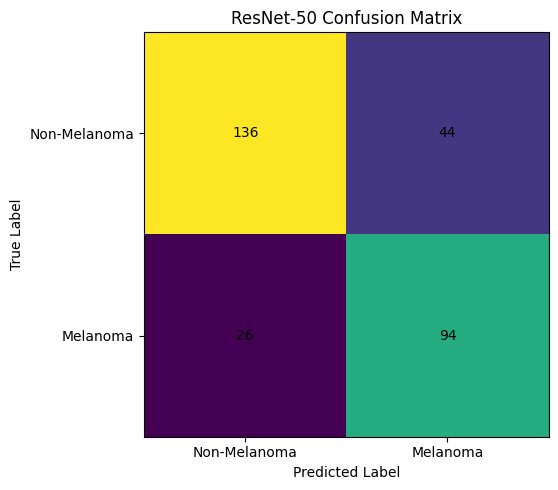

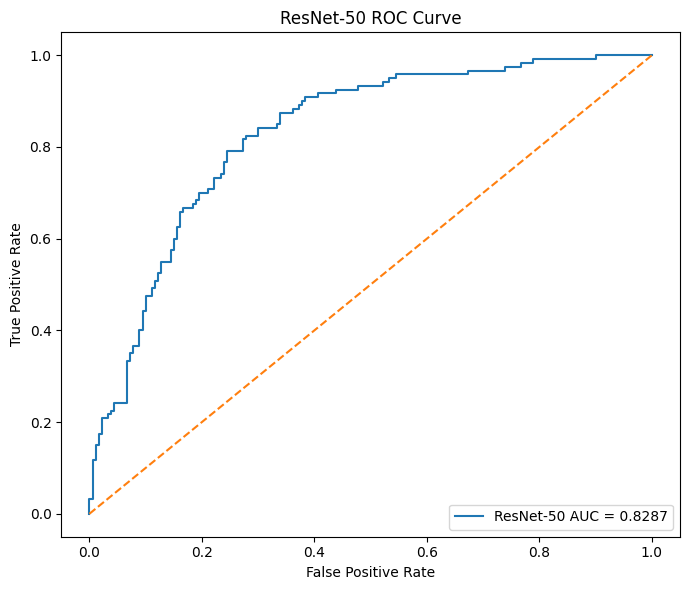


Image-level predictions saved:
/content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT/implement/results/resnet50/resnet50_test_image_predictions.csv

LESION-LEVEL EVALUATION

RESNET-50 LESION-LEVEL TEST RESULTS
Number of lesions: 150
Accuracy : 0.7933
Precision: 0.7101
Recall   : 0.8167
F1 Score : 0.7597
ROC-AUC  : 0.8469

LESION-LEVEL CLASSIFICATION REPORT
              precision    recall  f1-score   support

Non-Melanoma       0.86      0.78      0.82        90
    Melanoma       0.71      0.82      0.76        60

    accuracy                           0.79       150
   macro avg       0.79      0.80      0.79       150
weighted avg       0.80      0.79      0.80       150


Lesion-Level Confusion Matrix:
[[70 20]
 [11 49]]


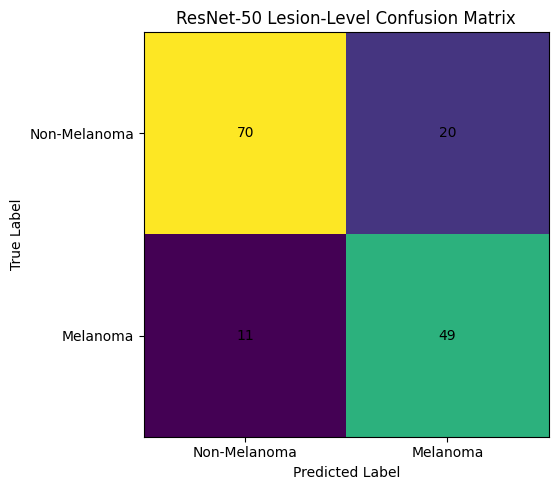


Lesion-level predictions saved:
/content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT/implement/results/resnet50/resnet50_test_lesion_predictions.csv

RESNET-50 TESTING COMPLETED

Model              : ResNet-50
Training            : From Scratch
Pretrained          : No
Transfer Learning   : No
Best Epoch          : 30

IMAGE-LEVEL TEST RESULTS
Accuracy            : 0.7667
Precision           : 0.6812
Recall              : 0.7833
F1 Score            : 0.7287
ROC-AUC             : 0.8287

LESION-LEVEL TEST RESULTS
Accuracy            : 0.7933
Precision           : 0.7101
Recall              : 0.8167
F1 Score            : 0.7597
ROC-AUC             : 0.8469

SAVED TESTING FILES

Results folder:
/content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT/implement/results/resnet50

Files:
✓ resnet50_best_model.pth
✓ resnet50_lesion_confusion_matrix.png
✓ resnet50_test_confusion_matrix.png
✓ resnet50_test_image_predictions.csv
✓ resnet50_test_lesion_predictions.csv
✓ resnet50_test_metrics.json
✓ resn

In [ ]:
# ============================================================
# RESNET-50 TESTING ONLY
# MILK10k MELANOMA CLASSIFICATION
#
# IMPORTANT:
#   This code DOES NOT train the model.
#   It loads the already trained ResNet-50 best model.
#
# Dataset:
#   1000 lesions
#   400 Melanoma
#   600 Non-Melanoma
#
# Test:
#   150 lesions
#   300 images
#   1 Clinical + 1 Dermoscopic image per lesion
#
# Model:
#   ResNet-50
#   Trained from scratch
#   No pretrained weights
# ============================================================


# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import os
import json
import numpy as np
import pandas as pd

from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)


# ============================================================
# 2. MOUNT GOOGLE DRIVE
# ============================================================

from google.colab import drive

drive.mount("/content/drive")


# ============================================================
# 3. PATHS
# ============================================================

BASE_PATH = "/content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT"

IMPLEMENT_PATH = os.path.join(
    BASE_PATH,
    "implement"
)

PREPARED_PATH = os.path.join(
    IMPLEMENT_PATH,
    "prepared_data"
)

RESULTS_PATH = os.path.join(
    IMPLEMENT_PATH,
    "results",
    "resnet50"
)

MODEL_PATH = os.path.join(
    RESULTS_PATH,
    "resnet50_best_model.pth"
)

TEST_CSV = os.path.join(
    PREPARED_PATH,
    "test_images.csv"
)

TRAIN_CSV = os.path.join(
    PREPARED_PATH,
    "train_images.csv"
)


print("=" * 70)
print("RESNET-50 TESTING")
print("=" * 70)

print("\nBase path:")
print(BASE_PATH)

print("\nTest CSV:")
print(TEST_CSV)

print("\nModel:")
print(MODEL_PATH)

print("\nResults folder:")
print(RESULTS_PATH)


# ============================================================
# 4. CHECK FILES
# ============================================================

if not os.path.exists(TEST_CSV):

    raise FileNotFoundError(
        f"Test CSV not found:\n{TEST_CSV}"
    )


if not os.path.exists(TRAIN_CSV):

    raise FileNotFoundError(
        f"Training CSV not found:\n{TRAIN_CSV}"
    )


if not os.path.exists(MODEL_PATH):

    raise FileNotFoundError(
        f"ResNet-50 model not found:\n{MODEL_PATH}"
    )


os.makedirs(
    RESULTS_PATH,
    exist_ok=True
)


print("\nAll required files found.")


# ============================================================
# 5. DEVICE
# ============================================================

if torch.cuda.is_available():

    device = torch.device("cuda")

    print(
        "\nGPU:",
        torch.cuda.get_device_name(0)
    )

else:

    device = torch.device("cpu")

    print("\nGPU not available.")
    print("Using CPU.")


# ============================================================
# 6. LOAD CSV FILES
# ============================================================

train_images = pd.read_csv(
    TRAIN_CSV
)

test_images = pd.read_csv(
    TEST_CSV
)


print("\n" + "=" * 70)
print("DATASET INFORMATION")
print("=" * 70)

print(
    "Training images:",
    len(train_images)
)

print(
    "Testing images:",
    len(test_images)
)


# ============================================================
# 7. VERIFY TEST DATA
# ============================================================

print("\nTest class distribution:")

print(
    test_images[
        "class_name"
    ].value_counts()
)


print("\nTest split:")

print(
    test_images[
        "split"
    ].value_counts()
)


# ============================================================
# 8. CALCULATE TRAINING MEAN / STD
#
# EXACTLY LIKE YOUR TRAINING CODE
#
# IMPORTANT:
# Mean/std are calculated ONLY from training images.
# Test images are NOT used for calculating normalization.
# ============================================================

print("\n" + "=" * 70)
print("CALCULATING TRAINING MEAN / STD")
print("=" * 70)


basic_transform = transforms.Compose([
    transforms.Resize(
        (224, 224)
    ),
    transforms.ToTensor()
])


mean_sum = torch.zeros(3)

std_sum = torch.zeros(3)

image_count = 0


for path in train_images["image_path"]:

    image = Image.open(
        path
    ).convert("RGB")

    image = basic_transform(
        image
    )

    mean = image.mean(
        dim=(1, 2)
    )

    std = image.std(
        dim=(1, 2)
    )

    mean_sum += mean

    std_sum += std

    image_count += 1


train_mean = (
    mean_sum /
    image_count
)

train_std = (
    std_sum /
    image_count
)


print(
    "Training mean:",
    train_mean.tolist()
)

print(
    "Training std:",
    train_std.tolist()
)


# ============================================================
# 9. TEST TRANSFORM
#
# EXACTLY MATCHES YOUR TRAINING CODE
# VALIDATION / TEST TRANSFORM
# ============================================================

test_transform = transforms.Compose([

    transforms.Resize(
        (224, 224)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=train_mean.tolist(),
        std=train_std.tolist()
    )
])


# ============================================================
# 10. TEST DATASET
# ============================================================

class MILK10kTestDataset(Dataset):

    def __init__(
        self,
        dataframe,
        transform=None
    ):

        self.dataframe = (
            dataframe
            .reset_index(drop=True)
        )

        self.transform = transform


    def __len__(self):

        return len(
            self.dataframe
        )


    def __getitem__(
        self,
        index
    ):

        row = self.dataframe.iloc[
            index
        ]

        image_path = row[
            "image_path"
        ]

        label = int(
            row[
                "binary_label"
            ]
        )

        image = Image.open(
            image_path
        ).convert("RGB")


        if self.transform is not None:

            image = self.transform(
                image
            )


        return image, label


# ============================================================
# 11. CREATE TEST DATASET
# ============================================================

test_dataset = MILK10kTestDataset(
    test_images,
    transform=test_transform
)


print("\n" + "=" * 70)
print("TEST DATASET")
print("=" * 70)

print(
    "Number of test images:",
    len(test_dataset)
)


# ============================================================
# 12. TEST DATALOADER
#
# SAME BATCH SIZE AS TRAINING
# ============================================================

BATCH_SIZE = 16

NUM_WORKERS = 2


test_loader = DataLoader(

    test_dataset,

    batch_size=BATCH_SIZE,

    shuffle=False,

    num_workers=NUM_WORKERS,

    pin_memory=torch.cuda.is_available()
)


print(
    "Batch size:",
    BATCH_SIZE
)

print(
    "Number of batches:",
    len(test_loader)
)


# ============================================================
# 13. CREATE RESNET-50
#
# MUST EXACTLY MATCH TRAINING MODEL
# ============================================================

print("\n" + "=" * 70)
print("CREATING RESNET-50")
print("=" * 70)


model = models.resnet50(
    weights=None
)


num_features = model.fc.in_features


model.fc = nn.Linear(
    num_features,
    2
)


model = model.to(
    device
)


print(
    "ResNet-50 created."
)

print(
    "Pretrained weights: NONE"
)

print(
    "Number of classes: 2"
)


# ============================================================
# 14. LOAD TRAINED MODEL
#
# IMPORTANT:
# weights_only=False is used because your checkpoint
# contains a dictionary with model_state_dict,
# optimizer_state_dict, epoch, etc.
# ============================================================

print("\n" + "=" * 70)
print("LOADING TRAINED RESNET-50")
print("=" * 70)


checkpoint = torch.load(

    MODEL_PATH,

    map_location=device,

    weights_only=False
)


print(
    "Checkpoint loaded successfully."
)


# Load trained model weights

model.load_state_dict(
    checkpoint[
        "model_state_dict"
    ]
)


model.eval()


print(
    "Best model loaded successfully."
)


# ============================================================
# 15. DISPLAY CHECKPOINT INFORMATION
# ============================================================

if "epoch" in checkpoint:

    print(
        "Best model epoch:",
        checkpoint["epoch"]
    )


if "validation_f1" in checkpoint:

    print(
        "Best validation F1:",
        f"{checkpoint['validation_f1']:.4f}"
    )


if "validation_auc" in checkpoint:

    print(
        "Best validation AUC:",
        f"{checkpoint['validation_auc']:.4f}"
    )


# ============================================================
# 16. TEST MODEL
# ============================================================

print("\n" + "=" * 70)
print("STARTING TESTING")
print("=" * 70)


all_labels = []

all_predictions = []

all_probabilities = []

all_lesion_ids = []

all_image_types = []

all_image_paths = []


with torch.no_grad():

    for batch_index, (
        images,
        labels
    ) in enumerate(test_loader):


        # Move images to device

        images = images.to(
            device,
            non_blocking=True
        )


        # Forward pass

        outputs = model(
            images
        )


        # Convert logits to probabilities

        probabilities = torch.softmax(
            outputs,
            dim=1
        )


        # Predicted class

        predictions = torch.argmax(
            outputs,
            dim=1
        )


        # ----------------------------------------------------
        # Find original rows from test dataframe
        # ----------------------------------------------------

        start_idx = (
            batch_index *
            test_loader.batch_size
        )

        end_idx = min(

            start_idx +
            images.size(0),

            len(
                test_loader.dataset
            )
        )


        batch_rows = (
            test_loader
            .dataset
            .dataframe
            .iloc[
                start_idx:end_idx
            ]
        )


        # ----------------------------------------------------
        # Store results
        # ----------------------------------------------------

        all_labels.extend(

            labels.cpu()
            .numpy()
            .tolist()

        )


        all_predictions.extend(

            predictions.cpu()
            .numpy()
            .tolist()

        )


        # Probability of Melanoma

        all_probabilities.extend(

            probabilities[:, 1]
            .cpu()
            .numpy()
            .tolist()

        )


        all_lesion_ids.extend(

            batch_rows[
                "lesion_id"
            ].tolist()

        )


        all_image_types.extend(

            batch_rows[
                "image_type"
            ].tolist()

        )


        all_image_paths.extend(

            batch_rows[
                "image_path"
            ].tolist()

        )


        print(
            f"Processed batch "
            f"{batch_index + 1}/"
            f"{len(test_loader)}"
        )


# ============================================================
# 17. CONVERT RESULTS TO NUMPY
# ============================================================

y_true = np.array(
    all_labels
)

y_pred = np.array(
    all_predictions
)

y_prob = np.array(
    all_probabilities
)


print("\nTesting completed.")

print(
    "Total test images:",
    len(y_true)
)


# ============================================================
# 18. IMAGE-LEVEL METRICS
# ============================================================

test_accuracy = accuracy_score(
    y_true,
    y_pred
)


test_precision = precision_score(
    y_true,
    y_pred,
    zero_division=0
)


test_recall = recall_score(
    y_true,
    y_pred,
    zero_division=0
)


test_f1 = f1_score(
    y_true,
    y_pred,
    zero_division=0
)


test_auc = roc_auc_score(
    y_true,
    y_prob
)


# ============================================================
# 19. PRINT IMAGE-LEVEL RESULTS
# ============================================================

print("\n" + "=" * 70)
print("RESNET-50 IMAGE-LEVEL TEST RESULTS")
print("=" * 70)


print(
    "Number of images:",
    len(y_true)
)


print(
    "Accuracy :",
    f"{test_accuracy:.4f}"
)


print(
    "Precision:",
    f"{test_precision:.4f}"
)


print(
    "Recall   :",
    f"{test_recall:.4f}"
)


print(
    "F1 Score :",
    f"{test_f1:.4f}"
)


print(
    "ROC-AUC  :",
    f"{test_auc:.4f}"
)


# ============================================================
# 20. CLASSIFICATION REPORT
# ============================================================

print("\n" + "=" * 70)
print("IMAGE-LEVEL CLASSIFICATION REPORT")
print("=" * 70)


classification_rep = classification_report(

    y_true,

    y_pred,

    target_names=[
        "Non-Melanoma",
        "Melanoma"
    ],

    zero_division=0
)


print(
    classification_rep
)


# ============================================================
# 21. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_true,
    y_pred
)


print("\n" + "=" * 70)
print("CONFUSION MATRIX")
print("=" * 70)


print(cm)


# ============================================================
# 22. SAVE CONFUSION MATRIX
# ============================================================

plt.figure(
    figsize=(6, 5)
)


plt.imshow(
    cm
)


plt.title(
    "ResNet-50 Confusion Matrix"
)


plt.xlabel(
    "Predicted Label"
)


plt.ylabel(
    "True Label"
)


plt.xticks(
    [0, 1],
    [
        "Non-Melanoma",
        "Melanoma"
    ]
)


plt.yticks(
    [0, 1],
    [
        "Non-Melanoma",
        "Melanoma"
    ]
)


for i in range(2):

    for j in range(2):

        plt.text(

            j,
            i,

            cm[i, j],

            ha="center",
            va="center"

        )


plt.tight_layout()


cm_path = os.path.join(

    RESULTS_PATH,

    "resnet50_test_confusion_matrix.png"

)


plt.savefig(

    cm_path,

    dpi=300,

    bbox_inches="tight"

)


plt.show()


# ============================================================
# 23. ROC CURVE
# ============================================================

fpr, tpr, thresholds = roc_curve(

    y_true,

    y_prob

)


plt.figure(
    figsize=(7, 6)
)


plt.plot(

    fpr,

    tpr,

    label=f"ResNet-50 AUC = {test_auc:.4f}"

)


plt.plot(

    [0, 1],

    [0, 1],

    linestyle="--"

)


plt.xlabel(
    "False Positive Rate"
)


plt.ylabel(
    "True Positive Rate"
)


plt.title(
    "ResNet-50 ROC Curve"
)


plt.legend(
    loc="lower right"
)


plt.tight_layout()


roc_path = os.path.join(

    RESULTS_PATH,

    "resnet50_test_roc_curve.png"

)


plt.savefig(

    roc_path,

    dpi=300,

    bbox_inches="tight"

)


plt.show()


# ============================================================
# 24. CREATE IMAGE-LEVEL PREDICTION DATAFRAME
# ============================================================

image_predictions = pd.DataFrame({

    "lesion_id":
        all_lesion_ids,

    "image_type":
        all_image_types,

    "image_path":
        all_image_paths,

    "true_label":
        y_true,

    "predicted_label":
        y_pred,

    "melanoma_probability":
        y_prob

})


# ============================================================
# 25. SAVE IMAGE-LEVEL PREDICTIONS
# ============================================================

image_predictions_path = os.path.join(

    RESULTS_PATH,

    "resnet50_test_image_predictions.csv"

)


image_predictions.to_csv(

    image_predictions_path,

    index=False

)


print(
    "\nImage-level predictions saved:"
)

print(
    image_predictions_path
)


# ============================================================
# 26. LESION-LEVEL EVALUATION
#
# Each lesion has:
#   Clinical image
#   Dermoscopic image
#
# We average the two melanoma probabilities.
# ============================================================

print("\n" + "=" * 70)
print("LESION-LEVEL EVALUATION")
print("=" * 70)


lesion_predictions = (

    image_predictions

    .groupby(
        "lesion_id"
    )

    .agg(

        true_label=(
            "true_label",
            "first"
        ),

        melanoma_probability=(
            "melanoma_probability",
            "mean"
        )

    )

    .reset_index()

)


# ============================================================
# 27. LESION-LEVEL PREDICTION
# ============================================================

lesion_predictions[
    "predicted_label"
] = (

    lesion_predictions[
        "melanoma_probability"
    ]

    >= 0.5

).astype(int)


lesion_true = (

    lesion_predictions[
        "true_label"
    ]

    .values

)


lesion_pred = (

    lesion_predictions[
        "predicted_label"
    ]

    .values

)


lesion_prob = (

    lesion_predictions[
        "melanoma_probability"
    ]

    .values

)


# ============================================================
# 28. LESION-LEVEL METRICS
# ============================================================

lesion_accuracy = accuracy_score(

    lesion_true,

    lesion_pred

)


lesion_precision = precision_score(

    lesion_true,

    lesion_pred,

    zero_division=0

)


lesion_recall = recall_score(

    lesion_true,

    lesion_pred,

    zero_division=0

)


lesion_f1 = f1_score(

    lesion_true,

    lesion_pred,

    zero_division=0

)


lesion_auc = roc_auc_score(

    lesion_true,

    lesion_prob

)


# ============================================================
# 29. PRINT LESION-LEVEL RESULTS
# ============================================================

print("\n" + "=" * 70)
print("RESNET-50 LESION-LEVEL TEST RESULTS")
print("=" * 70)


print(
    "Number of lesions:",
    len(lesion_predictions)
)


print(
    "Accuracy :",
    f"{lesion_accuracy:.4f}"
)


print(
    "Precision:",
    f"{lesion_precision:.4f}"
)


print(
    "Recall   :",
    f"{lesion_recall:.4f}"
)


print(
    "F1 Score :",
    f"{lesion_f1:.4f}"
)


print(
    "ROC-AUC  :",
    f"{lesion_auc:.4f}"
)


# ============================================================
# 30. LESION CLASSIFICATION REPORT
# ============================================================

print("\n" + "=" * 70)
print("LESION-LEVEL CLASSIFICATION REPORT")
print("=" * 70)


lesion_report = classification_report(

    lesion_true,

    lesion_pred,

    target_names=[
        "Non-Melanoma",
        "Melanoma"
    ],

    zero_division=0

)


print(
    lesion_report
)


# ============================================================
# 31. LESION CONFUSION MATRIX
# ============================================================

lesion_cm = confusion_matrix(

    lesion_true,

    lesion_pred

)


print("\nLesion-Level Confusion Matrix:")

print(
    lesion_cm
)


plt.figure(
    figsize=(6, 5)
)


plt.imshow(
    lesion_cm
)


plt.title(
    "ResNet-50 Lesion-Level Confusion Matrix"
)


plt.xlabel(
    "Predicted Label"
)


plt.ylabel(
    "True Label"
)


plt.xticks(

    [0, 1],

    [
        "Non-Melanoma",
        "Melanoma"
    ]

)


plt.yticks(

    [0, 1],

    [
        "Non-Melanoma",
        "Melanoma"
    ]

)


for i in range(2):

    for j in range(2):

        plt.text(

            j,
            i,

            lesion_cm[i, j],

            ha="center",
            va="center"

        )


plt.tight_layout()


lesion_cm_path = os.path.join(

    RESULTS_PATH,

    "resnet50_lesion_confusion_matrix.png"

)


plt.savefig(

    lesion_cm_path,

    dpi=300,

    bbox_inches="tight"

)


plt.show()


# ============================================================
# 32. SAVE LESION-LEVEL PREDICTIONS
# ============================================================

lesion_predictions_path = os.path.join(

    RESULTS_PATH,

    "resnet50_test_lesion_predictions.csv"

)


lesion_predictions.to_csv(

    lesion_predictions_path,

    index=False

)


print(
    "\nLesion-level predictions saved:"
)

print(
    lesion_predictions_path
)


# ============================================================
# 33. SAVE FINAL TEST METRICS
# ============================================================

final_test_metrics = {

    "model":
        "ResNet-50",

    "training":
        "From Scratch",

    "pretrained_weights":
        False,

    "transfer_learning":
        False,

    "input_size":
        "224x224",

    "test_images":
        int(len(y_true)),

    "test_lesions":
        int(len(lesion_predictions)),

    "best_epoch":
        int(
            checkpoint.get(
                "epoch",
                -1
            )
        ),

    "best_validation_f1":
        float(
            checkpoint.get(
                "validation_f1",
                0
            )
        ),

    "image_level": {

        "accuracy":
            float(test_accuracy),

        "precision":
            float(test_precision),

        "recall":
            float(test_recall),

        "f1":
            float(test_f1),

        "roc_auc":
            float(test_auc)

    },

    "lesion_level": {

        "accuracy":
            float(lesion_accuracy),

        "precision":
            float(lesion_precision),

        "recall":
            float(lesion_recall),

        "f1":
            float(lesion_f1),

        "roc_auc":
            float(lesion_auc)

    }

}


metrics_path = os.path.join(

    RESULTS_PATH,

    "resnet50_test_metrics.json"

)


with open(

    metrics_path,

    "w"

) as f:

    json.dump(

        final_test_metrics,

        f,

        indent=4

    )


# ============================================================
# 34. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("RESNET-50 TESTING COMPLETED")
print("=" * 70)


print(
    "\nModel              : ResNet-50"
)


print(
    "Training            : From Scratch"
)


print(
    "Pretrained          : No"
)


print(
    "Transfer Learning   : No"
)


print(
    "Best Epoch          :",
    checkpoint.get(
        "epoch",
        "Unknown"
    )
)


print("\nIMAGE-LEVEL TEST RESULTS")

print(
    "Accuracy            :",
    f"{test_accuracy:.4f}"
)


print(
    "Precision           :",
    f"{test_precision:.4f}"
)


print(
    "Recall              :",
    f"{test_recall:.4f}"
)


print(
    "F1 Score            :",
    f"{test_f1:.4f}"
)


print(
    "ROC-AUC             :",
    f"{test_auc:.4f}"
)


print("\nLESION-LEVEL TEST RESULTS")

print(
    "Accuracy            :",
    f"{lesion_accuracy:.4f}"
)


print(
    "Precision           :",
    f"{lesion_precision:.4f}"
)


print(
    "Recall              :",
    f"{lesion_recall:.4f}"
)


print(
    "F1 Score            :",
    f"{lesion_f1:.4f}"
)


print(
    "ROC-AUC             :",
    f"{lesion_auc:.4f}"
)


print("\n" + "=" * 70)
print("SAVED TESTING FILES")
print("=" * 70)


print(
    "\nResults folder:"
)

print(
    RESULTS_PATH
)


print(
    "\nFiles:"
)


for file in sorted(
    os.listdir(RESULTS_PATH)
):

    print(
        "✓",
        file
    )


print("\n" + "=" * 70)
print("DONE")
print("=" * 70)

In [ ]:
# ============================================================
# RESNET-50 - TESTING ON ALL 10,458 IMAGES
# ============================================================
# Uses the already trained ResNet-50 model
# No training / no epochs
#
# Dataset:
#   Training    : 7320
#   Validation  : 1568
#   Testing     : 1570
#   TOTAL       : 10458
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from PIL import Image

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    roc_curve
)

import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================
# 1. MOUNT GOOGLE DRIVE
# ============================================================

from google.colab import drive
drive.mount('/content/drive')

# ============================================================
# 2. PATHS
# ============================================================

BASE_PATH = "/content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT"

PREPARED_PATH = os.path.join(
    BASE_PATH,
    "implement",
    "prepared_data"
)

RESULTS_PATH = os.path.join(
    BASE_PATH,
    "implement",
    "results",
    "resnet50"
)

MODEL_PATH = os.path.join(
    RESULTS_PATH,
    "resnet50_best_model.pth"
)

# CSV files
TRAIN_CSV = os.path.join(
    PREPARED_PATH,
    "train_images.csv"
)

VAL_CSV = os.path.join(
    PREPARED_PATH,
    "validation_images.csv"
)

TEST_CSV = os.path.join(
    PREPARED_PATH,
    "test_images.csv"
)

# Output directory
ALL_TEST_RESULTS = os.path.join(
    RESULTS_PATH,
    "all_10458_test_results"
)

os.makedirs(ALL_TEST_RESULTS, exist_ok=True)

# ============================================================
# 3. DEVICE
# ============================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

# ============================================================
# 4. LOAD ALL CSV FILES
# ============================================================

train_df = pd.read_csv(TRAIN_CSV)
val_df = pd.read_csv(VAL_CSV)
test_df = pd.read_csv(TEST_CSV)

print("\nDataset sizes:")
print("-----------------------------")
print("Training images   :", len(train_df))
print("Validation images :", len(val_df))
print("Testing images    :", len(test_df))

# ============================================================
# 5. COMBINE ALL IMAGES
# ============================================================

all_df = pd.concat(
    [train_df, val_df, test_df],
    ignore_index=True
)

print("\nTOTAL IMAGES:", len(all_df))

print("\nAll dataset distribution:")
print(all_df["label"].value_counts())

print("\nSplit distribution:")
print(all_df["split"].value_counts())

# ============================================================
# 6. CALCULATE TRAINING MEAN AND STD
# ============================================================

print("\nCalculating training mean and standard deviation...")

temp_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

channel_sum = torch.zeros(3)
channel_squared_sum = torch.zeros(3)
num_pixels = 0

for i, row in train_df.iterrows():

    image_path = row["image_path"]

    try:
        image = Image.open(image_path).convert("RGB")
        image = temp_transform(image)

        pixels = image.shape[1] * image.shape[2]

        channel_sum += image.sum(dim=(1, 2))
        channel_squared_sum += (image ** 2).sum(dim=(1, 2))

        num_pixels += pixels

    except Exception as e:
        print("Error:", image_path)
        print(e)

train_mean = channel_sum / num_pixels

train_std = torch.sqrt(
    (channel_squared_sum / num_pixels)
    - (train_mean ** 2)
)

print("\nTraining Mean:", train_mean)
print("Training Std :", train_std)

# ============================================================
# 7. TRANSFORM
# ============================================================

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=train_mean.tolist(),
        std=train_std.tolist()
    )
])

# ============================================================
# 8. DATASET
# ============================================================

class MelanomaDataset(Dataset):

    def __init__(self, dataframe, transform=None):

        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        image_path = row["image_path"]

        image = Image.open(
            image_path
        ).convert("RGB")

        if self.transform:
            image = self.transform(image)

        label = int(row["label"])

        return (
            image,
            label,
            image_path,
            row["lesion_id"],
            row["split"]
        )

# ============================================================
# 9. CREATE ALL DATASET
# ============================================================

all_dataset = MelanomaDataset(
    all_df,
    transform=test_transform
)

all_loader = DataLoader(
    all_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("\nDataLoader created.")
print("Total images:", len(all_dataset))

# ============================================================
# 10. CREATE RESNET-50
# ============================================================

print("\nCreating ResNet-50...")

model = models.resnet50(
    weights=None
)

# 2 classes:
# 0 = Non-Melanoma
# 1 = Melanoma

model.fc = nn.Linear(
    model.fc.in_features,
    2
)

model = model.to(device)

# ============================================================
# 11. LOAD TRAINED MODEL
# ============================================================

print("\nLoading trained model...")

checkpoint = torch.load(
    MODEL_PATH,
    map_location=device,
    weights_only=False
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()

print("Model loaded successfully.")

if "epoch" in checkpoint:
    print("Best model epoch:", checkpoint["epoch"])

if "validation_f1" in checkpoint:
    print(
        "Validation F1:",
        checkpoint["validation_f1"]
    )

if "validation_auc" in checkpoint:
    print(
        "Validation AUC:",
        checkpoint["validation_auc"]
    )

# ============================================================
# 12. TEST ON ALL 10,458 IMAGES
# ============================================================

print("\nRunning prediction on ALL images...")
print("------------------------------------")

all_true = []
all_pred = []
all_prob = []

all_paths = []
all_lesions = []
all_splits = []

with torch.no_grad():

    for batch_idx, batch in enumerate(all_loader):

        images = batch[0]
        labels = batch[1]
        paths = batch[2]
        lesions = batch[3]
        splits = batch[4]

        images = images.to(device)

        outputs = model(images)

        probabilities = torch.softmax(
            outputs,
            dim=1
        )

        melanoma_probability = probabilities[:, 1]

        predictions = torch.argmax(
            probabilities,
            dim=1
        )

        all_true.extend(
            labels.numpy()
        )

        all_pred.extend(
            predictions.cpu().numpy()
        )

        all_prob.extend(
            melanoma_probability.cpu().numpy()
        )

        all_paths.extend(paths)
        all_lesions.extend(lesions)
        all_splits.extend(splits)

        if (batch_idx + 1) % 20 == 0:
            processed = min(
                (batch_idx + 1) * 32,
                len(all_dataset)
            )

            print(
                f"Processed: {processed}/{len(all_dataset)}"
            )

print("\nPrediction completed.")

# ============================================================
# 13. CONVERT TO NUMPY
# ============================================================

all_true = np.array(all_true)
all_pred = np.array(all_pred)
all_prob = np.array(all_prob)

# ============================================================
# 14. METRICS - ALL 10,458 IMAGES
# ============================================================

accuracy = accuracy_score(
    all_true,
    all_pred
)

precision = precision_score(
    all_true,
    all_pred,
    zero_division=0
)

recall = recall_score(
    all_true,
    all_pred,
    zero_division=0
)

f1 = f1_score(
    all_true,
    all_pred,
    zero_division=0
)

auc = roc_auc_score(
    all_true,
    all_prob
)

print("\n")
print("=" * 60)
print("RESULTS - ALL 10,458 IMAGES")
print("=" * 60)

print(f"Total Images : {len(all_true)}")
print(f"Accuracy     : {accuracy:.4f}")
print(f"Precision    : {precision:.4f}")
print(f"Recall       : {recall:.4f}")
print(f"F1 Score     : {f1:.4f}")
print(f"ROC-AUC      : {auc:.4f}")

# ============================================================
# 15. CLASSIFICATION REPORT
# ============================================================

print("\nClassification Report")
print("-----------------------------")

print(
    classification_report(
        all_true,
        all_pred,
        target_names=[
            "Non-Melanoma",
            "Melanoma"
        ],
        digits=4,
        zero_division=0
    )
)

# ============================================================
# 16. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    all_true,
    all_pred
)

print("\nConfusion Matrix")
print("-----------------------------")
print(cm)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Non-Melanoma",
        "Melanoma"
    ],
    yticklabels=[
        "Non-Melanoma",
        "Melanoma"
    ]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("ResNet-50 Confusion Matrix - All 10,458 Images")

plt.tight_layout()

cm_path = os.path.join(
    ALL_TEST_RESULTS,
    "all_images_confusion_matrix.png"
)

plt.savefig(
    cm_path,
    dpi=300
)

plt.show()

# ============================================================
# 17. ROC CURVE
# ============================================================

fpr, tpr, thresholds = roc_curve(
    all_true,
    all_prob
)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    label=f"ResNet-50 AUC = {auc:.4f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - All 10,458 Images")

plt.legend()

plt.tight_layout()

roc_path = os.path.join(
    ALL_TEST_RESULTS,
    "all_images_roc_curve.png"
)

plt.savefig(
    roc_path,
    dpi=300
)

plt.show()

# ============================================================
# 18. SAVE PREDICTIONS
# ============================================================

prediction_df = pd.DataFrame({

    "lesion_id": all_lesions,

    "image_path": all_paths,

    "split": all_splits,

    "actual_label": all_true,

    "predicted_label": all_pred,

    "melanoma_probability": all_prob,

    "predicted_class": [
        "Melanoma" if x == 1
        else "Non-Melanoma"
        for x in all_pred
    ]

})

prediction_csv = os.path.join(
    ALL_TEST_RESULTS,
    "all_10458_image_predictions.csv"
)

prediction_df.to_csv(
    prediction_csv,
    index=False
)

print("\nPredictions saved:")
print(prediction_csv)

# ============================================================
# 19. METRICS BY SPLIT
# ============================================================

print("\n")
print("=" * 60)
print("METRICS FOR EACH SPLIT")
print("=" * 60)

split_results = []

for split_name in [
    "train",
    "validation",
    "test"
]:

    mask = (
        np.array(all_splits) == split_name
    )

    y_true_split = all_true[mask]
    y_pred_split = all_pred[mask]
    y_prob_split = all_prob[mask]

    split_accuracy = accuracy_score(
        y_true_split,
        y_pred_split
    )

    split_precision = precision_score(
        y_true_split,
        y_pred_split,
        zero_division=0
    )

    split_recall = recall_score(
        y_true_split,
        y_pred_split,
        zero_division=0
    )

    split_f1 = f1_score(
        y_true_split,
        y_pred_split,
        zero_division=0
    )

    split_auc = roc_auc_score(
        y_true_split,
        y_prob_split
    )

    print(f"\n{split_name.upper()}")
    print("-----------------------------")
    print("Images    :", len(y_true_split))
    print(f"Accuracy  : {split_accuracy:.4f}")
    print(f"Precision : {split_precision:.4f}")
    print(f"Recall    : {split_recall:.4f}")
    print(f"F1        : {split_f1:.4f}")
    print(f"ROC-AUC   : {split_auc:.4f}")

    split_results.append({

        "split": split_name,

        "images": len(y_true_split),

        "accuracy": split_accuracy,

        "precision": split_precision,

        "recall": split_recall,

        "f1": split_f1,

        "roc_auc": split_auc

    })

# ============================================================
# 20. SAVE SPLIT METRICS
# ============================================================

split_metrics_df = pd.DataFrame(
    split_results
)

split_metrics_csv = os.path.join(
    ALL_TEST_RESULTS,
    "metrics_by_split.csv"
)

split_metrics_df.to_csv(
    split_metrics_csv,
    index=False
)

# ============================================================
# 21. SAVE FINAL METRICS
# ============================================================

final_metrics = {

    "model": "ResNet-50",

    "weights": "trained from scratch",

    "total_images": len(all_true),

    "training_images": int(
        (np.array(all_splits) == "train").sum()
    ),

    "validation_images": int(
        (np.array(all_splits) == "validation").sum()
    ),

    "testing_images": int(
        (np.array(all_splits) == "test").sum()
    ),

    "accuracy": float(accuracy),

    "precision": float(precision),

    "recall": float(recall),

    "f1_score": float(f1),

    "roc_auc": float(auc)

}

metrics_json = os.path.join(
    ALL_TEST_RESULTS,
    "all_10458_final_metrics.json"
)

with open(
    metrics_json,
    "w"
) as f:

    json.dump(
        final_metrics,
        f,
        indent=4
    )

# ============================================================
# 22. FINAL SUMMARY
# ============================================================

print("\n")
print("=" * 60)
print("FINAL SUMMARY")
print("=" * 60)

print("Model              : ResNet-50")
print("Training images    : 7,320")
print("Validation images  : 1,568")
print("Testing images     : 1,570")
print("TOTAL IMAGES       : 10,458")

print("\nALL IMAGE RESULTS")
print("-----------------------------")
print(f"Accuracy           : {accuracy:.4f}")
print(f"Precision          : {precision:.4f}")
print(f"Recall             : {recall:.4f}")
print(f"F1 Score           : {f1:.4f}")
print(f"ROC-AUC            : {auc:.4f}")

print("\nResults saved in:")
print(ALL_TEST_RESULTS)

print("\nDone.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device: cpu

Dataset sizes:
-----------------------------
Training images   : 1400
Validation images : 300
Testing images    : 300

TOTAL IMAGES: 2000

All dataset distribution:


KeyError: 'label'

In [ ]:
import pandas as pd
import os

PREPARED_PATH = "/content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT/implement/prepared_data"

for file in [
    "train_images.csv",
    "validation_images.csv",
    "test_images.csv"
]:
    path = os.path.join(PREPARED_PATH, file)

    df = pd.read_csv(path)

    print("\n", file)
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    print(df.head(2))


 train_images.csv
Shape: (1400, 6)
Columns: ['lesion_id', 'image_path', 'image_type', 'binary_label', 'class_name', 'split']
    lesion_id                                         image_path   image_type  \
0  IL_2194640  /content/drive/MyDrive/MELANOMA/PREDICTIVE PRO...     Clinical   
1  IL_2194640  /content/drive/MyDrive/MELANOMA/PREDICTIVE PRO...  Dermoscopic   

   binary_label    class_name  split  
0             0  Non-Melanoma  train  
1             0  Non-Melanoma  train  

 validation_images.csv
Shape: (300, 6)
Columns: ['lesion_id', 'image_path', 'image_type', 'binary_label', 'class_name', 'split']
    lesion_id                                         image_path   image_type  \
0  IL_7108184  /content/drive/MyDrive/MELANOMA/PREDICTIVE PRO...     Clinical   
1  IL_7108184  /content/drive/MyDrive/MELANOMA/PREDICTIVE PRO...  Dermoscopic   

   binary_label    class_name       split  
0             0  Non-Melanoma  validation  
1             0  Non-Melanoma  validation  

 test_

In [ ]:
import os

BASE_PATH = "/content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT"

for root, dirs, files in os.walk(BASE_PATH):

    for file in files:

        if file.endswith(".csv"):

            path = os.path.join(root, file)

            try:
                import pandas as pd

                df = pd.read_csv(path)

                if len(df) > 5000:

                    print("\nFOUND CSV")
                    print("File:", path)
                    print("Shape:", df.shape)
                    print("Columns:", df.columns.tolist())

            except:
                pass


FOUND CSV
File: /content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT/implement/prepared_data_B4/all_valid_lesions.csv
Shape: (5229, 6)
Columns: ['lesion_id', 'clinical_image', 'dermoscopic_image', 'MEL', 'binary_label', 'class_name']

FOUND CSV
File: /content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT/implement/prepared_data_B4/train_images.csv
Shape: (7320, 6)
Columns: ['lesion_id', 'image_path', 'image_type', 'binary_label', 'class_name', 'split']

FOUND CSV
File: /content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT/implement/prepared_data_B4/all_images.csv
Shape: (10458, 6)
Columns: ['lesion_id', 'image_path', 'image_type', 'binary_label', 'class_name', 'split']

FOUND CSV
File: /content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT/data/ISIC_2024_Training_GroundTruth.csv
Shape: (401059, 2)
Columns: ['isic_id', 'malignant']

FOUND CSV
File: /content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT/data/ISIC_2024_Permissive_Training_GroundTruth.csv
Shape: (217477, 2)
Columns: ['isic_id', 'malignant

/tmp/ipykernel_2304/2841443884.py:16: DtypeWarning: Columns (9) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(path)



FOUND CSV
File: /content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT/data/2024/ISIC_2024_Training_Supplement.csv
Shape: (401059, 13)
Columns: ['isic_id', 'attribution', 'copyright_license', 'lesion_id', 'iddx_full', 'iddx_1', 'iddx_2', 'iddx_3', 'iddx_4', 'iddx_5', 'mel_mitotic_index', 'mel_thick_mm', 'tbp_lv_dnn_lesion_confidence']

FOUND CSV
File: /content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT/data/2019/ISIC_2019_Training_GroundTruth.csv
Shape: (25331, 10)
Columns: ['image', 'MEL', 'NV', 'BCC', 'AK', 'BKL', 'DF', 'VASC', 'SCC', 'UNK']

FOUND CSV
File: /content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT/data/2019/ISIC_2019_Training_Metadata.csv
Shape: (25331, 5)
Columns: ['image', 'age_approx', 'anatom_site_general', 'lesion_id', 'sex']

FOUND CSV
File: /content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT/data/2019/ISIC_2019_Test_GroundTruth.csv
Shape: (8238, 12)
Columns: ['image', 'MEL', 'NV', 'BCC', 'AK', 'BKL', 'DF', 'VASC', 'SCC', 'UNK', 'score_weight', 'validation_weight']

FOUND

KeyboardInterrupt: 

In [ ]:
# ============================================================
# RESNET-50 TESTING - ALL 10,458 IMAGES
# ============================================================

import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from PIL import Image

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# ============================================================
# 1. PATHS
# ============================================================

BASE_PATH = "/content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT"

DATA_PATH = os.path.join(
    BASE_PATH,
    "implement",
    "prepared_data_B4"
)

ALL_CSV = os.path.join(
    DATA_PATH,
    "all_images.csv"
)

MODEL_PATH = os.path.join(
    DATA_PATH,
    "..",
    "results",
    "resnet50",
    "resnet50_best_model.pth"
)

# Normalize path
MODEL_PATH = os.path.abspath(MODEL_PATH)

print("CSV:")
print(ALL_CSV)

print("\nMODEL:")
print(MODEL_PATH)

# ============================================================
# 2. DEVICE
# ============================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("\nDevice:", device)

# ============================================================
# 3. LOAD ALL 10,458 IMAGES
# ============================================================

df = pd.read_csv(ALL_CSV)

print("\nDataset shape:", df.shape)
print("Columns:", df.columns.tolist())

print("\nSplit distribution:")
print(df["split"].value_counts())

print("\nClass distribution:")
print(df["binary_label"].value_counts())

# ============================================================
# 4. TRANSFORM
# ============================================================

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# ============================================================
# 5. DATASET
# ============================================================

class MelanomaDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        image = Image.open(
            row["image_path"]
        ).convert("RGB")

        if self.transform:
            image = self.transform(image)

        label = int(row["binary_label"])

        return image, label, idx


dataset = MelanomaDataset(
    df,
    transform=transform
)

loader = DataLoader(
    dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("\nTotal images to test:", len(dataset))

# ============================================================
# 6. CREATE RESNET-50
# ============================================================

model = models.resnet50(
    weights=None
)

model.fc = nn.Linear(
    model.fc.in_features,
    2
)

model = model.to(device)

# ============================================================
# 7. LOAD TRAINED MODEL
# ============================================================

print("\nLoading trained ResNet-50...")

checkpoint = torch.load(
    MODEL_PATH,
    map_location=device,
    weights_only=False
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()

print("Model loaded successfully.")

if "epoch" in checkpoint:
    print("Checkpoint epoch:", checkpoint["epoch"])

if "validation_f1" in checkpoint:
    print("Validation F1:", checkpoint["validation_f1"])

# ============================================================
# 8. PREDICT ALL 10,458 IMAGES
# ============================================================

all_labels = []
all_predictions = []
all_probabilities = []

print("\nTesting all 10,458 images...")

with torch.no_grad():

    for batch_no, (images, labels, indices) in enumerate(loader):

        images = images.to(device)

        outputs = model(images)

        probabilities = torch.softmax(
            outputs,
            dim=1
        )

        melanoma_prob = probabilities[:, 1]

        predictions = torch.argmax(
            probabilities,
            dim=1
        )

        all_labels.extend(
            labels.numpy()
        )

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_probabilities.extend(
            melanoma_prob.cpu().numpy()
        )

        if (batch_no + 1) % 25 == 0:

            done = min(
                (batch_no + 1) * 32,
                len(dataset)
            )

            print(
                f"Processed {done}/{len(dataset)}"
            )

# ============================================================
# 9. METRICS
# ============================================================

y_true = np.array(all_labels)
y_pred = np.array(all_predictions)
y_prob = np.array(all_probabilities)

accuracy = accuracy_score(
    y_true,
    y_pred
)

precision = precision_score(
    y_true,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_true,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_true,
    y_pred,
    zero_division=0
)

auc = roc_auc_score(
    y_true,
    y_prob
)

# ============================================================
# 10. PRINT RESULTS
# ============================================================

print("\n")
print("=" * 60)
print("RESNET-50 RESULTS - ALL 10,458 IMAGES")
print("=" * 60)

print("Total Images :", len(y_true))
print("Accuracy     :", round(accuracy, 4))
print("Precision    :", round(precision, 4))
print("Recall       :", round(recall, 4))
print("F1 Score     :", round(f1, 4))
print("ROC-AUC      :", round(auc, 4))

# ============================================================
# 11. CLASSIFICATION REPORT
# ============================================================

print("\nClassification Report")
print("=" * 60)

print(
    classification_report(
        y_true,
        y_pred,
        target_names=[
            "Non-Melanoma",
            "Melanoma"
        ],
        digits=4,
        zero_division=0
    )
)

# ============================================================
# 12. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_true,
    y_pred
)

print("\nConfusion Matrix")
print("=" * 60)

print(cm)

# ============================================================
# 13. RESULTS BY SPLIT
# ============================================================

df["actual_label"] = y_true
df["predicted_label"] = y_pred
df["melanoma_probability"] = y_prob

print("\n")
print("=" * 60)
print("RESULTS BY SPLIT")
print("=" * 60)

for split in ["train", "validation", "test"]:

    subset = df[
        df["split"] == split
    ]

    yt = subset["actual_label"]
    yp = subset["predicted_label"]
    yp_prob = subset["melanoma_probability"]

    print("\n", split.upper())
    print("-" * 40)

    print("Images:", len(subset))

    print(
        "Accuracy:",
        round(
            accuracy_score(yt, yp),
            4
        )
    )

    print(
        "Precision:",
        round(
            precision_score(
                yt,
                yp,
                zero_division=0
            ),
            4
        )
    )

    print(
        "Recall:",
        round(
            recall_score(
                yt,
                yp,
                zero_division=0
            ),
            4
        )
    )

    print(
        "F1:",
        round(
            f1_score(
                yt,
                yp,
                zero_division=0
            ),
            4
        )
    )

    print(
        "AUC:",
        round(
            roc_auc_score(
                yt,
                yp_prob
            ),
            4
        )
    )

# ============================================================
# 14. SAVE PREDICTIONS
# ============================================================

OUTPUT_PATH = os.path.join(
    BASE_PATH,
    "implement",
    "results",
    "resnet50",
    "all_10458_predictions.csv"
)

df.to_csv(
    OUTPUT_PATH,
    index=False
)

print("\nPredictions saved to:")
print(OUTPUT_PATH)

print("\nDONE.")

CSV:
/content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT/implement/prepared_data_B4/all_images.csv

MODEL:
/content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT/implement/results/resnet50/resnet50_best_model.pth

Device: cpu

Dataset shape: (10458, 6)
Columns: ['lesion_id', 'image_path', 'image_type', 'binary_label', 'class_name', 'split']

Split distribution:
split
train         7320
test          1570
validation    1568
Name: count, dtype: int64

Class distribution:
binary_label
0    9558
1     900
Name: count, dtype: int64

Total images to test: 10458

Loading trained ResNet-50...
Model loaded successfully.
Checkpoint epoch: 30
Validation F1: 0.7720588235294118

Testing all 10,458 images...


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Processed 800/10458
Processed 1600/10458
Processed 2400/10458
Processed 3200/10458
Processed 4000/10458
Processed 4800/10458
Processed 5600/10458
Processed 6400/10458
Processed 7200/10458
Processed 8000/10458
Processed 8800/10458
Processed 9600/10458
Processed 10400/10458


RESNET-50 RESULTS - ALL 10,458 IMAGES
Total Images : 10458
Accuracy     : 0.8773
Precision    : 0.2542
Recall       : 0.22
F1 Score     : 0.2359
ROC-AUC      : 0.7041

Classification Report
              precision    recall  f1-score   support

Non-Melanoma     0.9275    0.9392    0.9333      9558
    Melanoma     0.2542    0.2200    0.2359       900

    accuracy                         0.8773     10458
   macro avg     0.5908    0.5796    0.5846     10458
weighted avg     0.8695    0.8773    0.8733     10458


Confusion Matrix
[[8977  581]
 [ 702  198]]


RESULTS BY SPLIT

 TRAIN
----------------------------------------
Images: 7320
Accuracy: 0.8769
Precision: 0.2567
Recall: 0.227
F1: 0.2409
AUC: 0.6992

 VALIDATI

In [ ]:

# ============================================================
# RESNET-50 - MELANOMA CLASSIFICATION
#
# DATASET: MILK10k Prepared Dataset
# TRAINING: COMPLETELY FROM SCRATCH
# PRETRAINED WEIGHTS: NO
# TRANSFER LEARNING: NO
#
# Each lesion has exactly 2 images.
# Both images are passed through the SAME ResNet-50.
# Their logits are averaged for one lesion-level prediction.
#
# EPOCHS: 30
# EARLY STOPPING: DISABLED
# ============================================================


# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import os
import random
import json
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import resnet50

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    roc_curve,
    classification_report
)

from IPython.display import display


# ============================================================
# 2. GOOGLE DRIVE
# ============================================================

from google.colab import drive

if not os.path.exists("/content/drive/MyDrive"):
    drive.mount("/content/drive")

print("Google Drive ready.")


# ============================================================
# 3. PATHS
# ============================================================

BASE_PATH = (
    "/content/drive/MyDrive/"
    "MELANOMA/PREDICTIVE PROJECT"
)

DATA_PATH = os.path.join(
    BASE_PATH,
    "data",
    "MILK10k_Prepared"
)

CSV_PATH = os.path.join(
    DATA_PATH,
    "MILK10k_final_dataset.csv"
)

REPORT_DIR = os.path.join(
    BASE_PATH,
    "implement",
    "results",
    "resnet50_30_epochs"
)

os.makedirs(
    REPORT_DIR,
    exist_ok=True
)

print("CSV path:", CSV_PATH)
print("Report directory:", REPORT_DIR)

if not os.path.exists(CSV_PATH):
    raise FileNotFoundError(
        f"CSV not found: {CSV_PATH}"
    )


# ============================================================
# 4. RANDOM SEED
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Random seed:", SEED)


# ============================================================
# 5. DEVICE
# ============================================================

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("\nDevice:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA:", torch.version.cuda)
else:
    print("WARNING: GPU unavailable. Training will use CPU.")


# ============================================================
# 6. LOAD CSV
# ============================================================

df = pd.read_csv(CSV_PATH)

print("\nDataset shape:", df.shape)
print("Columns:", df.columns.tolist())

display(df.head())

required_columns = [
    "lesion_id",
    "image_path",
    "label",
    "class_name",
    "split"
]

missing_columns = [
    column for column in required_columns
    if column not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing CSV columns: {missing_columns}"
    )


# ============================================================
# 7. CLEAN AND VALIDATE CSV
# ============================================================

df["split"] = (
    df["split"].astype(str).str.strip().str.lower()
)

df["lesion_id"] = df["lesion_id"].astype(str)

df["label"] = pd.to_numeric(
    df["label"],
    errors="raise"
)

if df["label"].isna().any():
    raise ValueError("Missing labels detected.")

if not set(df["label"].unique()).issubset({0, 1}):
    raise ValueError(
        "Labels must be binary: 0 = Non-Melanoma, "
        "1 = Melanoma."
    )

df["label"] = df["label"].astype(int)

if df["image_path"].duplicated().any():
    raise ValueError("Duplicate image paths detected.")

if df["image_path"].isna().any():
    raise ValueError("Missing image paths detected.")

print("\nImage-level label distribution:")
print(df["label"].value_counts())

print("\nImage-level split distribution:")
print(df["split"].value_counts())


# ============================================================
# 8. RESOLVE IMAGE PATHS
# ============================================================

def resolve_image_path(path):

    path = str(path).strip()

    candidates = [
        path,
        os.path.join(DATA_PATH, path),
        os.path.join(BASE_PATH, path)
    ]

    for candidate in candidates:
        if os.path.isfile(candidate):
            return os.path.abspath(candidate)

    return None


df["resolved_path"] = df["image_path"].apply(
    resolve_image_path
)

missing_images = df[
    df["resolved_path"].isna()
]["image_path"].tolist()

print("\nTotal image rows:", len(df))
print("Missing images:", len(missing_images))

if missing_images:
    print("First missing paths:", missing_images[:10])
    raise FileNotFoundError(
        "Some images cannot be found. Check CSV paths."
    )

print("All images found.")


# ============================================================
# 9. VERIFY TWO IMAGES PER LESION
# ============================================================

lesion_counts = df.groupby("lesion_id").size()

print("\nTotal unique lesions:", len(lesion_counts))
print("Images per lesion:")
print(lesion_counts.value_counts())

if not (lesion_counts == 2).all():
    raise ValueError(
        "Every lesion must contain exactly two images."
    )


# ============================================================
# 10. VERIFY LESION LABEL, CLASS AND SPLIT
# ============================================================

for column in ["label", "class_name", "split"]:

    inconsistent = (
        df.groupby("lesion_id")[column].nunique() > 1
    )

    if inconsistent.any():
        raise ValueError(
            f"Inconsistent {column} values within lesions."
        )

print("Lesion consistency checks passed.")


# ============================================================
# 11. CREATE LESION-LEVEL DATASET
# ============================================================

lesion_records = []

for lesion_id, group in df.groupby(
    "lesion_id",
    sort=False
):

    group = group.sort_values(
        "resolved_path"
    ).reset_index(drop=True)

    lesion_records.append({
        "lesion_id": str(lesion_id),
        "image1": group.loc[0, "resolved_path"],
        "image2": group.loc[1, "resolved_path"],
        "label": int(group.loc[0, "label"]),
        "class_name": str(group.loc[0, "class_name"]),
        "split": str(group.loc[0, "split"])
    })

lesion_df = pd.DataFrame(lesion_records)

print("\nTotal lesions:", len(lesion_df))
print("\nLesion-level label distribution:")
print(lesion_df["label"].value_counts())
print("\nLesion-level split distribution:")
print(lesion_df["split"].value_counts())

display(lesion_df.head())


# ============================================================
# 12. SPLIT INTO TRAIN / VALIDATION / TEST
# ============================================================

train_df = lesion_df[
    lesion_df["split"] == "train"
].copy()

val_df = lesion_df[
    lesion_df["split"].isin(["validation", "val"])
].copy()

test_df = lesion_df[
    lesion_df["split"] == "test"
].copy()

print("\nTraining lesions:", len(train_df))
print("Validation lesions:", len(val_df))
print("Test lesions:", len(test_df))

if len(train_df) == 0:
    raise ValueError("Training split is empty.")

if len(val_df) == 0:
    raise ValueError("Validation split is empty.")

if len(test_df) == 0:
    raise ValueError("Test split is empty.")


# ============================================================
# 13. CHECK DATA LEAKAGE
# ============================================================

train_ids = set(train_df["lesion_id"])
val_ids = set(val_df["lesion_id"])
test_ids = set(test_df["lesion_id"])

assert not (train_ids & val_ids), "Train-validation leakage!"
assert not (train_ids & test_ids), "Train-test leakage!"
assert not (val_ids & test_ids), "Validation-test leakage!"

print("Lesion-level leakage check: PASSED")


# ============================================================
# 14. IMAGE TRANSFORMS
# ============================================================

IMAGE_SIZE = 224

NORMALIZE_MEAN = [0.485, 0.456, 0.406]
NORMALIZE_STD = [0.229, 0.224, 0.225]

# Augmentation is applied only to training images.
train_transform = transforms.Compose([

    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),

    transforms.RandomHorizontalFlip(p=0.5),

    transforms.RandomVerticalFlip(p=0.5),

    transforms.RandomRotation(degrees=15),

    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=NORMALIZE_MEAN,
        std=NORMALIZE_STD
    )
])

# Validation and test images are not augmented.
val_test_transform = transforms.Compose([

    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=NORMALIZE_MEAN,
        std=NORMALIZE_STD
    )
])


# ============================================================
# 15. LESION DATASET
# ============================================================

class LesionDataset(Dataset):

    def __init__(self, dataframe, transform=None):

        self.data = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):

        row = self.data.iloc[index]

        image1 = Image.open(
            row["image1"]
        ).convert("RGB")

        image2 = Image.open(
            row["image2"]
        ).convert("RGB")

        if self.transform is not None:

            image1 = self.transform(image1)
            image2 = self.transform(image2)

        label = torch.tensor(
            float(row["label"]),
            dtype=torch.float32
        )

        return (
            image1,
            image2,
            label,
            str(row["lesion_id"])
        )


# ============================================================
# 16. CREATE DATASETS
# ============================================================

train_dataset = LesionDataset(
    train_df,
    train_transform
)

val_dataset = LesionDataset(
    val_df,
    val_test_transform
)

test_dataset = LesionDataset(
    test_df,
    val_test_transform
)


# ============================================================
# 17. DATA LOADERS
# ============================================================

BATCH_SIZE = 16

# Set NUM_WORKERS to 2 for Colab.
# If workers cause issues, change it to 0.

NUM_WORKERS = 2

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

print("\nBatch size (lesions):", BATCH_SIZE)
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))


# ============================================================
# 18. CREATE RESNET-50 FROM SCRATCH
# ============================================================

# weights=None guarantees no pretrained ImageNet weights.
# The final fully connected layer produces one binary logit.

model = resnet50(weights=None)

in_features = model.fc.in_features

model.fc = nn.Linear(
    in_features,
    1
)

model = model.to(DEVICE)

print("\nModel: ResNet-50")
print("Pretrained weights: NO")
print("Transfer learning: NO")
print("Output classes: 1 binary logit")
print("Input size: 224 x 224")

total_parameters = sum(
    p.numel() for p in model.parameters()
)

trainable_parameters = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(f"Total parameters: {total_parameters:,}")
print(f"Trainable parameters: {trainable_parameters:,}")


# ============================================================
# 19. CLASS BALANCE AND LOSS
# ============================================================

positive_count = int(train_df["label"].sum())

negative_count = len(train_df) - positive_count

print("\nTraining class balance:")
print("Non-Melanoma:", negative_count)
print("Melanoma:", positive_count)

if positive_count == 0 or negative_count == 0:
    raise ValueError(
        "Training set must contain both classes."
    )

pos_weight_value = negative_count / positive_count

pos_weight = torch.tensor(
    [pos_weight_value],
    dtype=torch.float32,
    device=DEVICE
)

criterion = nn.BCEWithLogitsLoss(
    pos_weight=pos_weight
)

print("Positive class weight:", pos_weight_value)


# ============================================================
# 20. OPTIMIZER AND SCHEDULER
# ============================================================

EPOCHS = 30

LEARNING_RATE = 3e-4

WEIGHT_DECAY = 1e-4

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=EPOCHS
)

print("\nOptimizer: AdamW")
print("Learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)
print("Scheduler: CosineAnnealingLR")
print("Epochs:", EPOCHS)
print("Early stopping: DISABLED")


# ============================================================
# 21. TRAIN ONE EPOCH
# ============================================================

def train_one_epoch(model, loader, criterion, optimizer):

    model.train()

    running_loss = 0.0
    all_labels = []
    all_predictions = []

    for image1, image2, labels, lesion_ids in loader:

        image1 = image1.to(
            DEVICE,
            non_blocking=True
        )

        image2 = image2.to(
            DEVICE,
            non_blocking=True
        )

        labels = labels.to(
            DEVICE,
            non_blocking=True
        )

        optimizer.zero_grad(set_to_none=True)

        # Both images use the same ResNet-50.
        output1 = model(image1).squeeze(1)
        output2 = model(image2).squeeze(1)

        # One prediction per lesion.
        logits = (output1 + output2) / 2.0

        loss = criterion(logits, labels)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        running_loss += loss.item() * labels.size(0)

        probabilities = torch.sigmoid(logits)

        predictions = (probabilities >= 0.5).int()

        all_labels.extend(
            labels.detach().cpu().numpy().astype(int).tolist()
        )

        all_predictions.extend(
            predictions.detach().cpu().numpy().tolist()
        )

    epoch_loss = running_loss / len(loader.dataset)

    epoch_accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    return epoch_loss, epoch_accuracy


# ============================================================
# 22. VALIDATION FUNCTION
# ============================================================

def validate(model, loader, criterion):

    model.eval()

    running_loss = 0.0

    all_labels = []
    all_probabilities = []

    with torch.no_grad():

        for image1, image2, labels, lesion_ids in loader:

            image1 = image1.to(
                DEVICE,
                non_blocking=True
            )

            image2 = image2.to(
                DEVICE,
                non_blocking=True
            )

            labels = labels.to(
                DEVICE,
                non_blocking=True
            )

            output1 = model(image1).squeeze(1)
            output2 = model(image2).squeeze(1)

            logits = (output1 + output2) / 2.0

            loss = criterion(logits, labels)

            running_loss += loss.item() * labels.size(0)

            probabilities = torch.sigmoid(logits)

            all_labels.extend(
                labels.cpu().numpy().astype(int).tolist()
            )

            all_probabilities.extend(
                probabilities.cpu().numpy().tolist()
            )

    epoch_loss = running_loss / len(loader.dataset)

    if len(set(all_labels)) == 2:
        epoch_auc = roc_auc_score(
            all_labels,
            all_probabilities
        )
    else:
        epoch_auc = float("nan")

    return (
        epoch_loss,
        epoch_auc,
        all_labels,
        all_probabilities
    )


# ============================================================
# 23. TRAINING HISTORY AND CHECKPOINT
# ============================================================

history = {
    "epoch": [],
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_roc_auc": [],
    "learning_rate": []
}

best_val_auc = -1.0

best_model_path = os.path.join(
    REPORT_DIR,
    "resnet50_30_epochs_best.pth"
)

last_model_path = os.path.join(
    REPORT_DIR,
    "resnet50_30_epochs_last.pth"
)


# ============================================================
# 24. TRAINING LOOP
# ============================================================

print("\n" + "=" * 65)
print("STARTING RESNET-50 TRAINING")
print("=" * 65)

for epoch in range(1, EPOCHS + 1):

    train_loss, train_accuracy = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer
    )

    (
        val_loss,
        val_auc,
        val_labels,
        val_probabilities
    ) = validate(
        model,
        val_loader,
        criterion
    )

    current_lr = optimizer.param_groups[0]["lr"]

    history["epoch"].append(epoch)
    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_loss"].append(val_loss)
    history["val_roc_auc"].append(val_auc)
    history["learning_rate"].append(current_lr)

    # Save the best checkpoint based on validation ROC-AUC.
    if np.isfinite(val_auc) and val_auc > best_val_auc:

        best_val_auc = val_auc

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "val_roc_auc": val_auc,
                "model_name": "ResNet-50",
                "pretrained": False,
                "image_size": IMAGE_SIZE
            },
            best_model_path
        )

        best_marker = " <-- BEST"

    else:
        best_marker = ""

    scheduler.step()

    print(
        f"Epoch [{epoch:02d}/{EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val AUC: {val_auc:.4f} | "
        f"LR: {current_lr:.7f}"
        f"{best_marker}"
    )

    # Save the most recent checkpoint as well.
    torch.save(
        {
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "val_roc_auc": val_auc,
            "model_name": "ResNet-50",
            "pretrained": False,
            "image_size": IMAGE_SIZE
        },
        last_model_path
    )

if best_val_auc < 0:
    raise RuntimeError(
        "No valid best model was saved. Check validation labels."
    )


# ============================================================
# 25. SAVE TRAINING HISTORY
# ============================================================

history_df = pd.DataFrame(history)

history_path = os.path.join(
    REPORT_DIR,
    "resnet50_training_history.csv"
)

history_df.to_csv(
    history_path,
    index=False
)

print("\nTraining history saved:", history_path)


# ============================================================
# 26. LOAD BEST MODEL
# ============================================================

print("\nLoading best ResNet-50 model...")

# weights_only=False is needed for checkpoints containing
# metadata such as epoch and optimizer state in some PyTorch
# versions. Only load a checkpoint you created and trust.

try:
    checkpoint = torch.load(
        best_model_path,
        map_location=DEVICE,
        weights_only=True
    )
except TypeError:
    # Compatibility with older PyTorch versions.
    checkpoint = torch.load(
        best_model_path,
        map_location=DEVICE
    )

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()

print("Best epoch:", checkpoint["epoch"])
print("Best validation ROC-AUC:", checkpoint["val_roc_auc"])
print("Best model:", best_model_path)


# ============================================================
# 27. TEST FUNCTION
# ============================================================

def test_model(model, loader, criterion):

    model.eval()

    running_loss = 0.0

    all_labels = []
    all_probabilities = []
    all_predictions = []
    all_lesion_ids = []

    with torch.no_grad():

        for image1, image2, labels, lesion_ids in loader:

            image1 = image1.to(
                DEVICE,
                non_blocking=True
            )

            image2 = image2.to(
                DEVICE,
                non_blocking=True
            )

            labels = labels.to(
                DEVICE,
                non_blocking=True
            )

            output1 = model(image1).squeeze(1)
            output2 = model(image2).squeeze(1)

            logits = (output1 + output2) / 2.0

            loss = criterion(logits, labels)

            running_loss += loss.item() * labels.size(0)

            probabilities = torch.sigmoid(logits)

            predictions = (probabilities >= 0.5).int()

            all_labels.extend(
                labels.cpu().numpy().astype(int).tolist()
            )

            all_probabilities.extend(
                probabilities.cpu().numpy().tolist()
            )

            all_predictions.extend(
                predictions.cpu().numpy().tolist()
            )

            all_lesion_ids.extend(list(lesion_ids))

    test_loss = running_loss / len(loader.dataset)

    return (
        test_loss,
        all_labels,
        all_probabilities,
        all_predictions,
        all_lesion_ids
    )


# ============================================================
# 28. TEST BEST MODEL
# ============================================================

print("\n" + "=" * 65)
print("TESTING BEST RESNET-50 MODEL")
print("=" * 65)

(
    test_loss,
    test_labels,
    test_probabilities,
    test_predictions,
    test_lesion_ids
) = test_model(
    model,
    test_loader,
    criterion
)


# ============================================================
# 29. CALCULATE TEST METRICS
# ============================================================

test_accuracy = accuracy_score(
    test_labels,
    test_predictions
)

test_precision = precision_score(
    test_labels,
    test_predictions,
    zero_division=0
)

test_recall = recall_score(
    test_labels,
    test_predictions,
    zero_division=0
)

test_f1 = f1_score(
    test_labels,
    test_predictions,
    zero_division=0
)

if len(set(test_labels)) == 2:
    test_auc = roc_auc_score(
        test_labels,
        test_probabilities
    )
else:
    test_auc = float("nan")


# ============================================================
# 30. PRINT FINAL TEST RESULTS
# ============================================================

print("\n" + "=" * 65)
print("FINAL LESION-LEVEL TEST RESULTS")
print("=" * 65)

print(f"Test Loss : {test_loss:.4f}")
print(f"Accuracy  : {test_accuracy:.4f}")
print(f"Precision : {test_precision:.4f}")
print(f"Recall    : {test_recall:.4f}")
print(f"F1 Score  : {test_f1:.4f}")
print(f"ROC-AUC   : {test_auc:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        test_labels,
        test_predictions,
        labels=[0, 1],
        target_names=["Non-Melanoma", "Melanoma"],
        zero_division=0
    )
)


# ============================================================
# 31. SAVE TEST METRICS
# ============================================================

metrics_df = pd.DataFrame({
    "Metric": [
        "Loss",
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ],
    "Value": [
        test_loss,
        test_accuracy,
        test_precision,
        test_recall,
        test_f1,
        test_auc
    ]
})

metrics_path = os.path.join(
    REPORT_DIR,
    "resnet50_final_test_metrics.csv"
)

metrics_df.to_csv(
    metrics_path,
    index=False
)


# ============================================================
# 32. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    test_labels,
    test_predictions,
    labels=[0, 1]
)

print("\nConfusion Matrix:")
print(cm)

cm_df = pd.DataFrame(
    cm,
    index=["Actual Non-Melanoma", "Actual Melanoma"],
    columns=["Predicted Non-Melanoma", "Predicted Melanoma"]
)

cm_path = os.path.join(
    REPORT_DIR,
    "resnet50_confusion_matrix.csv"
)

cm_df.to_csv(cm_path)


# ============================================================
# 33. SAVE LESION-LEVEL PREDICTIONS
# ============================================================

prediction_df = pd.DataFrame({
    "lesion_id": test_lesion_ids,
    "actual_label": test_labels,
    "predicted_probability": test_probabilities,
    "predicted_label": test_predictions
})

prediction_path = os.path.join(
    REPORT_DIR,
    "resnet50_lesion_level_test_predictions.csv"
)

prediction_df.to_csv(
    prediction_path,
    index=False
)


# ============================================================
# 34. SAVE LESION-LEVEL DATASET
# ============================================================

lesion_dataset_path = os.path.join(
    REPORT_DIR,
    "resnet50_lesion_level_dataset.csv"
)

lesion_df.to_csv(
    lesion_dataset_path,
    index=False
)


# ============================================================
# 35. TRAINING AND VALIDATION LOSS CURVE
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    history["epoch"],
    history["train_loss"],
    label="Training Loss"
)

plt.plot(
    history["epoch"],
    history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ResNet-50 Training and Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

loss_plot_path = os.path.join(
    REPORT_DIR,
    "resnet50_loss_curve.png"
)

plt.savefig(loss_plot_path, dpi=300)
plt.show()
plt.close()


# ============================================================
# 36. TRAINING ACCURACY CURVE
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    history["epoch"],
    history["train_accuracy"],
    label="Training Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("ResNet-50 Training Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

accuracy_plot_path = os.path.join(
    REPORT_DIR,
    "resnet50_training_accuracy.png"
)

plt.savefig(accuracy_plot_path, dpi=300)
plt.show()
plt.close()


# ============================================================
# 37. VALIDATION ROC-AUC CURVE
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    history["epoch"],
    history["val_roc_auc"],
    label="Validation ROC-AUC"
)

plt.xlabel("Epoch")
plt.ylabel("ROC-AUC")
plt.title("ResNet-50 Validation ROC-AUC")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

val_auc_plot_path = os.path.join(
    REPORT_DIR,
    "resnet50_validation_roc_auc.png"
)

plt.savefig(val_auc_plot_path, dpi=300)
plt.show()
plt.close()


# ============================================================
# 38. TEST ROC CURVE
# ============================================================

if len(set(test_labels)) == 2:

    fpr, tpr, thresholds = roc_curve(
        test_labels,
        test_probabilities
    )

    plt.figure(figsize=(7, 6))

    plt.plot(
        fpr,
        tpr,
        label=f"ROC-AUC = {test_auc:.4f}"
    )

    plt.plot(
        [0, 1],
        [0, 1],
        linestyle="--"
    )

    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ResNet-50 Test ROC Curve")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()

    roc_plot_path = os.path.join(
        REPORT_DIR,
        "resnet50_test_roc_curve.png"
    )

    plt.savefig(roc_plot_path, dpi=300)
    plt.show()
    plt.close()


# ============================================================
# 39. CONFUSION MATRIX PLOT
# ============================================================

plt.figure(figsize=(6, 5))

plt.imshow(cm)

plt.title("ResNet-50 Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.xticks(
    [0, 1],
    ["Non-Melanoma", "Melanoma"],
    rotation=15
)

plt.yticks(
    [0, 1],
    ["Non-Melanoma", "Melanoma"]
)

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            str(cm[i, j]),
            ha="center",
            va="center"
        )

plt.colorbar()
plt.tight_layout()

cm_plot_path = os.path.join(
    REPORT_DIR,
    "resnet50_confusion_matrix.png"
)

plt.savefig(cm_plot_path, dpi=300)
plt.show()
plt.close()


# ============================================================
# 40. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 65)
print("RESNET-50 TRAINING COMPLETED")
print("=" * 65)

print("Dataset: MILK10k")
print("Task: Melanoma Classification")
print("Model: ResNet-50")
print("Training: From scratch")
print("Pretrained weights: NO")
print("Transfer learning: NO")
print("Images per lesion: 2")
print("Input image size: 224 x 224")
print("Batch size:", BATCH_SIZE, "lesions")
print("Epochs:", EPOCHS)
print("Optimizer: AdamW")
print("Scheduler: CosineAnnealingLR")
print("Early stopping: DISABLED")

print("\nFINAL TEST RESULTS")
print(f"Accuracy  : {test_accuracy:.4f}")
print(f"Precision : {test_precision:.4f}")
print(f"Recall    : {test_recall:.4f}")
print(f"F1 Score  : {test_f1:.4f}")
print(f"ROC-AUC   : {test_auc:.4f}")

print("\nSAVED FILES")
print("Best model:", best_model_path)
print("Last model:", last_model_path)
print("Training history:", history_path)
print("Test metrics:", metrics_path)
print("Confusion matrix:", cm_path)
print("Test predictions:", prediction_path)
print("Lesion dataset:", lesion_dataset_path)
print("Reports folder:", REPORT_DIR)

print("\nAll outputs are saved in Google Drive.")
print("=" * 65)

Google Drive ready.
CSV path: /content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT/data/MILK10k_Prepared/MILK10k_final_dataset.csv
Report directory: /content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT/implement/results/resnet50_30_epochs
Random seed: 42

Device: cuda
GPU: Tesla T4
CUDA: 13.0

Dataset shape: (10458, 5)
Columns: ['lesion_id', 'image_path', 'label', 'class_name', 'split']


,lesion_id,image_path,label,class_name,split
0,IL_0000652,/content/drive/MyDrive/MELANOMA/PREDICTIVE PRO...,0,Non-Melanoma,train
1,IL_0000652,/content/drive/MyDrive/MELANOMA/PREDICTIVE PRO...,0,Non-Melanoma,train
2,IL_0003176,/content/drive/MyDrive/MELANOMA/PREDICTIVE PRO...,0,Non-Melanoma,train
3,IL_0003176,/content/drive/MyDrive/MELANOMA/PREDICTIVE PRO...,0,Non-Melanoma,train
4,IL_0004688,/content/drive/MyDrive/MELANOMA/PREDICTIVE PRO...,0,Non-Melanoma,train



Image-level label distribution:
label
0    9558
1     900
Name: count, dtype: int64

Image-level split distribution:
split
train         7320
test          1570
validation    1568
Name: count, dtype: int64

Total image rows: 10458
Missing images: 0
All images found.

Total unique lesions: 5229
Images per lesion:
2    5229
Name: count, dtype: int64
Lesion consistency checks passed.

Total lesions: 5229

Lesion-level label distribution:
label
0    4779
1     450
Name: count, dtype: int64

Lesion-level split distribution:
split
train         3660
test           785
validation     784
Name: count, dtype: int64


,lesion_id,image1,image2,label,class_name,split
0,IL_0000652,/content/drive/MyDrive/MELANOMA/PREDICTIVE PRO...,/content/drive/MyDrive/MELANOMA/PREDICTIVE PRO...,0,Non-Melanoma,train
1,IL_0003176,/content/drive/MyDrive/MELANOMA/PREDICTIVE PRO...,/content/drive/MyDrive/MELANOMA/PREDICTIVE PRO...,0,Non-Melanoma,train
2,IL_0004688,/content/drive/MyDrive/MELANOMA/PREDICTIVE PRO...,/content/drive/MyDrive/MELANOMA/PREDICTIVE PRO...,0,Non-Melanoma,train
3,IL_0005081,/content/drive/MyDrive/MELANOMA/PREDICTIVE PRO...,/content/drive/MyDrive/MELANOMA/PREDICTIVE PRO...,0,Non-Melanoma,validation
4,IL_0006177,/content/drive/MyDrive/MELANOMA/PREDICTIVE PRO...,/content/drive/MyDrive/MELANOMA/PREDICTIVE PRO...,0,Non-Melanoma,validation



Training lesions: 3660
Validation lesions: 784
Test lesions: 785
Lesion-level leakage check: PASSED

Batch size (lesions): 16
Training batches: 229
Validation batches: 49
Test batches: 50

Model: ResNet-50
Pretrained weights: NO
Transfer learning: NO
Output classes: 1 binary logit
Input size: 224 x 224
Total parameters: 23,510,081
Trainable parameters: 23,510,081

Training class balance:
Non-Melanoma: 3345
Melanoma: 315
Positive class weight: 10.619047619047619

Optimizer: AdamW
Learning rate: 0.0003
Weight decay: 0.0001
Scheduler: CosineAnnealingLR
Epochs: 30
Early stopping: DISABLED

STARTING RESNET-50 TRAINING


KeyboardInterrupt: 

In [ ]:

# ============================================================
# RESNET-50 - MELANOMA CLASSIFICATION
#
# DATASET: MILK10k Prepared Dataset
# TRAINING: COMPLETELY FROM SCRATCH
# PRETRAINED WEIGHTS: NO
# TRANSFER LEARNING: NO
#
# Each lesion has exactly 2 images.
# Both images are passed through the SAME ResNet-50.
# Their logits are averaged for one lesion-level prediction.
#
# EPOCHS: 30
# EARLY STOPPING: DISABLED
# ============================================================


# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import os
import random
import json
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import resnet50

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    roc_curve,
    classification_report
)

from IPython.display import display


# ============================================================
# 2. GOOGLE DRIVE
# ============================================================

from google.colab import drive

if not os.path.exists("/content/drive/MyDrive"):
    drive.mount("/content/drive")

print("Google Drive ready.")


# ============================================================
# 3. PATHS
# ============================================================

BASE_PATH = (
    "/content/drive/MyDrive/"
    "MELANOMA/PREDICTIVE PROJECT"
)

DATA_PATH = os.path.join(
    BASE_PATH,
    "data",
    "MILK10k_Prepared"
)

CSV_PATH = os.path.join(
    DATA_PATH,
    "MILK10k_final_dataset.csv"
)

REPORT_DIR = os.path.join(
    BASE_PATH,
    "implement",
    "results",
    "resnet50_30_epochs"
)

os.makedirs(
    REPORT_DIR,
    exist_ok=True
)

print("CSV path:", CSV_PATH)
print("Report directory:", REPORT_DIR)

if not os.path.exists(CSV_PATH):
    raise FileNotFoundError(
        f"CSV not found: {CSV_PATH}"
    )


# ============================================================
# 4. RANDOM SEED
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Random seed:", SEED)


# ============================================================
# 5. DEVICE
# ============================================================

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("\nDevice:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA:", torch.version.cuda)
else:
    print("WARNING: GPU unavailable. Training will use CPU.")


# ============================================================
# 6. LOAD CSV
# ============================================================

df = pd.read_csv(CSV_PATH)

print("\nDataset shape:", df.shape)
print("Columns:", df.columns.tolist())

display(df.head())

required_columns = [
    "lesion_id",
    "image_path",
    "label",
    "class_name",
    "split"
]

missing_columns = [
    column for column in required_columns
    if column not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing CSV columns: {missing_columns}"
    )


# ============================================================
# 7. CLEAN AND VALIDATE CSV
# ============================================================

df["split"] = (
    df["split"].astype(str).str.strip().str.lower()
)

df["lesion_id"] = df["lesion_id"].astype(str)

df["label"] = pd.to_numeric(
    df["label"],
    errors="raise"
)

if df["label"].isna().any():
    raise ValueError("Missing labels detected.")

if not set(df["label"].unique()).issubset({0, 1}):
    raise ValueError(
        "Labels must be binary: 0 = Non-Melanoma, "
        "1 = Melanoma."
    )

df["label"] = df["label"].astype(int)

if df["image_path"].duplicated().any():
    raise ValueError("Duplicate image paths detected.")

if df["image_path"].isna().any():
    raise ValueError("Missing image paths detected.")

print("\nImage-level label distribution:")
print(df["label"].value_counts())

print("\nImage-level split distribution:")
print(df["split"].value_counts())


# ============================================================
# 8. RESOLVE IMAGE PATHS
# ============================================================

def resolve_image_path(path):

    path = str(path).strip()

    candidates = [
        path,
        os.path.join(DATA_PATH, path),
        os.path.join(BASE_PATH, path)
    ]

    for candidate in candidates:
        if os.path.isfile(candidate):
            return os.path.abspath(candidate)

    return None


df["resolved_path"] = df["image_path"].apply(
    resolve_image_path
)

missing_images = df[
    df["resolved_path"].isna()
]["image_path"].tolist()

print("\nTotal image rows:", len(df))
print("Missing images:", len(missing_images))

if missing_images:
    print("First missing paths:", missing_images[:10])
    raise FileNotFoundError(
        "Some images cannot be found. Check CSV paths."
    )

print("All images found.")


# ============================================================
# 9. VERIFY TWO IMAGES PER LESION
# ============================================================

lesion_counts = df.groupby("lesion_id").size()

print("\nTotal unique lesions:", len(lesion_counts))
print("Images per lesion:")
print(lesion_counts.value_counts())

if not (lesion_counts == 2).all():
    raise ValueError(
        "Every lesion must contain exactly two images."
    )


# ============================================================
# 10. VERIFY LESION LABEL, CLASS AND SPLIT
# ============================================================

for column in ["label", "class_name", "split"]:

    inconsistent = (
        df.groupby("lesion_id")[column].nunique() > 1
    )

    if inconsistent.any():
        raise ValueError(
            f"Inconsistent {column} values within lesions."
        )

print("Lesion consistency checks passed.")


# ============================================================
# 11. CREATE LESION-LEVEL DATASET
# ============================================================

lesion_records = []

for lesion_id, group in df.groupby(
    "lesion_id",
    sort=False
):

    group = group.sort_values(
        "resolved_path"
    ).reset_index(drop=True)

    lesion_records.append({
        "lesion_id": str(lesion_id),
        "image1": group.loc[0, "resolved_path"],
        "image2": group.loc[1, "resolved_path"],
        "label": int(group.loc[0, "label"]),
        "class_name": str(group.loc[0, "class_name"]),
        "split": str(group.loc[0, "split"])
    })

lesion_df = pd.DataFrame(lesion_records)

print("\nTotal lesions:", len(lesion_df))
print("\nLesion-level label distribution:")
print(lesion_df["label"].value_counts())
print("\nLesion-level split distribution:")
print(lesion_df["split"].value_counts())

display(lesion_df.head())


# ============================================================
# 12. SPLIT INTO TRAIN / VALIDATION / TEST
# ============================================================

train_df = lesion_df[
    lesion_df["split"] == "train"
].copy()

val_df = lesion_df[
    lesion_df["split"].isin(["validation", "val"])
].copy()

test_df = lesion_df[
    lesion_df["split"] == "test"
].copy()

print("\nTraining lesions:", len(train_df))
print("Validation lesions:", len(val_df))
print("Test lesions:", len(test_df))

if len(train_df) == 0:
    raise ValueError("Training split is empty.")

if len(val_df) == 0:
    raise ValueError("Validation split is empty.")

if len(test_df) == 0:
    raise ValueError("Test split is empty.")


# ============================================================
# 13. CHECK DATA LEAKAGE
# ============================================================

train_ids = set(train_df["lesion_id"])
val_ids = set(val_df["lesion_id"])
test_ids = set(test_df["lesion_id"])

assert not (train_ids & val_ids), "Train-validation leakage!"
assert not (train_ids & test_ids), "Train-test leakage!"
assert not (val_ids & test_ids), "Validation-test leakage!"

print("Lesion-level leakage check: PASSED")


# ============================================================
# 14. IMAGE TRANSFORMS
# ============================================================

IMAGE_SIZE = 224

NORMALIZE_MEAN = [0.485, 0.456, 0.406]
NORMALIZE_STD = [0.229, 0.224, 0.225]

# Augmentation is applied only to training images.
train_transform = transforms.Compose([

    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),

    transforms.RandomHorizontalFlip(p=0.5),

    transforms.RandomVerticalFlip(p=0.5),

    transforms.RandomRotation(degrees=15),

    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=NORMALIZE_MEAN,
        std=NORMALIZE_STD
    )
])

# Validation and test images are not augmented.
val_test_transform = transforms.Compose([

    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=NORMALIZE_MEAN,
        std=NORMALIZE_STD
    )
])


# ============================================================
# 15. LESION DATASET
# ============================================================

class LesionDataset(Dataset):

    def __init__(self, dataframe, transform=None):

        self.data = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):

        row = self.data.iloc[index]

        image1 = Image.open(
            row["image1"]
        ).convert("RGB")

        image2 = Image.open(
            row["image2"]
        ).convert("RGB")

        if self.transform is not None:

            image1 = self.transform(image1)
            image2 = self.transform(image2)

        label = torch.tensor(
            float(row["label"]),
            dtype=torch.float32
        )

        return (
            image1,
            image2,
            label,
            str(row["lesion_id"])
        )


# ============================================================
# 16. CREATE DATASETS
# ============================================================

train_dataset = LesionDataset(
    train_df,
    train_transform
)

val_dataset = LesionDataset(
    val_df,
    val_test_transform
)

test_dataset = LesionDataset(
    test_df,
    val_test_transform
)


# ============================================================
# 17. DATA LOADERS
# ============================================================

BATCH_SIZE = 16

# Set NUM_WORKERS to 2 for Colab.
# If workers cause issues, change it to 0.

NUM_WORKERS = 2

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

print("\nBatch size (lesions):", BATCH_SIZE)
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))


# ============================================================
# 18. CREATE RESNET-50 FROM SCRATCH
# ============================================================

# weights=None guarantees no pretrained ImageNet weights.
# The final fully connected layer produces one binary logit.

model = resnet50(weights=None)

in_features = model.fc.in_features

model.fc = nn.Linear(
    in_features,
    1
)

model = model.to(DEVICE)

print("\nModel: ResNet-50")
print("Pretrained weights: NO")
print("Transfer learning: NO")
print("Output classes: 1 binary logit")
print("Input size: 224 x 224")

total_parameters = sum(
    p.numel() for p in model.parameters()
)

trainable_parameters = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(f"Total parameters: {total_parameters:,}")
print(f"Trainable parameters: {trainable_parameters:,}")


# ============================================================
# 19. CLASS BALANCE AND LOSS
# ============================================================

positive_count = int(train_df["label"].sum())

negative_count = len(train_df) - positive_count

print("\nTraining class balance:")
print("Non-Melanoma:", negative_count)
print("Melanoma:", positive_count)

if positive_count == 0 or negative_count == 0:
    raise ValueError(
        "Training set must contain both classes."
    )

pos_weight_value = negative_count / positive_count

pos_weight = torch.tensor(
    [pos_weight_value],
    dtype=torch.float32,
    device=DEVICE
)

criterion = nn.BCEWithLogitsLoss(
    pos_weight=pos_weight
)

print("Positive class weight:", pos_weight_value)


# ============================================================
# 20. OPTIMIZER AND SCHEDULER
# ============================================================

EPOCHS = 30

LEARNING_RATE = 3e-4

WEIGHT_DECAY = 1e-4

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=EPOCHS
)

print("\nOptimizer: AdamW")
print("Learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)
print("Scheduler: CosineAnnealingLR")
print("Epochs:", EPOCHS)
print("Early stopping: DISABLED")


# ============================================================
# 21. TRAIN ONE EPOCH
# ============================================================

def train_one_epoch(model, loader, criterion, optimizer):

    model.train()

    running_loss = 0.0
    all_labels = []
    all_predictions = []

    for image1, image2, labels, lesion_ids in loader:

        image1 = image1.to(
            DEVICE,
            non_blocking=True
        )

        image2 = image2.to(
            DEVICE,
            non_blocking=True
        )

        labels = labels.to(
            DEVICE,
            non_blocking=True
        )

        optimizer.zero_grad(set_to_none=True)

        # Both images use the same ResNet-50.
        output1 = model(image1).squeeze(1)
        output2 = model(image2).squeeze(1)

        # One prediction per lesion.
        logits = (output1 + output2) / 2.0

        loss = criterion(logits, labels)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        running_loss += loss.item() * labels.size(0)

        probabilities = torch.sigmoid(logits)

        predictions = (probabilities >= 0.5).int()

        all_labels.extend(
            labels.detach().cpu().numpy().astype(int).tolist()
        )

        all_predictions.extend(
            predictions.detach().cpu().numpy().tolist()
        )

    epoch_loss = running_loss / len(loader.dataset)

    epoch_accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    return epoch_loss, epoch_accuracy


# ============================================================
# 22. VALIDATION FUNCTION
# ============================================================

def validate(model, loader, criterion):

    model.eval()

    running_loss = 0.0

    all_labels = []
    all_probabilities = []

    with torch.no_grad():

        for image1, image2, labels, lesion_ids in loader:

            image1 = image1.to(
                DEVICE,
                non_blocking=True
            )

            image2 = image2.to(
                DEVICE,
                non_blocking=True
            )

            labels = labels.to(
                DEVICE,
                non_blocking=True
            )

            output1 = model(image1).squeeze(1)
            output2 = model(image2).squeeze(1)

            logits = (output1 + output2) / 2.0

            loss = criterion(logits, labels)

            running_loss += loss.item() * labels.size(0)

            probabilities = torch.sigmoid(logits)

            all_labels.extend(
                labels.cpu().numpy().astype(int).tolist()
            )

            all_probabilities.extend(
                probabilities.cpu().numpy().tolist()
            )

    epoch_loss = running_loss / len(loader.dataset)

    if len(set(all_labels)) == 2:
        epoch_auc = roc_auc_score(
            all_labels,
            all_probabilities
        )
    else:
        epoch_auc = float("nan")

    return (
        epoch_loss,
        epoch_auc,
        all_labels,
        all_probabilities
    )


# ============================================================
# 23. TRAINING HISTORY AND CHECKPOINT
# ============================================================

history = {
    "epoch": [],
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_roc_auc": [],
    "learning_rate": []
}

best_val_auc = -1.0

best_model_path = os.path.join(
    REPORT_DIR,
    "resnet50_30_epochs_best.pth"
)

last_model_path = os.path.join(
    REPORT_DIR,
    "resnet50_30_epochs_last.pth"
)


# ============================================================
# 24. TRAINING LOOP
# ============================================================

print("\n" + "=" * 65)
print("STARTING RESNET-50 TRAINING")
print("=" * 65)

for epoch in range(1, EPOCHS + 1):

    train_loss, train_accuracy = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer
    )

    (
        val_loss,
        val_auc,
        val_labels,
        val_probabilities
    ) = validate(
        model,
        val_loader,
        criterion
    )

    current_lr = optimizer.param_groups[0]["lr"]

    history["epoch"].append(epoch)
    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_loss"].append(val_loss)
    history["val_roc_auc"].append(val_auc)
    history["learning_rate"].append(current_lr)

    # Save the best checkpoint based on validation ROC-AUC.
    if np.isfinite(val_auc) and val_auc > best_val_auc:

        best_val_auc = val_auc

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "val_roc_auc": val_auc,
                "model_name": "ResNet-50",
                "pretrained": False,
                "image_size": IMAGE_SIZE
            },
            best_model_path
        )

        best_marker = " <-- BEST"

    else:
        best_marker = ""

    scheduler.step()

    print(
        f"Epoch [{epoch:02d}/{EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val AUC: {val_auc:.4f} | "
        f"LR: {current_lr:.7f}"
        f"{best_marker}"
    )

    # Save the most recent checkpoint as well.
    torch.save(
        {
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "val_roc_auc": val_auc,
            "model_name": "ResNet-50",
            "pretrained": False,
            "image_size": IMAGE_SIZE
        },
        last_model_path
    )

if best_val_auc < 0:
    raise RuntimeError(
        "No valid best model was saved. Check validation labels."
    )


# ============================================================
# 25. SAVE TRAINING HISTORY
# ============================================================

history_df = pd.DataFrame(history)

history_path = os.path.join(
    REPORT_DIR,
    "resnet50_training_history.csv"
)

history_df.to_csv(
    history_path,
    index=False
)

print("\nTraining history saved:", history_path)


# ============================================================
# 26. LOAD BEST MODEL
# ============================================================

print("\nLoading best ResNet-50 model...")

# weights_only=False is needed for checkpoints containing
# metadata such as epoch and optimizer state in some PyTorch
# versions. Only load a checkpoint you created and trust.

try:
    checkpoint = torch.load(
        best_model_path,
        map_location=DEVICE,
        weights_only=True
    )
except TypeError:
    # Compatibility with older PyTorch versions.
    checkpoint = torch.load(
        best_model_path,
        map_location=DEVICE
    )

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()

print("Best epoch:", checkpoint["epoch"])
print("Best validation ROC-AUC:", checkpoint["val_roc_auc"])
print("Best model:", best_model_path)


# ============================================================
# 27. TEST FUNCTION
# ============================================================

def test_model(model, loader, criterion):

    model.eval()

    running_loss = 0.0

    all_labels = []
    all_probabilities = []
    all_predictions = []
    all_lesion_ids = []

    with torch.no_grad():

        for image1, image2, labels, lesion_ids in loader:

            image1 = image1.to(
                DEVICE,
                non_blocking=True
            )

            image2 = image2.to(
                DEVICE,
                non_blocking=True
            )

            labels = labels.to(
                DEVICE,
                non_blocking=True
            )

            output1 = model(image1).squeeze(1)
            output2 = model(image2).squeeze(1)

            logits = (output1 + output2) / 2.0

            loss = criterion(logits, labels)

            running_loss += loss.item() * labels.size(0)

            probabilities = torch.sigmoid(logits)

            predictions = (probabilities >= 0.5).int()

            all_labels.extend(
                labels.cpu().numpy().astype(int).tolist()
            )

            all_probabilities.extend(
                probabilities.cpu().numpy().tolist()
            )

            all_predictions.extend(
                predictions.cpu().numpy().tolist()
            )

            all_lesion_ids.extend(list(lesion_ids))

    test_loss = running_loss / len(loader.dataset)

    return (
        test_loss,
        all_labels,
        all_probabilities,
        all_predictions,
        all_lesion_ids
    )


# ============================================================
# 28. TEST BEST MODEL
# ============================================================

print("\n" + "=" * 65)
print("TESTING BEST RESNET-50 MODEL")
print("=" * 65)

(
    test_loss,
    test_labels,
    test_probabilities,
    test_predictions,
    test_lesion_ids
) = test_model(
    model,
    test_loader,
    criterion
)


# ============================================================
# 29. CALCULATE TEST METRICS
# ============================================================

test_accuracy = accuracy_score(
    test_labels,
    test_predictions
)

test_precision = precision_score(
    test_labels,
    test_predictions,
    zero_division=0
)

test_recall = recall_score(
    test_labels,
    test_predictions,
    zero_division=0
)

test_f1 = f1_score(
    test_labels,
    test_predictions,
    zero_division=0
)

if len(set(test_labels)) == 2:
    test_auc = roc_auc_score(
        test_labels,
        test_probabilities
    )
else:
    test_auc = float("nan")


# ============================================================
# 30. PRINT FINAL TEST RESULTS
# ============================================================

print("\n" + "=" * 65)
print("FINAL LESION-LEVEL TEST RESULTS")
print("=" * 65)

print(f"Test Loss : {test_loss:.4f}")
print(f"Accuracy  : {test_accuracy:.4f}")
print(f"Precision : {test_precision:.4f}")
print(f"Recall    : {test_recall:.4f}")
print(f"F1 Score  : {test_f1:.4f}")
print(f"ROC-AUC   : {test_auc:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        test_labels,
        test_predictions,
        labels=[0, 1],
        target_names=["Non-Melanoma", "Melanoma"],
        zero_division=0
    )
)


# ============================================================
# 31. SAVE TEST METRICS
# ============================================================

metrics_df = pd.DataFrame({
    "Metric": [
        "Loss",
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ],
    "Value": [
        test_loss,
        test_accuracy,
        test_precision,
        test_recall,
        test_f1,
        test_auc
    ]
})

metrics_path = os.path.join(
    REPORT_DIR,
    "resnet50_final_test_metrics.csv"
)

metrics_df.to_csv(
    metrics_path,
    index=False
)


# ============================================================
# 32. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    test_labels,
    test_predictions,
    labels=[0, 1]
)

print("\nConfusion Matrix:")
print(cm)

cm_df = pd.DataFrame(
    cm,
    index=["Actual Non-Melanoma", "Actual Melanoma"],
    columns=["Predicted Non-Melanoma", "Predicted Melanoma"]
)

cm_path = os.path.join(
    REPORT_DIR,
    "resnet50_confusion_matrix.csv"
)

cm_df.to_csv(cm_path)


# ============================================================
# 33. SAVE LESION-LEVEL PREDICTIONS
# ============================================================

prediction_df = pd.DataFrame({
    "lesion_id": test_lesion_ids,
    "actual_label": test_labels,
    "predicted_probability": test_probabilities,
    "predicted_label": test_predictions
})

prediction_path = os.path.join(
    REPORT_DIR,
    "resnet50_lesion_level_test_predictions.csv"
)

prediction_df.to_csv(
    prediction_path,
    index=False
)


# ============================================================
# 34. SAVE LESION-LEVEL DATASET
# ============================================================

lesion_dataset_path = os.path.join(
    REPORT_DIR,
    "resnet50_lesion_level_dataset.csv"
)

lesion_df.to_csv(
    lesion_dataset_path,
    index=False
)


# ============================================================
# 35. TRAINING AND VALIDATION LOSS CURVE
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    history["epoch"],
    history["train_loss"],
    label="Training Loss"
)

plt.plot(
    history["epoch"],
    history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ResNet-50 Training and Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

loss_plot_path = os.path.join(
    REPORT_DIR,
    "resnet50_loss_curve.png"
)

plt.savefig(loss_plot_path, dpi=300)
plt.show()
plt.close()


# ============================================================
# 36. TRAINING ACCURACY CURVE
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    history["epoch"],
    history["train_accuracy"],
    label="Training Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("ResNet-50 Training Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

accuracy_plot_path = os.path.join(
    REPORT_DIR,
    "resnet50_training_accuracy.png"
)

plt.savefig(accuracy_plot_path, dpi=300)
plt.show()
plt.close()


# ============================================================
# 37. VALIDATION ROC-AUC CURVE
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    history["epoch"],
    history["val_roc_auc"],
    label="Validation ROC-AUC"
)

plt.xlabel("Epoch")
plt.ylabel("ROC-AUC")
plt.title("ResNet-50 Validation ROC-AUC")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

val_auc_plot_path = os.path.join(
    REPORT_DIR,
    "resnet50_validation_roc_auc.png"
)

plt.savefig(val_auc_plot_path, dpi=300)
plt.show()
plt.close()


# ============================================================
# 38. TEST ROC CURVE
# ============================================================

if len(set(test_labels)) == 2:

    fpr, tpr, thresholds = roc_curve(
        test_labels,
        test_probabilities
    )

    plt.figure(figsize=(7, 6))

    plt.plot(
        fpr,
        tpr,
        label=f"ROC-AUC = {test_auc:.4f}"
    )

    plt.plot(
        [0, 1],
        [0, 1],
        linestyle="--"
    )

    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ResNet-50 Test ROC Curve")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()

    roc_plot_path = os.path.join(
        REPORT_DIR,
        "resnet50_test_roc_curve.png"
    )

    plt.savefig(roc_plot_path, dpi=300)
    plt.show()
    plt.close()


# ============================================================
# 39. CONFUSION MATRIX PLOT
# ============================================================

plt.figure(figsize=(6, 5))

plt.imshow(cm)

plt.title("ResNet-50 Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.xticks(
    [0, 1],
    ["Non-Melanoma", "Melanoma"],
    rotation=15
)

plt.yticks(
    [0, 1],
    ["Non-Melanoma", "Melanoma"]
)

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            str(cm[i, j]),
            ha="center",
            va="center"
        )

plt.colorbar()
plt.tight_layout()

cm_plot_path = os.path.join(
    REPORT_DIR,
    "resnet50_confusion_matrix.png"
)

plt.savefig(cm_plot_path, dpi=300)
plt.show()
plt.close()


# ============================================================
# 40. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 65)
print("RESNET-50 TRAINING COMPLETED")
print("=" * 65)

print("Dataset: MILK10k")
print("Task: Melanoma Classification")
print("Model: ResNet-50")
print("Training: From scratch")
print("Pretrained weights: NO")
print("Transfer learning: NO")
print("Images per lesion: 2")
print("Input image size: 224 x 224")
print("Batch size:", BATCH_SIZE, "lesions")
print("Epochs:", EPOCHS)
print("Optimizer: AdamW")
print("Scheduler: CosineAnnealingLR")
print("Early stopping: DISABLED")

print("\nFINAL TEST RESULTS")
print(f"Accuracy  : {test_accuracy:.4f}")
print(f"Precision : {test_precision:.4f}")
print(f"Recall    : {test_recall:.4f}")
print(f"F1 Score  : {test_f1:.4f}")
print(f"ROC-AUC   : {test_auc:.4f}")

print("\nSAVED FILES")
print("Best model:", best_model_path)
print("Last model:", last_model_path)
print("Training history:", history_path)
print("Test metrics:", metrics_path)
print("Confusion matrix:", cm_path)
print("Test predictions:", prediction_path)
print("Lesion dataset:", lesion_dataset_path)
print("Reports folder:", REPORT_DIR)

print("\nAll outputs are saved in Google Drive.")
print("=" * 65)

KeyboardInterrupt: 

In [ ]:

# ============================================================
# RESNET-50 - MELANOMA CLASSIFICATION
#
# DATASET: MILK10k Prepared Dataset
#
# CSV COLUMNS:
# lesion_id, image_path, label, class_name, split
#
# EACH LESION:
# 2 images
#
# MODEL:
# ResNet-50 trained completely from scratch
# NO PRETRAINED WEIGHTS
# NO TRANSFER LEARNING
#
# TRAINING:
# 30 epochs
# AdamW optimizer
# Weighted BCEWithLogitsLoss
# CosineAnnealingLR
# Early stopping disabled
#
# PREDICTION:
# Image 1 -> ResNet-50
# Image 2 -> ResNet-50
# Average logits -> one lesion-level prediction
# ============================================================


# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import os
import random
import json
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    roc_curve,
    classification_report
)

from IPython.display import display


# ============================================================
# 2. GOOGLE DRIVE
# ============================================================

from google.colab import drive

if not os.path.exists("/content/drive/MyDrive"):
    drive.mount("/content/drive")

print("Google Drive ready.")


# ============================================================
# 3. PATHS
# ============================================================

BASE_PATH = (
    "/content/drive/MyDrive/"
    "MELANOMA/PREDICTIVE PROJECT"
)

DATA_PATH = os.path.join(
    BASE_PATH,
    "data",
    "MILK10k_Prepared"
)

CSV_PATH = os.path.join(
    DATA_PATH,
    "MILK10k_final_dataset.csv"
)

REPORT_DIR = os.path.join(
    DATA_PATH,
    "reports",
    "resnet50"
)

os.makedirs(REPORT_DIR, exist_ok=True)

BEST_MODEL_PATH = os.path.join(
    REPORT_DIR,
    "resnet50_30_epochs_best.pth"
)


# ============================================================
# 4. CHECK CSV
# ============================================================

print("\n========== DATASET CHECK ==========")
print("CSV:", CSV_PATH)

if not os.path.isfile(CSV_PATH):
    raise FileNotFoundError(
        f"CSV not found: {CSV_PATH}"
    )

df = pd.read_csv(CSV_PATH)

required_columns = [
    "lesion_id",
    "image_path",
    "label",
    "class_name",
    "split"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing CSV columns: {missing_columns}"
    )

df["lesion_id"] = df["lesion_id"].astype(str)
df["split"] = (
    df["split"].astype(str).str.lower().str.strip()
)

print("Total image rows:", len(df))
print("Columns:", df.columns.tolist())
display(df.head())


# ============================================================
# 5. RANDOM SEED AND DEVICE
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("\n========== DEVICE ==========")
print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: GPU unavailable; using CPU.")


# ============================================================
# 6. RESOLVE IMAGE PATHS
# ============================================================

def resolve_image_path(path):

    path = str(path).strip()

    candidates = [
        path,
        os.path.join(DATA_PATH, path),
        os.path.join(BASE_PATH, path)
    ]

    for candidate in candidates:
        if os.path.isfile(candidate):
            return os.path.abspath(candidate)

    return None


df["resolved_path"] = df["image_path"].apply(
    resolve_image_path
)

missing_images = df[
    df["resolved_path"].isna()
]["image_path"].tolist()

print("\nTotal image rows:", len(df))
print("Missing image files:", len(missing_images))

if missing_images:
    print("Examples of missing paths:", missing_images[:10])
    raise FileNotFoundError(
        "Fix the missing image paths before training."
    )

df["image_path"] = df["resolved_path"]
df.drop(columns=["resolved_path"], inplace=True)


# ============================================================
# 7. VALIDATE LABELS AND IMAGE PATHS
# ============================================================

df["label"] = pd.to_numeric(
    df["label"], errors="raise"
).astype(int)

if not set(df["label"].unique()).issubset({0, 1}):
    raise ValueError(
        "Binary labels must be 0 (Non-Melanoma) "
        "or 1 (Melanoma)."
    )

if df["image_path"].duplicated().any():
    raise ValueError("Duplicate image paths detected.")

if df["lesion_id"].isna().any():
    raise ValueError("Missing lesion IDs detected.")

if df["label"].isna().any():
    raise ValueError("Missing labels detected.")

print("\nImage-level label distribution:")
print(df["label"].value_counts().sort_index())

print("\nImage-level split counts:")
print(df["split"].value_counts())


# ============================================================
# 8. VALIDATE LESION INFORMATION
# ============================================================

image_counts = df.groupby("lesion_id").size()

print("\nUnique lesions:", df["lesion_id"].nunique())
print("Images per lesion:")
print(image_counts.value_counts())

if not (image_counts == 2).all():
    raise ValueError(
        "Every lesion must have exactly two images."
    )

for column in ["label", "class_name", "split"]:
    counts = df.groupby("lesion_id")[column].nunique()

    if (counts > 1).any():
        raise ValueError(
            f"Inconsistent {column} values within lesions."
        )

print("Two-image validation: PASSED")
print("Lesion label consistency: PASSED")
print("Lesion split consistency: PASSED")


# ============================================================
# 9. CREATE ONE RECORD PER LESION
# ============================================================

lesion_records = []

for lesion_id, group in df.groupby(
    "lesion_id", sort=False
):

    group = group.sort_values(
        "image_path"
    ).reset_index(drop=True)

    lesion_records.append({
        "lesion_id": lesion_id,
        "image1": group.loc[0, "image_path"],
        "image2": group.loc[1, "image_path"],
        "label": int(group.loc[0, "label"]),
        "class_name": str(group.loc[0, "class_name"]),
        "split": str(group.loc[0, "split"])
    })

lesion_df = pd.DataFrame(lesion_records)

print("\n========== LESION DATASET ==========")
print("Total lesions:", len(lesion_df))
print("\nLesion-level label distribution:")
print(lesion_df["label"].value_counts().sort_index())


# ============================================================
# 10. CREATE TRAIN, VALIDATION AND TEST SPLITS
# ============================================================

train_df = lesion_df[
    lesion_df["split"] == "train"
].copy()

val_df = lesion_df[
    lesion_df["split"].isin(["validation", "val"])
].copy()

test_df = lesion_df[
    lesion_df["split"] == "test"
].copy()

print("\nTraining lesions:", len(train_df))
print("Validation lesions:", len(val_df))
print("Test lesions:", len(test_df))

if len(train_df) == 0:
    raise ValueError("Training set is empty.")

if len(val_df) == 0:
    raise ValueError("Validation set is empty.")

if len(test_df) == 0:
    raise ValueError("Test set is empty.")

# Confirm that no lesion appears in multiple splits.
train_ids = set(train_df["lesion_id"])
val_ids = set(val_df["lesion_id"])
test_ids = set(test_df["lesion_id"])

assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)

print("Lesion-level leakage check: PASSED")


# ============================================================
# 11. IMAGE TRANSFORMS
# ============================================================

IMAGE_SIZE = 224

NORMALIZE_MEAN = [0.485, 0.456, 0.406]
NORMALIZE_STD = [0.229, 0.224, 0.225]

# Augmentation only for training images.
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=NORMALIZE_MEAN,
        std=NORMALIZE_STD
    )
])

# No random augmentation for validation or testing.
val_test_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=NORMALIZE_MEAN,
        std=NORMALIZE_STD
    )
])


# ============================================================
# 12. LESION DATASET CLASS
# ============================================================

class LesionDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.data = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):

        row = self.data.iloc[index]

        image1 = Image.open(
            row["image1"]
        ).convert("RGB")

        image2 = Image.open(
            row["image2"]
        ).convert("RGB")

        if self.transform is not None:
            image1 = self.transform(image1)
            image2 = self.transform(image2)

        label = torch.tensor(
            float(row["label"]),
            dtype=torch.float32
        )

        return (
            image1,
            image2,
            label,
            str(row["lesion_id"])
        )


# ============================================================
# 13. CREATE DATASETS AND DATALOADERS
# ============================================================

BATCH_SIZE = 16
NUM_WORKERS = 2

train_dataset = LesionDataset(
    train_df,
    train_transform
)

val_dataset = LesionDataset(
    val_df,
    val_test_transform
)

test_dataset = LesionDataset(
    test_df,
    val_test_transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

print("\n========== DATALOADERS ==========")
print("Batch size:", BATCH_SIZE, "lesions")
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))


# ============================================================
# 14. CREATE RESNET-50 FROM SCRATCH
# ============================================================

# weights=None means NO pretrained ImageNet weights.
model = models.resnet50(weights=None)

# Replace the original 1000-class classifier.
model.fc = nn.Linear(
    model.fc.in_features,
    1
)

model = model.to(DEVICE)

total_parameters = sum(
    p.numel() for p in model.parameters()
)

trainable_parameters = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("\n========== MODEL INFORMATION ==========")
print("Model: ResNet-50")
print("Training from scratch: YES")
print("Pretrained weights: NO")
print("Transfer learning: NO")
print("Input size: 224 x 224")
print("Output classes: 1 binary logit")
print("Total parameters:", f"{total_parameters:,}")
print("Trainable parameters:", f"{trainable_parameters:,}")


# ============================================================
# 15. CLASS BALANCE AND WEIGHTED LOSS
# ============================================================

positive_count = int(train_df["label"].sum())
negative_count = len(train_df) - positive_count

print("\n========== TRAINING CLASS BALANCE ==========")
print("Non-Melanoma:", negative_count)
print("Melanoma:", positive_count)

if positive_count == 0 or negative_count == 0:
    raise ValueError(
        "Training requires both classes: 0 and 1."
    )

pos_weight_value = negative_count / positive_count

pos_weight = torch.tensor(
    [pos_weight_value],
    dtype=torch.float32,
    device=DEVICE
)

criterion = nn.BCEWithLogitsLoss(
    pos_weight=pos_weight
)

print("Positive class weight:", pos_weight_value)


# ============================================================
# 16. OPTIMIZER AND SCHEDULER
# ============================================================

EPOCHS = 30
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 1e-4

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=EPOCHS
)

print("\nOptimizer: AdamW")
print("Learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)
print("Scheduler: CosineAnnealingLR")
print("Epochs:", EPOCHS)
print("Early stopping: DISABLED")


# ============================================================
# 17. TRAIN ONE EPOCH
# ============================================================

def train_one_epoch(model, loader, criterion, optimizer):

    model.train()

    running_loss = 0.0
    all_labels = []
    all_predictions = []

    for image1, image2, labels, lesion_ids in loader:

        image1 = image1.to(DEVICE, non_blocking=True)
        image2 = image2.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        # Both images use the same ResNet-50.
        output1 = model(image1).squeeze(1)
        output2 = model(image2).squeeze(1)

        # One prediction for each lesion.
        logits = (output1 + output2) / 2.0

        loss = criterion(logits, labels)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        running_loss += loss.item() * labels.size(0)

        probabilities = torch.sigmoid(logits)
        predictions = (probabilities >= 0.5).int()

        all_labels.extend(
            labels.detach().cpu().numpy().astype(int).tolist()
        )

        all_predictions.extend(
            predictions.detach().cpu().numpy().tolist()
        )

    epoch_loss = running_loss / len(loader.dataset)

    epoch_accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    return epoch_loss, epoch_accuracy


# ============================================================
# 18. VALIDATION FUNCTION
# ============================================================

def validate(model, loader, criterion):

    model.eval()

    running_loss = 0.0
    all_labels = []
    all_probabilities = []

    with torch.no_grad():

        for image1, image2, labels, lesion_ids in loader:

            image1 = image1.to(DEVICE, non_blocking=True)
            image2 = image2.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            output1 = model(image1).squeeze(1)
            output2 = model(image2).squeeze(1)

            logits = (output1 + output2) / 2.0

            loss = criterion(logits, labels)

            running_loss += loss.item() * labels.size(0)

            probabilities = torch.sigmoid(logits)

            all_labels.extend(
                labels.cpu().numpy().astype(int).tolist()
            )

            all_probabilities.extend(
                probabilities.cpu().numpy().tolist()
            )

    epoch_loss = running_loss / len(loader.dataset)

    if len(set(all_labels)) == 2:
        epoch_auc = roc_auc_score(
            all_labels,
            all_probabilities
        )
    else:
        epoch_auc = float("nan")

    return (
        epoch_loss,
        epoch_auc,
        all_labels,
        all_probabilities
    )


# ============================================================
# 19. TRAINING HISTORY AND BEST MODEL
# ============================================================

history = {
    "epoch": [],
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_roc_auc": [],
    "learning_rate": []
}

best_val_auc = -1.0
best_epoch = 0


# ============================================================
# 20. START RESNET-50 TRAINING
# ============================================================

print("\n" + "=" * 65)
print("STARTING RESNET-50 TRAINING")
print("=" * 65)

for epoch in range(1, EPOCHS + 1):

    train_loss, train_accuracy = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer
    )

    val_loss, val_auc, val_labels, val_probabilities = validate(
        model,
        val_loader,
        criterion
    )

    current_lr = optimizer.param_groups[0]["lr"]

    history["epoch"].append(epoch)
    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_loss"].append(val_loss)
    history["val_roc_auc"].append(val_auc)
    history["learning_rate"].append(current_lr)

    # Save the best checkpoint using validation ROC-AUC.
    if np.isfinite(val_auc) and val_auc > best_val_auc:

        best_val_auc = val_auc
        best_epoch = epoch

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "val_roc_auc": val_auc,
                "model_name": "ResNet-50",
                "pretrained": False,
                "image_size": 224
            },
            BEST_MODEL_PATH
        )

        best_marker = " <-- BEST"

    else:
        best_marker = ""

    print(
        f"Epoch [{epoch:02d}/{EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val ROC-AUC: {val_auc:.4f} | "
        f"LR: {current_lr:.7f}"
        f"{best_marker}"
    )

    scheduler.step()

if best_epoch == 0:
    raise RuntimeError(
        "No valid best checkpoint was saved. "
        "Check the validation labels and training data."
    )


# ============================================================
# 21. SAVE TRAINING HISTORY
# ============================================================

history_df = pd.DataFrame(history)

history_path = os.path.join(
    REPORT_DIR,
    "resnet50_training_history.csv"
)

history_df.to_csv(history_path, index=False)

print("\nTraining history saved:", history_path)


# ============================================================
# 22. LOAD BEST MODEL CHECKPOINT
# ============================================================

print("\n========== LOADING BEST MODEL ==========")

# Checkpoint contains trusted tensors and basic metadata.
checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=DEVICE,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Best epoch:", checkpoint["epoch"])
print("Best validation ROC-AUC:", checkpoint["val_roc_auc"])
print("Model path:", BEST_MODEL_PATH)


# ============================================================
# 23. TEST FUNCTION
# ============================================================

def test_model(model, loader, criterion):

    model.eval()

    running_loss = 0.0

    all_labels = []
    all_probabilities = []
    all_predictions = []
    all_lesion_ids = []

    with torch.no_grad():

        for image1, image2, labels, lesion_ids in loader:

            image1 = image1.to(DEVICE, non_blocking=True)
            image2 = image2.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            output1 = model(image1).squeeze(1)
            output2 = model(image2).squeeze(1)

            logits = (output1 + output2) / 2.0

            loss = criterion(logits, labels)

            running_loss += loss.item() * labels.size(0)

            probabilities = torch.sigmoid(logits)
            predictions = (probabilities >= 0.5).int()

            all_labels.extend(
                labels.cpu().numpy().astype(int).tolist()
            )

            all_probabilities.extend(
                probabilities.cpu().numpy().tolist()
            )

            all_predictions.extend(
                predictions.cpu().numpy().tolist()
            )

            all_lesion_ids.extend(list(lesion_ids))

    test_loss = running_loss / len(loader.dataset)

    return (
        test_loss,
        all_labels,
        all_probabilities,
        all_predictions,
        all_lesion_ids
    )


# ============================================================
# 24. TEST THE BEST MODEL
# ============================================================

print("\n========== TESTING RESNET-50 ==========")

(
    test_loss,
    test_labels,
    test_probabilities,
    test_predictions,
    test_lesion_ids
) = test_model(
    model,
    test_loader,
    criterion
)


# ============================================================
# 25. CALCULATE TEST METRICS
# ============================================================

test_accuracy = accuracy_score(
    test_labels,
    test_predictions
)

test_precision = precision_score(
    test_labels,
    test_predictions,
    zero_division=0
)

test_recall = recall_score(
    test_labels,
    test_predictions,
    zero_division=0
)

test_f1 = f1_score(
    test_labels,
    test_predictions,
    zero_division=0
)

if len(set(test_labels)) == 2:
    test_auc = roc_auc_score(
        test_labels,
        test_probabilities
    )
else:
    test_auc = float("nan")


# ============================================================
# 26. PRINT TEST RESULTS
# ============================================================

print("\n" + "=" * 65)
print("FINAL LESION-LEVEL TEST RESULTS")
print("=" * 65)

print(f"Test Loss : {test_loss:.4f}")
print(f"Accuracy  : {test_accuracy:.4f}")
print(f"Precision : {test_precision:.4f}")
print(f"Recall    : {test_recall:.4f}")
print(f"F1 Score  : {test_f1:.4f}")
print(f"ROC-AUC   : {test_auc:.4f}")

print("\nClassification Report:")

print(
    classification_report(
        test_labels,
        test_predictions,
        labels=[0, 1],
        target_names=["Non-Melanoma", "Melanoma"],
        zero_division=0
    )
)


# ============================================================
# 27. SAVE TEST METRICS
# ============================================================

metrics_df = pd.DataFrame({
    "Metric": [
        "Loss",
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ],
    "Value": [
        test_loss,
        test_accuracy,
        test_precision,
        test_recall,
        test_f1,
        test_auc
    ]
})

metrics_path = os.path.join(
    REPORT_DIR,
    "resnet50_final_test_metrics.csv"
)

metrics_df.to_csv(metrics_path, index=False)


# ============================================================
# 28. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    test_labels,
    test_predictions,
    labels=[0, 1]
)

print("\nConfusion Matrix:")
print(cm)

cm_df = pd.DataFrame(
    cm,
    index=["Actual Non-Melanoma", "Actual Melanoma"],
    columns=["Predicted Non-Melanoma", "Predicted Melanoma"]
)

cm_path = os.path.join(
    REPORT_DIR,
    "resnet50_confusion_matrix.csv"
)

cm_df.to_csv(cm_path)


# ============================================================
# 29. SAVE LESION-LEVEL PREDICTIONS
# ============================================================

prediction_df = pd.DataFrame({
    "lesion_id": test_lesion_ids,
    "actual_label": test_labels,
    "predicted_probability": test_probabilities,
    "predicted_label": test_predictions
})

prediction_path = os.path.join(
    REPORT_DIR,
    "resnet50_lesion_level_test_predictions.csv"
)

prediction_df.to_csv(prediction_path, index=False)


# ============================================================
# 30. SAVE LESION-LEVEL DATASET
# ============================================================

lesion_dataset_path = os.path.join(
    REPORT_DIR,
    "resnet50_lesion_level_dataset.csv"
)

lesion_df.to_csv(
    lesion_dataset_path,
    index=False
)


# ============================================================
# 31. TRAINING AND VALIDATION LOSS CURVE
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    history["epoch"],
    history["train_loss"],
    label="Training Loss"
)

plt.plot(
    history["epoch"],
    history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ResNet-50 Training and Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

loss_plot_path = os.path.join(
    REPORT_DIR,
    "resnet50_loss_curve.png"
)

plt.savefig(loss_plot_path, dpi=300)
plt.show()


# ============================================================
# 32. TRAINING ACCURACY CURVE
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    history["epoch"],
    history["train_accuracy"],
    label="Training Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("ResNet-50 Training Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

accuracy_plot_path = os.path.join(
    REPORT_DIR,
    "resnet50_training_accuracy.png"
)

plt.savefig(accuracy_plot_path, dpi=300)
plt.show()


# ============================================================
# 33. VALIDATION ROC-AUC CURVE
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    history["epoch"],
    history["val_roc_auc"],
    label="Validation ROC-AUC"
)

plt.xlabel("Epoch")
plt.ylabel("ROC-AUC")
plt.title("ResNet-50 Validation ROC-AUC")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

val_auc_plot_path = os.path.join(
    REPORT_DIR,
    "resnet50_validation_roc_auc.png"
)

plt.savefig(val_auc_plot_path, dpi=300)
plt.show()


# ============================================================
# 34. TEST ROC CURVE
# ============================================================

if len(set(test_labels)) == 2:

    fpr, tpr, thresholds = roc_curve(
        test_labels,
        test_probabilities
    )

    plt.figure(figsize=(7, 6))

    plt.plot(
        fpr,
        tpr,
        label=f"ROC-AUC = {test_auc:.4f}"
    )

    plt.plot(
        [0, 1],
        [0, 1],
        linestyle="--"
    )

    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ResNet-50 Test ROC Curve")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()

    roc_plot_path = os.path.join(
        REPORT_DIR,
        "resnet50_test_roc_curve.png"
    )

    plt.savefig(roc_plot_path, dpi=300)
    plt.show()

else:
    print("ROC curve skipped: test set contains only one class.")


# ============================================================
# 35. CONFUSION MATRIX PLOT
# ============================================================

plt.figure(figsize=(6, 5))

plt.imshow(cm)

plt.title("ResNet-50 Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.xticks(
    [0, 1],
    ["Non-Melanoma", "Melanoma"]
)

plt.yticks(
    [0, 1],
    ["Non-Melanoma", "Melanoma"]
)

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            str(cm[i, j]),
            ha="center",
            va="center"
        )

plt.colorbar()
plt.tight_layout()

cm_plot_path = os.path.join(
    REPORT_DIR,
    "resnet50_confusion_matrix.png"
)

plt.savefig(cm_plot_path, dpi=300)
plt.show()


# ============================================================
# 36. SAVE FINAL SUMMARY
# ============================================================

summary = {
    "dataset": "MILK10k Prepared Dataset",
    "model": "ResNet-50",
    "training_from_scratch": True,
    "pretrained_weights": False,
    "transfer_learning": False,
    "image_size": IMAGE_SIZE,
    "images_per_lesion": 2,
    "epochs": EPOCHS,
    "batch_size": BATCH_SIZE,
    "optimizer": "AdamW",
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "loss": "Weighted BCEWithLogitsLoss",
    "scheduler": "CosineAnnealingLR",
    "early_stopping": False,
    "best_epoch": int(best_epoch),
    "best_validation_roc_auc": float(best_val_auc),
    "test_loss": float(test_loss),
    "test_accuracy": float(test_accuracy),
    "test_precision": float(test_precision),
    "test_recall": float(test_recall),
    "test_f1": float(test_f1),
    "test_roc_auc": (
        float(test_auc) if np.isfinite(test_auc) else None
    ),
    "training_lesions": int(len(train_df)),
    "validation_lesions": int(len(val_df)),
    "test_lesions": int(len(test_df))
}

summary_path = os.path.join(
    REPORT_DIR,
    "resnet50_final_summary.json"
)

with open(summary_path, "w") as file:
    json.dump(summary, file, indent=4)


# ============================================================
# 37. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 65)
print("RESNET-50 TRAINING COMPLETED")
print("=" * 65)

print("Model: ResNet-50")
print("Training from scratch: YES")
print("Pretrained weights: NO")
print("Transfer learning: NO")
print("Epochs:", EPOCHS)
print("Best epoch:", best_epoch)
print("Training lesions:", len(train_df))
print("Validation lesions:", len(val_df))
print("Test lesions:", len(test_df))

print("\nFINAL TEST METRICS")
print(f"Accuracy  : {test_accuracy:.4f}")
print(f"Precision : {test_precision:.4f}")
print(f"Recall    : {test_recall:.4f}")
print(f"F1 Score  : {test_f1:.4f}")
print(f"ROC-AUC   : {test_auc:.4f}")

print("\nSAVED FILES")
print("Best model:", BEST_MODEL_PATH)
print("Training history:", history_path)
print("Test metrics:", metrics_path)
print("Confusion matrix:", cm_path)
print("Predictions:", prediction_path)
print("Lesion dataset:", lesion_dataset_path)
print("Final summary:", summary_path)
print("Reports folder:", REPORT_DIR)

print("\nAll available reports are saved in Google Drive.")

Mounted at /content/drive
Google Drive ready.

========== DATASET CHECK ==========
CSV: /content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT/data/MILK10k_Prepared/MILK10k_final_dataset.csv
Total image rows: 10458
Columns: ['lesion_id', 'image_path', 'label', 'class_name', 'split']


,lesion_id,image_path,label,class_name,split
0,IL_0000652,/content/drive/MyDrive/MELANOMA/PREDICTIVE PRO...,0,Non-Melanoma,train
1,IL_0000652,/content/drive/MyDrive/MELANOMA/PREDICTIVE PRO...,0,Non-Melanoma,train
2,IL_0003176,/content/drive/MyDrive/MELANOMA/PREDICTIVE PRO...,0,Non-Melanoma,train
3,IL_0003176,/content/drive/MyDrive/MELANOMA/PREDICTIVE PRO...,0,Non-Melanoma,train
4,IL_0004688,/content/drive/MyDrive/MELANOMA/PREDICTIVE PRO...,0,Non-Melanoma,train



========== DEVICE ==========
Device: cpu


KeyboardInterrupt: 

In [ ]:
import os

BASE_PATH = "/content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT"

for root, dirs, files in os.walk(BASE_PATH):
    for file in files:
        if file.lower().endswith((".pth", ".pt", ".ckpt")):
            print(os.path.join(root, file))

/content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT/implement/models/vit_melanoma_best.pth
/content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT/implement/models/efficientnet_b4_melanoma_best.pth
/content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT/implement/results/resnet50/resnet50_best_model.pth
/content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT/implement/results/resnet50_30_epochs/resnet50_30_epochs_best.pth
/content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT/implement/results/resnet50_30_epochs/resnet50_30_epochs_last.pth
/content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT/implement/vit_results/best_vit_model.pth
/content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT/implement/B4_results/best_efficientnet_b4_model.pth


KeyboardInterrupt: 

In [ ]:
import os

MODEL_PATH = "/content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT/implement/results/resnet50_30_epochs/resnet50_30_epochs_best.pth"

print("Model exists:", os.path.exists(MODEL_PATH))
print("Model path:", MODEL_PATH)


Model exists: True
Model path: /content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT/implement/results/resnet50_30_epochs/resnet50_30_epochs_best.pth


Device: cpu
Model checkpoint found.
CSV columns: ['lesion_id', 'image_path', 'label', 'class_name', 'split']

Available data splits:
split
train         7320
test          1570
validation    1568
Name: count, dtype: int64

Test images: 1570
Test label counts:
label
0    1434
1     136
Name: count, dtype: int64
Unique test lesions: 785

All test image paths found.
Test batches: 99

ResNet-50 checkpoint loaded successfully.

Testing started...
Processed 10/99 batches
Processed 20/99 batches
Processed 30/99 batches
Processed 40/99 batches
Processed 50/99 batches
Processed 60/99 batches
Processed 70/99 batches
Processed 80/99 batches
Processed 90/99 batches

Testing inference completed.

RESNET-50 FINAL TEST RESULTS
Test images: 1570
Accuracy : 0.8045 (80.45%)
Precision: 0.2062
Recall   : 0.4412
F1-score : 0.2810
ROC-AUC  : 0.7435
Threshold: 0.5

Classification Report:
              precision    recall  f1-score   support

Non-Melanoma       0.94      0.84      0.89      1434
    Melanoma 

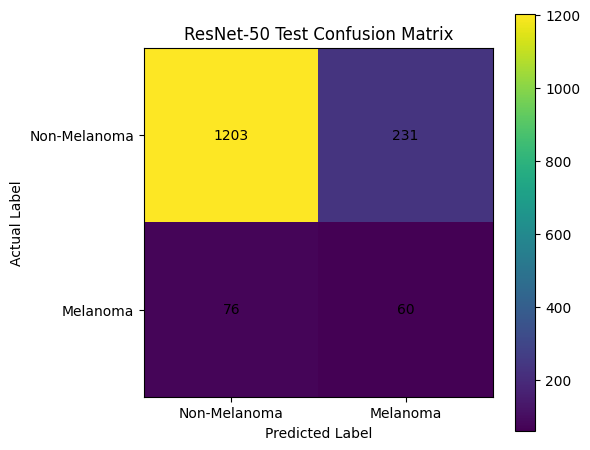

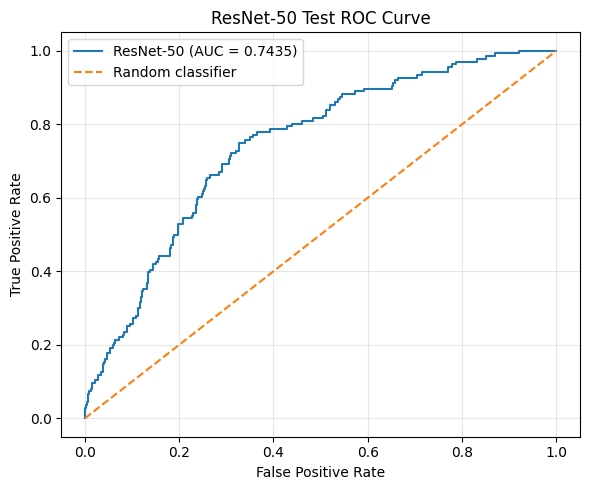


TESTING COMPLETED
Results saved in:
/content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT/implement/results/resnet50_30_epochs/testing_results

Saved files:
- confusion_matrix.csv
- confusion_matrix.png
- roc_curve.png
- test_metrics.csv
- test_predictions.csv


In [ ]:

# ============================================================
# RESNET-50 MELANOMA CLASSIFICATION - COMPLETE TESTING
# ============================================================

import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from torchvision import models, transforms
from torch.utils.data import Dataset, DataLoader
from PIL import Image

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

# ============================================================
# 1. GOOGLE DRIVE
# ============================================================

from google.colab import drive

if not os.path.exists("/content/drive/MyDrive"):
    drive.mount("/content/drive")

# ============================================================
# 2. PATHS AND SETTINGS
# ============================================================

BASE_PATH = "/content/drive/MyDrive/MELANOMA/PREDICTIVE PROJECT"

CSV_PATH = os.path.join(
    BASE_PATH,
    "data",
    "MILK10k_Prepared",
    "MILK10k_final_dataset.csv"
)

MODEL_PATH = os.path.join(
    BASE_PATH,
    "implement",
    "results",
    "resnet50_30_epochs",
    "resnet50_30_epochs_best.pth"
)

RESULTS_DIR = os.path.join(
    BASE_PATH,
    "implement",
    "results",
    "resnet50_30_epochs",
    "testing_results"
)

os.makedirs(RESULTS_DIR, exist_ok=True)

IMAGE_SIZE = 224
BATCH_SIZE = 16
THRESHOLD = 0.5

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)

if not os.path.exists(CSV_PATH):
    raise FileNotFoundError(f"CSV not found: {CSV_PATH}")

if not os.path.exists(MODEL_PATH):
    raise FileNotFoundError(f"Model not found: {MODEL_PATH}")

print("Model checkpoint found.")

# ============================================================
# 3. LOAD TEST DATA
# ============================================================

df = pd.read_csv(CSV_PATH)

print("CSV columns:", df.columns.tolist())

required_columns = {
    "lesion_id", "image_path", "label", "split"
}

missing = required_columns - set(df.columns)

if missing:
    raise ValueError(f"Missing CSV columns: {missing}")

print("\nAvailable data splits:")
print(df["split"].value_counts(dropna=False))

test_df = df[
    df["split"].astype(str).str.strip().str.lower().isin(
        ["test", "testing"]
    )
].copy()

if test_df.empty:
    raise ValueError("No test images found in the CSV.")

test_df["label"] = pd.to_numeric(
    test_df["label"], errors="raise"
).astype(int)

if not test_df["label"].isin([0, 1]).all():
    raise ValueError("Labels must be 0 or 1.")

print("\nTest images:", len(test_df))
print("Test label counts:")
print(test_df["label"].value_counts().sort_index())
print("Unique test lesions:", test_df["lesion_id"].nunique())

# ============================================================
# 4. RESOLVE IMAGE PATHS
# ============================================================

def resolve_path(path):
    path = str(path)

    if os.path.isfile(path):
        return path

    candidates = [
        os.path.join(BASE_PATH, path),
        os.path.join(BASE_PATH, "data", path),
        os.path.join(
            "/content/drive/MyDrive/MELANOMA", path
        )
    ]

    for candidate in candidates:
        if os.path.isfile(candidate):
            return candidate

    raise FileNotFoundError(
        f"Image file not found: {path}"
    )

test_df["image_path"] = test_df["image_path"].apply(
    resolve_path
)

print("\nAll test image paths found.")

# ============================================================
# 5. IMAGE TRANSFORM
# Use the same normalization as training.
# ============================================================

test_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# ============================================================
# 6. TEST DATASET AND DATALOADER
# ============================================================

class MelanomaTestDataset(Dataset):

    def __init__(self, dataframe, transform):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        with Image.open(row["image_path"]) as img:
            image = self.transform(img.convert("RGB"))

        label = int(row["label"])

        return (
            image,
            torch.tensor(label, dtype=torch.float32)
        )

test_dataset = MelanomaTestDataset(
    test_df,
    test_transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

print("Test batches:", len(test_loader))

# ============================================================
# 7. CREATE RESNET-50 MODEL
# ============================================================

model = models.resnet50(weights=None)

model.fc = nn.Linear(
    model.fc.in_features,
    1
)

# ============================================================
# 8. LOAD CHECKPOINT - PYTORCH 2.6 FIX
# Only use weights_only=False for a trusted checkpoint.
# This is your own saved training checkpoint.
# ============================================================

checkpoint = torch.load(
    MODEL_PATH,
    map_location=DEVICE,
    weights_only=False
)

if isinstance(checkpoint, dict):
    if "model_state_dict" in checkpoint:
        state_dict = checkpoint["model_state_dict"]

    elif "state_dict" in checkpoint:
        state_dict = checkpoint["state_dict"]

    elif (
        "model" in checkpoint
        and isinstance(checkpoint["model"], dict)
    ):
        state_dict = checkpoint["model"]

    else:
        state_dict = checkpoint
else:
    raise ValueError(
        "Unsupported checkpoint format."
    )

# Remove DataParallel prefix if present.
state_dict = {
    key.replace("module.", "", 1)
    if key.startswith("module.") else key: value
    for key, value in state_dict.items()
}

model.load_state_dict(state_dict, strict=True)

model = model.to(DEVICE)
model.eval()

print("\nResNet-50 checkpoint loaded successfully.")

# ============================================================
# 9. RUN TESTING
# ============================================================

y_true = []
y_prob = []

print("\nTesting started...")

with torch.inference_mode():

    for batch_number, (images, labels) in enumerate(
        test_loader, start=1
    ):

        images = images.to(
            DEVICE,
            non_blocking=True
        )

        logits = model(images)

        if logits.ndim == 2 and logits.shape[1] == 1:
            logits = logits.squeeze(1)
        elif logits.ndim != 1:
            raise ValueError(
                f"Unexpected output shape: {logits.shape}"
            )

        probabilities = torch.sigmoid(logits)

        y_true.extend(labels.numpy().tolist())

        y_prob.extend(
            probabilities.cpu().numpy().tolist()
        )

        if batch_number % 10 == 0:
            print(
                f"Processed {batch_number}/"
                f"{len(test_loader)} batches"
            )

y_true = np.asarray(y_true, dtype=int)
y_prob = np.asarray(y_prob, dtype=float)

y_pred = (
    y_prob >= THRESHOLD
).astype(int)

print("\nTesting inference completed.")

# ============================================================
# 10. CALCULATE TEST METRICS
# ============================================================

accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true, y_pred, zero_division=0
)

recall = recall_score(
    y_true, y_pred, zero_division=0
)

f1 = f1_score(
    y_true, y_pred, zero_division=0
)

if len(np.unique(y_true)) == 2:
    auc = roc_auc_score(y_true, y_prob)
else:
    auc = float("nan")

print("\n" + "=" * 55)
print("RESNET-50 FINAL TEST RESULTS")
print("=" * 55)

print("Test images:", len(y_true))
print(f"Accuracy : {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")
print(f"ROC-AUC  : {auc:.4f}")
print("Threshold:", THRESHOLD)

print("\nClassification Report:")

print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["Non-Melanoma", "Melanoma"],
    zero_division=0
))

# ============================================================
# 11. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1]
)

print("Confusion Matrix:")
print(cm)

plt.figure(figsize=(6, 5))
plt.imshow(cm, interpolation="nearest")
plt.title("ResNet-50 Test Confusion Matrix")
plt.colorbar()

plt.xticks(
    [0, 1],
    ["Non-Melanoma", "Melanoma"]
)

plt.yticks(
    [0, 1],
    ["Non-Melanoma", "Melanoma"]
)

for i in range(2):
    for j in range(2):
        plt.text(
            j, i, str(cm[i, j]),
            ha="center", va="center"
        )

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()

plt.savefig(
    os.path.join(
        RESULTS_DIR,
        "confusion_matrix.png"
    ),
    dpi=300
)

plt.show()

# ============================================================
# 12. ROC CURVE
# ============================================================

if len(np.unique(y_true)) == 2:

    fpr, tpr, _ = roc_curve(y_true, y_prob)

    plt.figure(figsize=(6, 5))

    plt.plot(
        fpr, tpr,
        label=f"ResNet-50 (AUC = {auc:.4f})"
    )

    plt.plot(
        [0, 1], [0, 1],
        linestyle="--",
        label="Random classifier"
    )

    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ResNet-50 Test ROC Curve")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()

    plt.savefig(
        os.path.join(
            RESULTS_DIR,
            "roc_curve.png"
        ),
        dpi=300
    )

    plt.show()

# ============================================================
# 13. SAVE PREDICTIONS AND METRICS
# ============================================================

image_results = test_df.reset_index(drop=True).copy()

image_results["true_label"] = y_true
image_results["melanoma_probability"] = y_prob
image_results["predicted_label"] = y_pred

image_results.to_csv(
    os.path.join(
        RESULTS_DIR,
        "test_predictions.csv"
    ),
    index=False
)

metrics = pd.DataFrame([{
    "model": "ResNet-50",
    "test_images": len(y_true),
    "accuracy": accuracy,
    "precision": precision,
    "recall": recall,
    "f1_score": f1,
    "roc_auc": auc,
    "threshold": THRESHOLD
}])

metrics.to_csv(
    os.path.join(
        RESULTS_DIR,
        "test_metrics.csv"
    ),
    index=False
)

pd.DataFrame(
    cm,
    index=["Actual Non-Melanoma", "Actual Melanoma"],
    columns=["Predicted Non-Melanoma", "Predicted Melanoma"]
).to_csv(
    os.path.join(
        RESULTS_DIR,
        "confusion_matrix.csv"
    )
)

# ============================================================
# 14. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 55)
print("TESTING COMPLETED")
print("=" * 55)

print("Results saved in:")
print(RESULTS_DIR)

print("\nSaved files:")
for filename in sorted(os.listdir(RESULTS_DIR)):
    print("-", filename)
